# **Global Solution 2026.2 - HelmCare: risco de sinistros graves com motocicletas em São Paulo**

Professor Danilo Rodrigues de Assis Elias - Inteligência Artificial e Machine Learning

---

### **Integrante (3ESPW):**

- Renan Dias Utida - RM 558540

---

### **Informações do Projeto:**

- **Desafio:** Global Solution 2026.2, tema CitizenTech (Engenharia de Software, 3º ano, FIAP Paulista)
- **CitizenTech:** HelmCare, *"Do risco ao resgate, cuidado em cada corrida."*
- **Cidadão beneficiado:** motociclistas que trabalham com entregas por aplicativo na cidade de São Paulo
- **Papel desta parte:** o modelo alimenta o componente `sinistro` (50%) do Índice de Risco do Turno, calculado pelo Serviço de Risco
- **Repositório:** https://github.com/renan-utida/helmcare (pasta `ml/`)
- **Entrega:** 19/11/2026

### **Objetivo:**

Transformar o problema do HelmCare em uma pergunta de Machine Learning e respondê-la com dados reais e públicos: estimar quantos sinistros graves com motocicletas são esperados em cada hora na cidade de São Paulo, dados o calendário e as condições do tempo. O notebook percorre o ciclo completo (preparação dos dados, treino com diferentes hiperparâmetros e avaliação em treino e teste) e termina traduzindo o resultado para o entregador.

# **Descrição do Desafio**

### **Inteligência Artificial & Machine Learning · Global Solution 2026.2 (CitizenTech)**

#### **Conceito da atividade.** Transformar o problema da CitizenTech em uma pergunta de Machine Learning e respondê-la com dados reais e públicos sobre a cidade: INMET, Metrô SP, Infosiga SP, SP156, IBGE, entre outros.

#### **Objetivo.** Percorrer o ciclo completo de ML: preparar os dados, treinar um modelo (XGBoost, Random Forest, MLP, LSTM ou KMeans + PCA) com diferentes hiperparâmetros, avaliá-lo em treino e teste e concluir o que o resultado significa para o cidadão.

#### **O percurso**

| Etapa | O que fazer |
|---|---|
| 01. Problema e dados reais | Escolher o problema da CitizenTech, transformá-lo em uma pergunta de ML e pesquisar dados reais e públicos. Documentar fonte, link e período. |
| 02. Modelo e preparação | Escolher um modelo: XGBoost, Random Forest, MLP, LSTM ou KMeans (+PCA). Limpar os dados e dividir em treino e teste. |
| 03. Treino e avaliação | Testar ao menos 10 combinações de 3 hiperparâmetros, com validação cruzada só no treino, e avaliar com métricas adequadas. |
| 04. Resultados e conclusão | Mostrar as métricas de treino e teste lado a lado, com gráficos, e discutir overfitting. Concluir o que o resultado significa para o cidadão. |

#### **Entregáveis**

- Repositório GitHub: pasta `ml/` com o notebook executado, `dados/README.md` e `requirements.txt`.
- Relatório `RELATORIO_ML.md`, do problema à conclusão (o enunciado indica de 2 a 4 páginas, e o quadro de critérios cita 2 páginas).
- Vídeo de até 5 minutos no YouTube (não listado).

Um integrante envia no Teams os links do repositório e do vídeo até 19/11, às 23h55. **Dados simulados não são aceitos.**

#### **Pontuação (10,0)**

| Critério | Pontos |
|---|---|
| Problema e dados reais | 2,0 |
| Escolha justificada do modelo | 1,0 |
| Preparação e divisão treino/teste | 2,0 |
| Treino com diferentes parâmetros | 2,0 |
| Resultados em treino e teste | 2,0 |
| Conclusão e leitura para o cidadão | 1,0 |

# **Solução Proposta**

O HelmCare atua em três momentos da vida do entregador: **prevenir** (antes do turno), **socorrer** (durante a queda) e **proteger** (depois dela). Este notebook constrói a parte da prevenção que depende de dados: o componente `sinistro` do **Índice de Risco do Turno**.

| Componente do índice | Peso | Fonte |
|---|---|---|
| `sinistro`: sinistros graves esperados nas horas do turno | 50% | **Modelo deste notebook** (Infosiga + INMET) |
| `chuva`: chuva prevista no turno | 25% | Previsão do tempo |
| `calor`: índice de calor | 25% | Previsão do tempo + sensor DHT22 do capacete |

O modelo é treinado aqui e exportado para a pasta `ml/modelo/`. De lá, o Serviço de Risco (FastAPI, disciplina de SOA) o carrega para responder ao `POST /indice-turno` (Contrato de Integração v1.1, seção 8.1).

### **Pergunta de Machine Learning**

> Quantos sinistros graves com motocicletas são esperados na cidade de São Paulo em cada hora local (0 a 23), dados o calendário (hora, dia da semana, mês e feriado) e as condições do tempo naquela hora (chuva, temperatura e umidade)?

### **Dados reais e públicos**

| Dado | Fonte | Link | Período usado | Uso no projeto |
|---|---|---|---|---|
| Sinistros de trânsito: sinistros, pessoas (vítimas) e veículos (versão 3.1, atualizada em 19/10/2026) | Infosiga SP (Detran-SP), licença CC BY 4.0 | https://infosiga.detran.sp.gov.br/ | 2019 a 2025 | Variável-alvo e trechos críticos |
| Dados meteorológicos horários da estação automática A701 (São Paulo, Mirante de Santana) | INMET (Instituto Nacional de Meteorologia) | https://portal.inmet.gov.br/dadoshistoricos | 2019 a 2025 | Chuva, temperatura e umidade |

Os dados foram baixados em 07/11/2026. O período começa em 2019 porque só a partir desse ano o Infosiga registra também os sinistros não fatais, e termina em 2025 porque 2026 ainda está incompleto. O passo a passo do download e os tratamentos aplicados estão em `dados/README.md`.

### **Roteiro**

- **Item 0:** Configuração do ambiente e reprodutibilidade
- **Item 1:** Infosiga: leitura e funil de filtros
- **Item 2:** Definição de sinistro grave e da variável-alvo
- **Item 3:** INMET: leitura, faltantes e conversão de fuso
- **Item 4:** Base horária: grade completa de horas, calendário, feriados e junção com o tempo
- **Item 5:** Análise exploratória
- **Item 6:** Escolha justificada do modelo, variáveis e divisão treino/teste
- **Item 7:** Linhas de base
- **Item 8:** Treino com diferentes hiperparâmetros (validação cruzada só no treino)
- **Item 9:** Resultados em treino e teste, overfitting e efeito do tempo
- **Item 10:** Exportação dos artefatos para o Serviço de Risco
- **Item 11:** Conclusão e leitura para o entregador
- **Item 12:** Cobertura da rubrica e dos entregáveis

## **Introdução: problema, pergunta e hipótese**

### **Problema**

Em 2025, a cidade de São Paulo registrou 1.034 mortes no trânsito, o maior número desde 2015, e os motociclistas foram o maior grupo de vítimas, com 475 mortes. Entre janeiro e agosto de 2026, motos estiveram envolvidas em 67,3% dos sinistros graves ou fatais da cidade (dados do Infosiga SP divulgados pela imprensa; fontes no Item 12). O Item 2 confere o número de motociclistas mortos em 2025 com os dados deste notebook.

Por trás desses números está o entregador de aplicativo, que passa o turno inteiro exposto ao trânsito, à chuva e ao calor, sem nenhuma informação sobre o risco do horário em que vai trabalhar.

### **Pergunta**

Quantos sinistros graves com motocicletas são esperados na cidade de São Paulo em cada hora local (0 a 23), dados o calendário e as condições do tempo naquela hora? A "faixa horária" da Ficha da CitizenTech corresponde, aqui, a uma hora local.

### **Tipo de problema**

Regressão de contagem. O alvo é um número inteiro, não negativo e pequeno em cada hora, porque sinistros graves são raros quando olhados hora a hora. Para o índice, o que interessa é a **quantidade esperada** em cada hora, e não acertar o número exato de uma hora específica.

### **Hipótese inicial.**

- **H1 (horário):** a quantidade esperada de sinistros graves varia muito ao longo do dia. É maior nos horários de mais circulação e de entregas e menor de madrugada.
- **H2 (chuva):** na mesma hora e no mesmo dia da semana, horas com chuva têm mais sinistros graves do que horas secas.
- **H3 (temperatura e umidade):** têm efeito menor que o da chuva.
- **H4 (tamanho do ganho):** medido hora a hora, o tempo acrescenta pouco ao que o calendário já explica, porque cada hora tem poucos casos e muito acaso. O efeito deve aparecer melhor em médias.

Os resultados testam essas hipóteses, e a conclusão (Item 11) diz o que foi confirmado e o que não foi.

### **Limite conhecido desde o início**

A quantidade de sinistros também reflete quantas motos estão circulando (exposição). Os dados públicos não trazem esse volume por hora, então o modelo mede quando os sinistros graves acontecem, e não o perigo de cada viagem. Esse limite volta na conclusão.

### **Protocolo experimental**

As regras abaixo foram definidas antes de olhar os resultados e valem para todo o notebook.

| Escolha | Decisão | Justificativa |
|---|---|---|
| Unidade de análise | Uma hora local (0 a 23) de um dia, na cidade inteira | É o que o Serviço de Risco consulta (Contrato v1.1, seção 8.1) e a menor granularidade do INMET |
| Variável-alvo | Quantidade de sinistros graves com motocicleta na hora. Proposta: sinistro com pelo menos uma moto e pelo menos uma vítima com lesão grave ou fatal. Decisão final no Item 2 | Critério "graves ou fatais" das estatísticas de segurança viária. **Regra prévia:** se em menos de 80% desses sinistros a vítima grave ou fatal estiver na moto, o alvo passa a ser "sinistros com vítima grave ou fatal na moto", que é o risco do entregador |
| Período e local | 2019 a 2025, município de São Paulo (IBGE 3550308) | Sinistros não fatais só a partir de 2019; 2026 está incompleto |
| Horas sem sinistro | Entram com alvo 0 (grade completa de 61.368 horas) | Sem elas, o modelo nunca vê o "nada aconteceu" e superestima o risco |
| Fuso horário | INMET convertido de UTC para `America/Sao_Paulo` | Até 16/02/2019 ainda havia horário de verão (UTC-2); uma conversão fixa de 3 horas erraria esse período |
| Horas sem dados do tempo | Excluídas do treino e do teste, com a quantidade registrada (confirmado no Item 4) | Inventar a chuva de uma hora atrapalharia justamente o efeito que o modelo precisa aprender |
| Variáveis de entrada | Hora, dia da semana, mês, feriado, chuva (mm/h), temperatura (°C) e umidade (%) | Somente o que o Serviço de Risco monta a partir do `POST /indice-turno` (Contrato v1.1). Códigos inteiros, porque árvores não precisam de one-hot nem de padronização |
| Ano | Fora do modelo. Usado só na análise exploratória e no diagnóstico do teste | Não consta das entradas do Contrato; árvores não extrapolam (em 2026, o modelo trataria tudo como o último ano visto); e a tendência anual mistura mudança de risco com mudança de registro. O possível viés de nível em 2025 é medido no Item 9 |
| Feriados | Nacionais e estaduais de SP (biblioteca `holidays`) e municipais da capital (25/01, Corpus Christi e 20/11). Regra final, incluindo o Carnaval, no Item 4 | A regra e a lista explícita de datas vão para o `metadados_modelo.json`, para o Serviço de Risco reproduzir exatamente |
| Divisão treino e teste | Treino: 2019 a 2024. Teste: 2025 inteiro, usado uma única vez, no fim | Divisão temporal: simula o uso real e não usa o futuro para prever o passado |
| Validação cruzada | 5 dobras expansivas por ano, só no treino (treina em 2019 e valida em 2020, e assim por diante, até treinar de 2019 a 2023 e validar em 2024) | Cada dobra valida um ano completo e respeita a ordem do tempo |
| Modelo | XGBoost (`XGBRegressor`) com objetivo `count:poisson` | Justificativa completa no Item 6 |
| Hiperparâmetros | `max_depth` {3, 5, 7} × `learning_rate` {0,03; 0,1; 0,3} × `n_estimators` {200, 400, 800} = 27 combinações | Acima do mínimo de 10. A grade vai de modelos simples demais a complexos demais, para que sub-ajuste e overfitting apareçam |
| Métrica de seleção | Deviance de Poisson média na validação cruzada | Métrica própria para contagens: premia prever a média esperada, que é o que o índice usa |
| Métricas reportadas | MAE, RMSE, deviance de Poisson e D² (fração da deviance explicada), em treino, validação e teste | MAE e RMSE são fáceis de explicar ("erro médio, em sinistros por hora"); o D² mostra quanto o modelo explica além de uma média constante |
| Linhas de base | Média geral, média por hora e média por hora e dia da semana, calculadas só no treino | O modelo só vale a pena se superar a média histórica por hora |
| Ablação | O mesmo XGBoost sem as variáveis do tempo | Mede quanto chuva, temperatura e umidade acrescentam além do calendário |
| Modelo exportado | Retreinado de 2019 a 2025 com os hiperparâmetros escolhidos | Depois da avaliação, usa todos os dados disponíveis |
| Dados pessoais | Nenhum no modelo; a base horária versionada só tem contagens agregadas e dados do tempo | Contrato v1.1 (seção 10) e combinados da GS |
| Reprodutibilidade | Semente 42, cache em parquet e versões das bibliotecas registradas | O `requirements.txt` e o `metadados_modelo.json` saem dessas versões |

## **Item 0: Configuração do ambiente e reprodutibilidade**

Este item prepara o ambiente antes de qualquer leitura de dados:

- **0.1** bibliotecas, versões, semente e constantes do estudo (período, município e fuso);
- **0.2** acesso ao Google Drive, caminhos do projeto e extração dos arquivos brutos;
- **0.3** inspeção rápida de cada arquivo (codificação, separador e colunas), para que o Item 1 leia só o necessário.

### **Escolhas e justificativas**

| Escolha | Justificativa |
|---|---|
| Ambiente de execução com CPU, sem GPU | O modelo é um XGBoost sobre uma tabela de cerca de 61 mil linhas e 7 variáveis, que treina rápido em CPU. Sem GPU, o notebook não depende da cota de GPU do Colab |
| Dados brutos no Drive, compactados (`brutos.zip`, 144 MB), e extraídos no disco local do Colab a cada sessão | Os CSVs ocupam cerca de 1 GB: compactados, sobem mais rápido para o Drive, e a leitura no disco local é mais rápida do que pelo Drive |
| Resultados intermediários salvos em parquet no Drive (`dados/processados/`) | O disco local é apagado quando a sessão termina. Com o cache, uma queda do Colab não obriga a ler os CSVs de novo |
| Caminhos definidos em variáveis | O mesmo notebook roda no Colab e na pasta `ml/` do repositório, sem editar o código |
| Constantes do estudo definidas uma única vez | Período, município, fuso e semente ficam num só lugar, e todos os itens usam os mesmos valores |

**Antes de executar:** Ambiente de execução → Alterar o tipo de ambiente de execução → CPU.

### **0.1 Bibliotecas, versões, semente e constantes do estudo**

A célula importa as bibliotecas, fixa a semente e define as constantes do protocolo: período (2019 a 2025), anos de treino e de teste, código IBGE da capital e fuso oficial. A biblioteca `holidays`, usada no Item 4, é instalada só se o ambiente não a tiver. As versões impressas vão para o `requirements.txt` e para o `metadados_modelo.json`.

In [2]:
# Bibliotecas, versões, sementes e constantes do estudo

import os
import sys
import json
import time
import random
import re
import shutil
import zipfile
import platform
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost as xgb
import pyarrow                      # leitura e escrita de parquet (cache das etapas pesadas)
import psutil                       # memória disponível no ambiente

# A biblioteca holidays (feriados) é usada no Item 4; instala só se o ambiente não tiver
try:
    import holidays
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "holidays"], check=True)
    import holidays

warnings.filterwarnings("ignore", category=FutureWarning)

# Reprodutibilidade: mesma semente em todo o notebook
# ---------------------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Recorte do estudo (definido no protocolo da Introdução)
# ---------------------------------------------------------------------------
ANO_INICIO, ANO_FIM = 2019, 2025          # Infosiga com sinistros não fatais a partir de 2019; 2026 incompleto
ANOS_TREINO = list(range(2019, 2025))     # 2019 a 2024
ANO_TESTE = 2025                          # ano inteiro que o modelo nunca vê no treino
COD_IBGE_SP = 3550308                     # código IBGE do município de São Paulo (capital)
FUSO_LOCAL = "America/Sao_Paulo"          # fuso oficial, com o horário de verão que ainda valia no início de 2019

# Exibição de tabelas e gráficos
# ---------------------------------------------------------------------------
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Versões das bibliotecas (vão para o requirements.txt e para o metadados_modelo.json)
# ---------------------------------------------------------------------------
VERSOES = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "xgboost": xgb.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "pyarrow": pyarrow.__version__,
    "holidays": holidays.__version__,
}

print("=" * 70)
print("AMBIENTE")
print("=" * 70)
for nome, versao in VERSOES.items():
    print(f"{nome:<14s} {versao}")

memoria_gb = psutil.virtual_memory().total / 1024**3
tem_gpu = shutil.which("nvidia-smi") is not None
print("-" * 70)
print(f"Núcleos de CPU: {os.cpu_count()} | Memória RAM: {memoria_gb:.1f} GB")
print(f"GPU disponível: {'sim' if tem_gpu else 'não'} (este projeto não precisa de GPU)")
print("-" * 70)
print(f"Período do estudo: {ANO_INICIO} a {ANO_FIM} | treino: {ANOS_TREINO[0]} a {ANOS_TREINO[-1]} | teste: {ANO_TESTE}")
print(f"Município: São Paulo (IBGE {COD_IBGE_SP}) | fuso: {FUSO_LOCAL} | semente: {SEED}")

AMBIENTE
python         3.13.18
pandas         2.2.3
numpy          2.4.6
scikit-learn   1.6.1
xgboost        3.4.1
matplotlib     3.10.0
seaborn        0.13.2
pyarrow        23.0.1
holidays       0.108
----------------------------------------------------------------------
Núcleos de CPU: 2 | Memória RAM: 12.7 GB
GPU disponível: não (este projeto não precisa de GPU)
----------------------------------------------------------------------
Período do estudo: 2019 a 2025 | treino: 2019 a 2024 | teste: 2025
Município: São Paulo (IBGE 3550308) | fuso: America/Sao_Paulo | semente: 42


### **0.2 Google Drive, caminhos e arquivos brutos**

Estrutura esperada no Drive: `Meu Drive/helmcare_ml/`, com este notebook e o arquivo `dados/brutos.zip`.

A célula:

1. monta o Google Drive (na primeira vez, o Colab pede autorização);
2. cria as pastas `dados/processados/`, `modelo/` e `figuras/`, que espelham a pasta `ml/` do repositório;
3. extrai o `brutos.zip` no disco local do Colab, só se os CSVs ainda não estiverem lá nesta sessão;
4. localiza os arquivos em qualquer nível do zip (não importa como ele foi montado) e ignora arquivos ocultos do macOS;
5. confere se estão todos lá: 3 arquivos de cada tabela do Infosiga e os 7 anos da estação A701. O filtro pelo nome garante que a estação S701 (Angélica, MS), de código parecido, nunca entre.

In [3]:
# Google Drive, caminhos do projeto e arquivos brutos

EM_COLAB = "google.colab" in sys.modules

if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/helmcare_ml")   # espelho da pasta ml/ do repositório
    DIR_BRUTOS = Path("/content/dados_brutos")               # disco local do Colab: leitura mais rápida que o Drive
else:
    BASE_DIR = Path.cwd()                                    # execução local: o notebook fica dentro de ml/
    DIR_BRUTOS = BASE_DIR / "dados" / "brutos"

ZIP_BRUTOS = BASE_DIR / "dados" / "brutos.zip"
DIR_PROCESSADOS = BASE_DIR / "dados" / "processados"        # cache das etapas pesadas e base horária final
DIR_MODELO = BASE_DIR / "modelo"                             # artefatos para o Serviço de Risco (Contrato, seção 8.1)
DIR_FIGURAS = BASE_DIR / "figuras"                           # gráficos usados no RELATORIO_ML.md

for pasta in (DIR_PROCESSADOS, DIR_MODELO, DIR_FIGURAS):
    pasta.mkdir(parents=True, exist_ok=True)


def listar_csvs(pasta: Path) -> list:
    """Lista todos os CSV dentro da pasta (em qualquer nível), ignorando arquivos ocultos do macOS."""
    if not pasta.exists():
        return []
    return sorted(p for p in pasta.rglob("*")
                  if p.is_file() and p.suffix.lower() == ".csv"
                  and not p.name.startswith("._") and "__MACOSX" not in p.parts)


print("=" * 70)
print("ARQUIVOS BRUTOS")
print("=" * 70)
print(f"Ambiente: {'Google Colab' if EM_COLAB else 'execução local'}")
print(f"Pasta base: {BASE_DIR}")

# O disco local do Colab é apagado quando a sessão termina: o zip é extraído uma vez por sessão
if not listar_csvs(DIR_BRUTOS):
    if not ZIP_BRUTOS.exists():
        raise FileNotFoundError(f"Não encontrei os CSVs em {DIR_BRUTOS} nem o arquivo {ZIP_BRUTOS}.")
    t0 = time.time()
    with zipfile.ZipFile(ZIP_BRUTOS) as z:
        membros = [m for m in z.namelist()
                   if "__MACOSX" not in m and not Path(m).name.startswith("._")]
        z.extractall(DIR_BRUTOS, members=membros)
    print(f"brutos.zip ({ZIP_BRUTOS.stat().st_size / 1024**2:.0f} MB) extraído em {time.time() - t0:.1f} s")
else:
    print("CSVs já disponíveis nesta sessão (extração pulada)")

todos_csvs = listar_csvs(DIR_BRUTOS)

# Infosiga: 3 arquivos de cada tabela (2015-2021, 2022-2024 e 2025-2026)
ARQ_SINISTROS = [p for p in todos_csvs if p.name.lower().startswith("sinistros_")]
ARQ_PESSOAS = [p for p in todos_csvs if p.name.lower().startswith("pessoas_")]
ARQ_VEICULOS = [p for p in todos_csvs if p.name.lower().startswith("veiculos_")]

# INMET: um arquivo por ano, só da estação A701 (Mirante de Santana); a S701 (Angélica, MS) fica de fora
ARQ_INMET = {}
for p in todos_csvs:
    nome = p.name.upper()
    if "A701" in nome and "MIRANTE" in nome:
        ano = int(re.search(r"01-01-(\d{4})", nome).group(1))   # ano lido do nome do arquivo
        ARQ_INMET[ano] = p
ARQ_INMET = dict(sorted(ARQ_INMET.items()))

# Conferência: o que era esperado contra o que foi encontrado
conferencia = pd.DataFrame([
    {"grupo": "Infosiga: sinistros", "esperado": 3, "encontrado": len(ARQ_SINISTROS)},
    {"grupo": "Infosiga: pessoas", "esperado": 3, "encontrado": len(ARQ_PESSOAS)},
    {"grupo": "Infosiga: veículos", "esperado": 3, "encontrado": len(ARQ_VEICULOS)},
    {"grupo": "INMET A701 (2019 a 2025)", "esperado": 7,
     "encontrado": sum(a in ARQ_INMET for a in range(ANO_INICIO, ANO_FIM + 1))},
])
conferencia["ok"] = conferencia["esperado"] == conferencia["encontrado"]
display(conferencia)

arquivos = ARQ_SINISTROS + ARQ_PESSOAS + ARQ_VEICULOS + list(ARQ_INMET.values())
tabela_arquivos = pd.DataFrame({
    "arquivo": [p.name for p in arquivos],
    "tamanho (MB)": [f"{p.stat().st_size / 1024**2:,.1f}" for p in arquivos],
})
display(tabela_arquivos)
total_mb = sum(p.stat().st_size for p in arquivos) / 1024**2
n_pdfs = sum(1 for p in DIR_BRUTOS.rglob("*.pdf") if not p.name.startswith("._"))
print(f"Total: {len(arquivos)} CSVs, {total_mb:,.0f} MB | PDFs da documentação do Infosiga: {n_pdfs} (esperado: 4)")

if not conferencia["ok"].all():
    raise RuntimeError("Faltam arquivos. Confira a estrutura descrita em dados/README.md.")
print("Todos os arquivos esperados foram encontrados.")

Mounted at /content/drive
ARQUIVOS BRUTOS
Ambiente: Google Colab
Pasta base: /content/drive/MyDrive/helmcare_ml
brutos.zip (144 MB) extraído em 15.2 s


,grupo,esperado,encontrado,ok
0,Infosiga: sinistros,3,3,True
1,Infosiga: pessoas,3,3,True
2,Infosiga: veículos,3,3,True
3,INMET A701 (2019 a 2025),7,7,True


,arquivo,tamanho (MB)
0,sinistros_2015-2021.csv,135.4
1,sinistros_2022-2024.csv,150.6
2,sinistros_2025-2026.csv,77.1
3,pessoas_2015-2021.csv,156.4
4,pessoas_2022-2024.csv,167.7
5,pessoas_2025-2026.csv,77.4
6,veiculos_2015-2021.csv,56.7
7,veiculos_2022-2024.csv,60.4
8,veiculos_2025-2026.csv,27.3
9,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-201...,0.8


Total: 16 CSVs, 914 MB | PDFs da documentação do Infosiga: 4 (esperado: 4)
Todos os arquivos esperados foram encontrados.


### **0.3 Inspeção rápida dos arquivos**

Antes da leitura completa (Item 1), a célula lê só as primeiras linhas de cada arquivo para confirmar três coisas:

1. **Codificação:** o INMET usa Latin-1 e o Infosiga pode usar UTF-8. Ler com a codificação errada corrompe acentos, como em "SÃO PAULO".
2. **Colunas:** todas as colunas que os próximos itens usam, conforme os dicionários de dados do Infosiga (v1.8), precisam existir com esses nomes.
3. **INMET:** o código da estação (A701) e o formato das colunas de data e hora em cada ano, que o Item 3 precisa conhecer para converter o fuso.

In [4]:
# Inspeção rápida dos arquivos: codificação, separador e colunas

def detectar_codificacao(caminho: Path, amostra_bytes: int = 2_000_000) -> str:
    """Tenta decodificar o início do arquivo em UTF-8; se falhar, usa Latin-1 (padrão do INMET)."""
    with open(caminho, "rb") as f:
        bloco = f.read(amostra_bytes)
    if bloco.startswith(b"\xef\xbb\xbf"):     # UTF-8 com BOM: sem o "-sig", a 1ª coluna viria com um caractere invisível
        return "utf-8-sig"
    try:
        bloco.decode("utf-8")
        return "utf-8"
    except UnicodeDecodeError:
        return "latin-1"


# Colunas que os próximos itens vão usar, conforme os dicionários de dados do Infosiga (v1.8)
COLUNAS_NECESSARIAS = {
    "sinistros": ["id_sinistro", "tipo_registro", "data_sinistro", "ano_sinistro", "hora_sinistro",
                  "cod_ibge", "municipio", "logradouro", "latitude", "longitude", "tipo_via",
                  "qtd_motocicleta", "qtd_gravidade_fatal", "qtd_gravidade_grave", "qtd_gravidade_leve",
                  "qtd_gravidade_ileso", "qtd_gravidade_nao_disponivel", "tp_sinistro_primario"],
    "pessoas": ["id_sinistro", "id_pessoa", "id_veiculo", "cod_ibge", "ano_sinistro",
                "tipo_veiculo_vitima", "tipo_de_vitima", "modo_transporte_vitima", "gravidade_lesao"],
    "veiculos": ["id_sinistro", "id_veiculo", "tipo_veiculo", "ano_sinistro"],
}

print("=" * 70)
print("INFOSIGA: CODIFICAÇÃO E COLUNAS")
print("=" * 70)
CODIFICACAO = {}
linhas = []
for tabela, lista in [("sinistros", ARQ_SINISTROS), ("pessoas", ARQ_PESSOAS), ("veiculos", ARQ_VEICULOS)]:
    for p in lista:
        cod = detectar_codificacao(p)
        CODIFICACAO[p.name] = cod
        amostra = pd.read_csv(p, sep=";", encoding=cod, nrows=5, low_memory=False)
        faltando = [c for c in COLUNAS_NECESSARIAS[tabela] if c not in amostra.columns]
        linhas.append({"arquivo": p.name, "codificação": cod, "nº de colunas": amostra.shape[1],
                       "colunas necessárias ausentes": ", ".join(faltando) if faltando else "nenhuma"})
display(pd.DataFrame(linhas))

# Lista completa de colunas do primeiro arquivo de cada tabela (referência para o Item 1)
for tabela, lista in [("sinistros", ARQ_SINISTROS), ("pessoas", ARQ_PESSOAS), ("veiculos", ARQ_VEICULOS)]:
    amostra = pd.read_csv(lista[0], sep=";", encoding=CODIFICACAO[lista[0].name], nrows=3, low_memory=False)
    print(f"\n[{tabela}] {lista[0].name}: {amostra.shape[1]} colunas")
    print(", ".join(amostra.columns))

print()
print("=" * 70)
print("INMET: CABEÇALHO DA ESTAÇÃO E FORMATO DAS COLUNAS POR ANO")
print("=" * 70)
for ano, p in ARQ_INMET.items():
    cod = detectar_codificacao(p)
    CODIFICACAO[p.name] = cod
    with open(p, encoding=cod) as f:
        cabecalho = [next(f).strip() for _ in range(9)]       # 8 linhas da estação + linha de nomes
    estacao = {l.split(";")[0].rstrip(":"): (l.split(";") + [""])[1] for l in cabecalho[:8]}
    colunas = cabecalho[8].split(";")
    primeira = pd.read_csv(p, sep=";", skiprows=8, encoding=cod, nrows=1)
    print(f"{ano} | {cod} | código {estacao.get('CODIGO (WMO)', '?')} | "
          f"{len([c for c in colunas if c])} colunas | "
          f"data/hora: '{colunas[0]}' = {primeira.iloc[0, 0]!r}, '{colunas[1]}' = {primeira.iloc[0, 1]!r}")

INFOSIGA: CODIFICAÇÃO E COLUNAS


,arquivo,codificação,nº de colunas,colunas necessárias ausentes
0,sinistros_2015-2021.csv,latin-1,50,nenhuma
1,sinistros_2022-2024.csv,latin-1,50,nenhuma
2,sinistros_2025-2026.csv,latin-1,50,nenhuma
3,pessoas_2015-2021.csv,latin-1,31,nenhuma
4,pessoas_2022-2024.csv,latin-1,31,nenhuma
5,pessoas_2025-2026.csv,latin-1,31,nenhuma
6,veiculos_2015-2021.csv,latin-1,12,nenhuma
7,veiculos_2022-2024.csv,latin-1,12,nenhuma
8,veiculos_2025-2026.csv,latin-1,12,nenhuma



[sinistros] sinistros_2015-2021.csv: 50 colunas
id_sinistro, tipo_registro, data_sinistro, ano_sinistro, mes_sinistro, dia_sinistro, hora_sinistro, ano_mes_sinistro, dia_da_semana, turno, logradouro, numero_logradouro, tipo_via, tipo_local, latitude, longitude, cod_ibge, municipio, regiao_administrativa, administracao, conservacao, circunscricao, tp_sinistro_primario, qtd_pedestre, qtd_bicicleta, qtd_motocicleta, qtd_automovel, qtd_onibus, qtd_caminhao, qtd_veic_outros, qtd_veic_nao_disponivel, qtd_gravidade_fatal, qtd_gravidade_grave, qtd_gravidade_leve, qtd_gravidade_ileso, qtd_gravidade_nao_disponivel, tp_sinistro_atrop_pedestre, tp_sinistro_atrop_vitima_fora_veic, tp_sinistro_colisao_frontal, tp_sinistro_colisao_traseira, tp_sinistro_colisao_lateral, tp_sinistro_colisao_transversal, tp_sinistro_colisao_outros, tp_sinistro_choque, tp_sinistro_atrop_animal, tp_sinistro_capotamento, tp_sinistro_engavetamento, tp_sinistro_tombamento, tp_sinistro_outros, tp_sinistro_nao_disponivel

[pe

### **Discussão do Item 0**

#### **Ambiente**

O Colab rodou com Python 3.13.18, pandas 2.2.3, numpy 2.4.6, scikit-learn 1.6.1 e XGBoost 3.4.1, com 2 núcleos de CPU e 12,7 GB de RAM, sem GPU. A biblioteca `holidays` (0.108) já vinha instalada. Essas versões vão para o `requirements.txt` e para o `metadados_modelo.json`.

#### **Arquivos**

O `brutos.zip` (144 MB) foi extraído em 17,1 s e virou 16 CSVs com 914 MB no total: 3 arquivos de cada tabela do Infosiga e 7 anos da estação A701. Os 4 PDFs da documentação também estão lá. Nenhum arquivo faltou, e o filtro pelo nome garantiu que a estação S701 (Angélica, MS) não entrasse.

#### **Codificação**

Todos os arquivos, do Infosiga e do INMET, estão em **Latin-1**. Lidos como UTF-8, a leitura falharia ou os acentos sairiam corrompidos. Por isso a codificação detectada fica guardada no dicionário `CODIFICACAO` e é usada em todas as leituras seguintes.

#### **Colunas**

Os três períodos de cada tabela têm a mesma estrutura (50 colunas em sinistros, 31 em pessoas e 12 em veículos), e todas as colunas que o projeto usa existem com os nomes do dicionário de dados v1.8. Com isso, uma única rotina de leitura serve para os três arquivos de cada tabela, e o Item 1 lê só as colunas necessárias, o que reduz memória e tempo.

#### **INMET**

Os 7 anos têm o mesmo formato: 19 colunas, data em `aaaa/mm/dd` e hora no formato `0000 UTC`, com o código A701 no cabeçalho de todos. Isso confirma que os horários estão em UTC e permite uma única rotina de conversão de fuso no Item 3.

#### **Conclusão do Item 0**

O ambiente está validado e os dados estão completos e legíveis. O próximo passo é ler o Infosiga e aplicar o recorte do estudo.

## **Item 1: Infosiga: leitura e funil de filtros**

Este item lê as três tabelas do Infosiga e aplica o recorte do estudo: **cidade de São Paulo, de 2019 a 2025**. Cada etapa do filtro é contada, para que fique claro quantos registros sobram e por quê.

- **1.1** sinistros: leitura dos 3 arquivos, funil de filtros e conferências;
- **1.2** pessoas (vítimas) e veículos: só os registros ligados aos sinistros da capital no período.

### **Escolhas e justificativas**

| Escolha | Justificativa |
|---|---|
| Leitura em blocos de 500 mil linhas, filtrando bloco a bloco | Os arquivos têm o estado inteiro de 2014 a 2026. Filtrar durante a leitura mantém na memória só o que interessa |
| Só as colunas necessárias: 20 das 50 de sinistros, 10 das 31 de pessoas e 4 das 12 de veículos | Menos memória e menos tempo. Também é minimização de dados: das pessoas, entram só o tipo de vítima, o veículo em que estava e a gravidade da lesão. Sexo, idade, nacionalidade e grau de instrução ficam de fora. A profissão entra só para uma contagem agregada no Item 2 |
| Tudo lido como texto e convertido de forma explícita | Evita tipos diferentes entre blocos e arquivos (por exemplo, uma coluna de quantidade com campos vazios) e deixa claro como cada coluna foi tratada |
| Capital filtrada pelo código IBGE (3550308), não pelo nome | O código é numérico e único. O nome pode variar em acento e grafia |
| Duplicados removidos pelo `id_sinistro` | É a chave primária do sinistro (dicionário de dados), então ele não pode aparecer duas vezes |
| Pessoas e veículos filtrados pelo `id_sinistro` dos sinistros da capital | A tabela de veículos não tem código IBGE, e o `id_sinistro` liga as três tabelas (diagrama entidade relacionamento do Infosiga) |
| O cache guarda todos os sinistros da capital, com e sem moto | O Item 2 compara os dois grupos. O funil mostra quantos têm moto, mas nada é descartado antes da definição do alvo |
| Cache em parquet no Drive, com a opção `FORCAR_RELEITURA` | A leitura completa leva alguns minutos e só precisa ser feita uma vez |

### **1.1 Sinistros: leitura, funil de filtros e conferências**

A célula lê os três arquivos de sinistros em blocos e conta os registros em cada etapa: todos os registros, só os anos de 2019 a 2025, só a capital e sem duplicados. A última linha do funil mostra quantos desses sinistros envolvem pelo menos uma motocicleta (`qtd_motocicleta` ≥ 1).

Também converte as colunas para os tipos finais: a data vira data, as coordenadas viram números (o arquivo usa vírgula decimal) e é criado o indicador `com_moto`. No fim, confere o nome do município e o período das datas e mostra os sinistros com moto por ano e por tipo de registro (fatal, não fatal e notificação).

**Tempo estimado:** de 1 a 2 minutos na primeira vez. Nas próximas, a célula lê o cache em poucos segundos.

In [5]:
# Leitura do Infosiga (sinistros): funil de filtros e cache em parquet

FORCAR_RELEITURA = False          # True refaz a leitura dos CSVs mesmo que o cache já exista
TAM_BLOCO = 500_000               # linhas lidas por vez: a memória fica baixa mesmo com arquivos grandes

CACHE_SINISTROS = DIR_PROCESSADOS / "sinistros_capital_2019_2025.parquet"
CACHE_FUNIL = DIR_PROCESSADOS / "funil_infosiga.csv"

COLS_SINISTROS = COLUNAS_NECESSARIAS["sinistros"] + ["dia_da_semana", "turno"]
COLS_INT_SINISTROS = ["id_sinistro", "ano_sinistro", "cod_ibge", "qtd_motocicleta", "qtd_gravidade_fatal",
                      "qtd_gravidade_grave", "qtd_gravidade_leve", "qtd_gravidade_ileso",
                      "qtd_gravidade_nao_disponivel"]


def para_inteiro(s: pd.Series) -> pd.Series:
    """Converte texto em inteiro que aceita vazio (Int64); valores inválidos viram vazio."""
    return pd.to_numeric(s, errors="coerce").round().astype("Int64")


def para_decimal(s: pd.Series) -> pd.Series:
    """Converte texto em decimal, aceitando vírgula ou ponto como separador."""
    return pd.to_numeric(s.str.replace(",", ".", regex=False), errors="coerce")


def ler_sinistros_capital() -> tuple:
    """Lê os 3 arquivos em blocos, conta cada etapa do funil e guarda só a capital de 2019 a 2025."""
    contagem = {"total": 0, "periodo": 0, "capital": 0}
    partes = []
    for arq in ARQ_SINISTROS:
        t0, n_arquivo = time.time(), 0
        leitor = pd.read_csv(arq, sep=";", encoding=CODIFICACAO[arq.name], usecols=COLS_SINISTROS,
                             dtype=str, chunksize=TAM_BLOCO)
        for bloco in leitor:
            for c in COLS_INT_SINISTROS:
                bloco[c] = para_inteiro(bloco[c])
            no_periodo = bloco["ano_sinistro"].between(ANO_INICIO, ANO_FIM).fillna(False).astype(bool)
            na_capital = no_periodo & (bloco["cod_ibge"] == COD_IBGE_SP).fillna(False).astype(bool)
            n_arquivo += len(bloco)
            contagem["total"] += len(bloco)
            contagem["periodo"] += int(no_periodo.sum())
            contagem["capital"] += int(na_capital.sum())
            partes.append(bloco[na_capital])
        print(f"{arq.name:<26s} {n_arquivo:>10,} linhas lidas em {time.time() - t0:5.1f} s")
    return pd.concat(partes, ignore_index=True), contagem


print("=" * 70)
print("INFOSIGA: SINISTROS")
print("=" * 70)

if CACHE_SINISTROS.exists() and CACHE_FUNIL.exists() and not FORCAR_RELEITURA:
    sinistros = pd.read_parquet(CACHE_SINISTROS)
    funil = pd.read_csv(CACHE_FUNIL)
    print(f"Cache encontrado: {CACHE_SINISTROS.name} ({len(sinistros):,} sinistros). Leitura dos CSVs pulada.")
else:
    t_inicio = time.time()
    sinistros, contagem = ler_sinistros_capital()

    # Um mesmo sinistro não pode aparecer duas vezes (id_sinistro é a chave primária)
    n_duplicados = int(sinistros["id_sinistro"].duplicated().sum())
    sinistros = sinistros.drop_duplicates("id_sinistro").reset_index(drop=True)

    # Tipos finais: data, coordenadas e o indicador de motocicleta envolvida
    sinistros["data_sinistro"] = pd.to_datetime(sinistros["data_sinistro"], format="%d/%m/%Y", errors="coerce")
    sinistros["latitude"] = para_decimal(sinistros["latitude"])
    sinistros["longitude"] = para_decimal(sinistros["longitude"])
    sinistros["com_moto"] = (sinistros["qtd_motocicleta"].fillna(0) >= 1).astype(bool)

    funil = pd.DataFrame({
        "etapa": ["1. Todos os registros (estado inteiro, 2014 a 2026)",
                  f"2. Anos de {ANO_INICIO} a {ANO_FIM}",
                  "3. Município de São Paulo (IBGE 3550308)",
                  "4. Sem registros duplicados",
                  "5. Com pelo menos uma motocicleta envolvida"],
        "registros": [contagem["total"], contagem["periodo"], contagem["capital"],
                      len(sinistros), int(sinistros["com_moto"].sum())],
    })
    sinistros.to_parquet(CACHE_SINISTROS, index=False)
    funil.to_csv(CACHE_FUNIL, index=False)
    print(f"Duplicados removidos: {n_duplicados}")
    print(f"Leitura completa em {time.time() - t_inicio:.1f} s. Cache salvo em {CACHE_SINISTROS.name}")

# Funil: quantos registros sobram em cada etapa
funil["% da etapa anterior"] = (funil["registros"] / funil["registros"].shift(1) * 100).round(1)
print("\nFunil de filtros:")
display(funil.style.format({"registros": "{:,}", "% da etapa anterior": "{:.1f}%"}, na_rep="").hide(axis="index"))

# Conferências do recorte
print("Nome do município nos registros filtrados:", sinistros["municipio"].value_counts().to_dict())
print(f"Período das datas: {sinistros['data_sinistro'].min():%d/%m/%Y} a {sinistros['data_sinistro'].max():%d/%m/%Y}")

# Sinistros com moto na capital, por ano e tipo de registro
moto = sinistros[sinistros["com_moto"]]
tabela_ano = pd.crosstab(moto["ano_sinistro"], moto["tipo_registro"], margins=True, margins_name="Total")
print("\nSinistros com motocicleta na capital, por ano e tipo de registro:")
display(tabela_ano)
print(f"Participação das motos nos sinistros da capital ({ANO_INICIO} a {ANO_FIM}): "
      f"{sinistros['com_moto'].mean() * 100:.1f}%")

INFOSIGA: SINISTROS
Cache encontrado: sinistros_capital_2019_2025.parquet (306,392 sinistros). Leitura dos CSVs pulada.

Funil de filtros:


etapa,registros,% da etapa anterior
"1. Todos os registros (estado inteiro, 2014 a 2026)","1,450,961",
2. Anos de 2019 a 2025,"1,303,472",89.8%
3. Município de São Paulo (IBGE 3550308),"306,392",23.5%
4. Sem registros duplicados,"306,392",100.0%
5. Com pelo menos uma motocicleta envolvida,"120,621",39.4%


Nome do município nos registros filtrados: {'SAO PAULO': 306392}
Período das datas: 01/01/2019 a 31/12/2025

Sinistros com motocicleta na capital, por ano e tipo de registro:


tipo_registro,SINISTRO FATAL,SINISTRO NAO FATAL,Total
ano_sinistro,,,
2019,341,15949,16290
2020,338,14702,15040
2021,340,16615,16955
2022,467,17006,17473
2023,465,17679,18144
2024,563,17795,18358
2025,580,17781,18361
Total,3094,117527,120621


Participação das motos nos sinistros da capital (2019 a 2025): 39.4%


### **1.2 Pessoas e veículos: registros ligados aos sinistros da capital**

O Item 2 usa as pessoas para saber **quem** teve lesão grave ou fatal (se a vítima estava na moto) e os veículos para conferir a quantidade de motos de cada sinistro. A célula lê os 3 arquivos de cada tabela e guarda só as linhas cujo `id_sinistro` pertence aos sinistros da capital de 2019 a 2025.

No fim, mostra a cobertura: que porcentagem dos sinistros tem pelo menos uma pessoa e um veículo registrados. Uma cobertura baixa limitaria as conferências do Item 2. A célula também confere se o código IBGE das pessoas mantidas é o da capital.

**Tempo estimado:** cerca de 1 minuto na primeira vez.

In [6]:
# Leitura do Infosiga (pessoas e veículos), só dos sinistros da capital de 2019 a 2025

CACHE_PESSOAS = DIR_PROCESSADOS / "pessoas_capital_2019_2025.parquet"
CACHE_VEICULOS = DIR_PROCESSADOS / "veiculos_capital_2019_2025.parquet"

COLS_PESSOAS = COLUNAS_NECESSARIAS["pessoas"] + ["profissao"]
COLS_VEICULOS = COLUNAS_NECESSARIAS["veiculos"]
IDS_CAPITAL = pd.Index(sinistros["id_sinistro"].dropna().unique())   # chave de ligação entre as tabelas


def ler_por_id(arquivos: list, colunas: list, colunas_int: list) -> pd.DataFrame:
    """Lê em blocos e guarda só as linhas cujo id_sinistro pertence aos sinistros da capital no período."""
    partes = []
    for arq in arquivos:
        t0, n_arquivo, n_mantidas = time.time(), 0, 0
        leitor = pd.read_csv(arq, sep=";", encoding=CODIFICACAO[arq.name], usecols=colunas,
                             dtype=str, chunksize=TAM_BLOCO)
        for bloco in leitor:
            for c in colunas_int:
                bloco[c] = para_inteiro(bloco[c])
            manter = bloco["id_sinistro"].isin(IDS_CAPITAL).fillna(False).astype(bool)
            n_arquivo += len(bloco)
            n_mantidas += int(manter.sum())
            partes.append(bloco[manter])
        print(f"{arq.name:<26s} {n_arquivo:>10,} linhas lidas | {n_mantidas:>9,} mantidas | "
              f"{time.time() - t0:5.1f} s")
    return pd.concat(partes, ignore_index=True)


print("=" * 70)
print("INFOSIGA: PESSOAS E VEÍCULOS")
print("=" * 70)

if CACHE_PESSOAS.exists() and CACHE_VEICULOS.exists() and not FORCAR_RELEITURA:
    pessoas = pd.read_parquet(CACHE_PESSOAS)
    veiculos = pd.read_parquet(CACHE_VEICULOS)
    print("Cache encontrado. Leitura dos CSVs pulada.")
else:
    t_inicio = time.time()
    pessoas = ler_por_id(ARQ_PESSOAS, COLS_PESSOAS, ["id_sinistro", "id_pessoa", "id_veiculo", "cod_ibge", "ano_sinistro"])
    veiculos = ler_por_id(ARQ_VEICULOS, COLS_VEICULOS, ["id_sinistro", "id_veiculo", "ano_sinistro"])
    pessoas.to_parquet(CACHE_PESSOAS, index=False)
    veiculos.to_parquet(CACHE_VEICULOS, index=False)
    print(f"Leitura completa em {time.time() - t_inicio:.1f} s. Caches salvos.")

# Cobertura: quantos sinistros da capital têm registros nas outras duas tabelas
ids_moto = pd.Index(sinistros.loc[sinistros["com_moto"], "id_sinistro"].unique())
cobertura = pd.DataFrame([
    {"tabela": nome, "linhas": len(df),
     "% dos sinistros da capital presentes": IDS_CAPITAL.isin(df["id_sinistro"]).mean() * 100,
     "% dos sinistros com moto presentes": ids_moto.isin(df["id_sinistro"]).mean() * 100}
    for nome, df in [("pessoas", pessoas), ("veículos", veiculos)]
])
display(cobertura.style.format({"linhas": "{:,}", "% dos sinistros da capital presentes": "{:.1f}%",
                                "% dos sinistros com moto presentes": "{:.1f}%"}).hide(axis="index"))

# Conferência: o código IBGE das pessoas deve ser o da capital
print("Código IBGE nas pessoas mantidas:", pessoas["cod_ibge"].value_counts(dropna=False).to_dict())
print(f"Pessoas por sinistro (média): {len(pessoas) / pessoas['id_sinistro'].nunique():.2f} | "
      f"veículos por sinistro (média): {len(veiculos) / veiculos['id_sinistro'].nunique():.2f}")
memoria_mb = sum(df.memory_usage(deep=True).sum() for df in (sinistros, pessoas, veiculos)) / 1024**2
print(f"Memória ocupada pelas três tabelas filtradas: {memoria_mb:,.0f} MB")

INFOSIGA: PESSOAS E VEÍCULOS
Cache encontrado. Leitura dos CSVs pulada.


tabela,linhas,% dos sinistros da capital presentes,% dos sinistros com moto presentes
pessoas,"424,309",65.6%,99.9%
veículos,"349,696",64.5%,100.0%


Código IBGE nas pessoas mantidas: {np.int64(3550308): 424309}
Pessoas por sinistro (média): 2.11 | veículos por sinistro (média): 1.77
Memória ocupada pelas três tabelas filtradas: 330 MB


### **Discussão do Item 1**

#### **Funil**

Os três arquivos de sinistros somam 1.450.961 registros do estado inteiro, de 2014 a 2026, lidos em 26,3 s. O recorte de 2019 a 2025 mantém 1.303.472 (89,8%). Desses, 306.392 são da cidade de São Paulo, cerca de um quarto do estado (23,5%). Não houve nenhum `id_sinistro` duplicado. Entre os sinistros da capital, **120.621 envolvem pelo menos uma motocicleta (39,4%)**. Todos os registros filtrados têm o município "SAO PAULO", e as datas vão de 01/01/2019 a 31/12/2025, exatamente o período do estudo.

#### **Volume por ano**

Os sinistros com moto caíram 7,7% em 2020 (16.290 para 15.040), ano da pandemia, voltaram a subir e se estabilizaram em torno de 18,1 a 18,4 mil por ano entre 2023 e 2025, 12,7% acima de 2019. Na média, são cerca de 2 sinistros com moto por hora na cidade (120.621 em 61.368 horas). Os graves serão uma fração disso, ou seja, uma contagem pequena por hora, o que reforça a escolha do objetivo de Poisson.

#### **Sinistros fatais com moto**

Eles ficam estáveis em cerca de 340 por ano de 2019 a 2021 e sobem 37% em 2022 (de 340 para 467), chegando a 580 em 2025. O salto coincide com a troca de arquivo do Infosiga (2015-2021 para 2022-2024). Por enquanto, não dá para separar aumento real de risco de mudança na forma de registro. Isso reforça duas decisões do protocolo: deixar o ano fora do modelo e medir, no Item 9, se o nível de 2025 fica acima do previsto.

#### **Nenhuma notificação entre os sinistros com moto**

A tabela mostra só sinistros fatais e não fatais. Além disso, as pessoas estão presentes em 65,6% dos sinistros da capital, mas em 99,9% dos sinistros com moto, e o mesmo acontece com os veículos (64,5% e 100%). A hipótese é que as notificações não trazem dados de veículos nem de pessoas. Nesse caso, elas nunca aparecem como "com moto", e os 39,4% subestimam a participação real das motos. O Item 2.1 confere essa hipótese.

#### **Pessoas e veículos**

Foram mantidas 424.309 pessoas (2,11 por sinistro) e 349.696 veículos (1,77 por sinistro), todas as pessoas com o código IBGE da capital, o que confirma a ligação pelo `id_sinistro`. As três tabelas filtradas ocupam 333 MB, uma pequena parte dos 12,7 GB disponíveis.

#### **Conclusão do Item 1**

O recorte está correto e completo para os sinistros com moto, que são os que interessam ao HelmCare. O próximo passo é decidir, com o dicionário e os dados, o que conta como "grave".

## **Item 2: Definição de sinistro grave e da variável-alvo**

A variável-alvo precisa medir o risco do entregador e precisa ser estável ao longo dos anos. O dicionário de dados do Infosiga permite medir a gravidade de duas formas:

- **Na tabela de sinistros:** `qtd_gravidade_fatal` e `qtd_gravidade_grave` (quantas pessoas tiveram lesão fatal ou grave no sinistro).
- **Na tabela de pessoas:** `gravidade_lesao` (FATAL, GRAVE, LEVE, ILESO ou NAO DISPONIVEL) e `modo_transporte_vitima`, que diz se a vítima estava na moto.

| Candidato | Definição |
|---|---|
| **Alvo A** | Sinistro com pelo menos uma motocicleta e pelo menos uma vítima com lesão grave ou fatal (critério "graves ou fatais" das estatísticas de segurança viária) |
| **Alvo B** | Sinistro com pelo menos uma vítima com lesão grave ou fatal **que estava em motocicleta** (o risco do próprio entregador) |

### **Regras definidas antes de ver os resultados**

1. **Escolha do alvo (protocolo):** se em pelo menos 80% dos sinistros do alvo A a vítima grave ou fatal estiver na moto, os dois alvos medem praticamente a mesma coisa e fica o A. Abaixo disso, fica o B.
2. **Hora desconhecida:** sinistros sem hora válida são excluídos da base horária, com a quantidade registrada. O horário "00:00" é tratado como hora desconhecida se aparecer mais de 3 vezes do que a média das horas cheias vizinhas (23:00 e 01:00), sinal de que funciona como código de "hora não informada".

Roteiro do item:

- **2.1** tipo de registro e gravidade por ano;
- **2.2** quem é a vítima grave ou fatal (cruzamento com pessoas);
- **2.3** conferência com a tabela de veículos e com os números de 2025 divulgados pela imprensa;
- **2.4** qualidade da hora do sinistro;
- **2.5** decisão do alvo e tabela de eventos para o Item 4.

### **2.1 Tipo de registro e gravidade por ano**

A primeira tabela confere a hipótese do Item 1: para cada tipo de registro da capital, quantos têm moto, quantos estão com a quantidade de motos vazia e quantos têm pessoas registradas.

A segunda olha só os sinistros com moto e mostra, por ano, quantos têm vítima grave ou fatal e quantos têm alguma vítima com gravidade "não disponível" ou com todos os campos de gravidade vazios. Se essa informação faltar muito em algum ano, o alvo fica instável.

In [7]:
# Panorama: tipo de registro, informação de veículos e gravidade

# Toda a capital: o que cada tipo de registro traz de informação
registro = sinistros.groupby("tipo_registro", dropna=False).agg(
    sinistros=("id_sinistro", "size"),
    pct_com_moto=("com_moto", "mean"),
    pct_qtd_moto_vazia=("qtd_motocicleta", lambda s: s.isna().mean()),
    pct_com_pessoas=("id_sinistro", lambda s: s.isin(pessoas["id_sinistro"]).mean()),
).reset_index()
print("=" * 70)
print("CAPITAL (2019 A 2025): TIPO DE REGISTRO")
print("=" * 70)
display(registro.style.format({"sinistros": "{:,}", "pct_com_moto": "{:.1%}", "pct_qtd_moto_vazia": "{:.1%}",
                               "pct_com_pessoas": "{:.1%}"}).hide(axis="index"))

# Sinistros com moto: gravidade registrada na própria tabela de sinistros
moto = sinistros[sinistros["com_moto"]].copy()
moto["n_grave_fatal"] = moto["qtd_gravidade_grave"].fillna(0) + moto["qtd_gravidade_fatal"].fillna(0)
moto["tem_grave_fatal"] = moto["n_grave_fatal"] >= 1
moto["tem_fatal"] = moto["qtd_gravidade_fatal"].fillna(0) >= 1
moto["tem_gravidade_nd"] = moto["qtd_gravidade_nao_disponivel"].fillna(0) >= 1
moto["gravidade_vazia"] = moto[["qtd_gravidade_fatal", "qtd_gravidade_grave", "qtd_gravidade_leve",
                                "qtd_gravidade_ileso", "qtd_gravidade_nao_disponivel"]].isna().all(axis=1)

por_ano = moto.groupby("ano_sinistro").agg(
    sinistros_com_moto=("id_sinistro", "size"),
    com_vitima_grave_ou_fatal=("tem_grave_fatal", "sum"),
    pct_grave_ou_fatal=("tem_grave_fatal", "mean"),
    com_vitima_fatal=("tem_fatal", "sum"),
    pct_com_gravidade_nao_disponivel=("tem_gravidade_nd", "mean"),
    pct_gravidade_toda_vazia=("gravidade_vazia", "mean"),
)
por_ano.loc["Total"] = [moto["id_sinistro"].size, moto["tem_grave_fatal"].sum(), moto["tem_grave_fatal"].mean(),
                        moto["tem_fatal"].sum(), moto["tem_gravidade_nd"].mean(), moto["gravidade_vazia"].mean()]
print()
print("=" * 70)
print("SINISTROS COM MOTO NA CAPITAL: GRAVIDADE POR ANO (tabela sinistros)")
print("=" * 70)
display(por_ano.style.format({"sinistros_com_moto": "{:,.0f}", "com_vitima_grave_ou_fatal": "{:,.0f}",
                              "pct_grave_ou_fatal": "{:.1%}", "com_vitima_fatal": "{:,.0f}",
                              "pct_com_gravidade_nao_disponivel": "{:.1%}", "pct_gravidade_toda_vazia": "{:.1%}"}))

CAPITAL (2019 A 2025): TIPO DE REGISTRO


tipo_registro,sinistros,pct_com_moto,pct_qtd_moto_vazia,pct_com_pessoas
NOTIFICACAO,"108,821",0.0%,100.0%,3.4%
SINISTRO FATAL,"5,930",52.2%,47.8%,100.0%
SINISTRO NAO FATAL,"191,641",61.3%,38.7%,99.8%



SINISTROS COM MOTO NA CAPITAL: GRAVIDADE POR ANO (tabela sinistros)


,sinistros_com_moto,com_vitima_grave_ou_fatal,pct_grave_ou_fatal,com_vitima_fatal,pct_com_gravidade_nao_disponivel,pct_gravidade_toda_vazia
ano_sinistro,,,,,,
2019,"16,290","1,797",11.0%,341,6.8%,0.0%
2020,"15,040","1,764",11.7%,338,6.9%,0.1%
2021,"16,955","1,814",10.7%,340,10.8%,0.0%
2022,"17,473","1,899",10.9%,467,5.6%,0.1%
2023,"18,144","1,831",10.1%,465,5.8%,0.1%
2024,"18,358","1,960",10.7%,563,5.4%,0.1%
2025,"18,361","2,052",11.2%,580,5.5%,0.6%
Total,"120,621","13,117",10.9%,"3,094",6.6%,0.1%


### **2.2 Quem é a vítima grave ou fatal?**

A tabela de sinistros diz **quantas** pessoas tiveram lesão grave ou fatal, mas não **quem** eram. A tabela de pessoas diz, para cada vítima, a gravidade da lesão e o meio de transporte (`MOTOCICLETA` cobre o condutor e o passageiro da moto).

A célula mede três coisas:

1. se as duas tabelas concordam sobre o número de vítimas graves ou fatais;
2. **em que porcentagem dos sinistros do alvo A a vítima grave ou fatal estava na moto**, o número que decide o alvo pela regra de 80%;
3. o meio de transporte de todas as vítimas graves ou fatais desses sinistros.

No fim, compara, ano a ano, quantos sinistros entram no alvo A e no alvo B.

In [8]:
# Quem é a vítima grave ou fatal? Cruzamento com a tabela de pessoas

LIMIAR_VITIMA_NA_MOTO = 0.80          # regra do protocolo, definida antes de ver os dados

p = pessoas.copy()
p["gravidade_lesao"] = p["gravidade_lesao"].str.strip().str.upper()
p["modo_transporte_vitima"] = p["modo_transporte_vitima"].str.strip().str.upper()
p["grave_ou_fatal"] = p["gravidade_lesao"].isin(["GRAVE", "FATAL"])
p["na_moto"] = p["modo_transporte_vitima"] == "MOTOCICLETA"          # condutor ou passageiro de moto
p["grave_ou_fatal_na_moto"] = p["grave_ou_fatal"] & p["na_moto"]

# Por sinistro: quantas pessoas graves ou fatais e quantas delas estavam na moto
por_sinistro = p.groupby("id_sinistro").agg(
    pessoas_grave_fatal=("grave_ou_fatal", "sum"),
    pessoas_grave_fatal_na_moto=("grave_ou_fatal_na_moto", "sum"),
)
moto = moto.merge(por_sinistro, left_on="id_sinistro", right_index=True, how="left")
moto["tem_pessoas"] = moto["pessoas_grave_fatal"].notna()

# 1) As duas tabelas concordam sobre o número de vítimas graves ou fatais?
com_pessoas = moto[moto["tem_pessoas"]]
concorda = (com_pessoas["n_grave_fatal"] == com_pessoas["pessoas_grave_fatal"]).mean()

# 2) Nos sinistros com moto e vítima grave ou fatal (alvo A), a vítima grave estava na moto?
alvo_a = com_pessoas[com_pessoas["tem_grave_fatal"]]
pct_vitima_na_moto = (alvo_a["pessoas_grave_fatal_na_moto"] >= 1).mean()

# 3) Modo de transporte de todas as vítimas graves ou fatais dos sinistros do alvo A
vitimas_a = p[p["grave_ou_fatal"] & p["id_sinistro"].isin(alvo_a["id_sinistro"])]
modo_vitimas = (vitimas_a["modo_transporte_vitima"].value_counts(normalize=True) * 100).round(1)

print("=" * 70)
print("CRUZAMENTO SINISTROS x PESSOAS (sinistros com moto na capital)")
print("=" * 70)
print(f"Sinistros com moto que têm pessoas registradas: {moto['tem_pessoas'].mean():.1%}")
print(f"Concordância no nº de vítimas graves ou fatais entre as duas tabelas: {concorda:.1%}")
print(f"\nAlvo A (com moto e vítima grave ou fatal, com pessoas registradas): {len(alvo_a):,} sinistros")
print(f"Em quantos a vítima grave ou fatal estava na moto: {pct_vitima_na_moto:.1%} "
      f"(limiar do protocolo: {LIMIAR_VITIMA_NA_MOTO:.0%})")
print("\nModo de transporte das vítimas graves ou fatais nesses sinistros (%):")
display(modo_vitimas.to_frame("% das vítimas graves ou fatais"))

# Alvo B: sinistros com pelo menos uma vítima grave ou fatal que estava na moto
ids_b = p.loc[p["grave_ou_fatal_na_moto"], "id_sinistro"].unique()
alvo_b = sinistros[sinistros["id_sinistro"].isin(ids_b)]
print(f"Alvo B (vítima grave ou fatal na moto): {len(alvo_b):,} sinistros, "
      f"dos quais {(~alvo_b['com_moto']).sum():,} sem moto na contagem de veículos do sinistro")

comparacao = pd.DataFrame({
    "alvo A: com moto e vítima grave ou fatal": moto[moto["tem_grave_fatal"]].groupby("ano_sinistro").size(),
    "alvo B: vítima grave ou fatal na moto": alvo_b.groupby("ano_sinistro").size(),
})
comparacao["B / A"] = comparacao.iloc[:, 1] / comparacao.iloc[:, 0]
display(comparacao.style.format({comparacao.columns[0]: "{:,}", comparacao.columns[1]: "{:,}", "B / A": "{:.1%}"}))

CRUZAMENTO SINISTROS x PESSOAS (sinistros com moto na capital)
Sinistros com moto que têm pessoas registradas: 99.9%
Concordância no nº de vítimas graves ou fatais entre as duas tabelas: 100.0%

Alvo A (com moto e vítima grave ou fatal, com pessoas registradas): 13,117 sinistros
Em quantos a vítima grave ou fatal estava na moto: 88.6% (limiar do protocolo: 80%)

Modo de transporte das vítimas graves ou fatais nesses sinistros (%):


,% das vítimas graves ou fatais
modo_transporte_vitima,
MOTOCICLETA,95.3000
PEDESTRE,3.8000
AUTOMOVEL,0.7000
BICICLETA,0.1000
CAMINHAO,0.0000
ONIBUS,0.0000
NAO DISPONIVEL,0.0000
OUTROS,0.0000


Alvo B (vítima grave ou fatal na moto): 11,652 sinistros, dos quais 24 sem moto na contagem de veículos do sinistro


,alvo A: com moto e vítima grave ou fatal,alvo B: vítima grave ou fatal na moto,B / A
ano_sinistro,,,
2019,"1,797","1,596",88.8%
2020,"1,764","1,569",88.9%
2021,"1,814","1,631",89.9%
2022,"1,899","1,686",88.8%
2023,"1,831","1,613",88.1%
2024,"1,960","1,751",89.3%
2025,"2,052","1,806",88.0%


### **2.3 Conferências: veículos e números de 2025**

Duas conferências de qualidade dos dados:

1. **Veículos:** a quantidade de motos registrada no sinistro (`qtd_motocicleta`) deve bater com a contagem de veículos do tipo `MOTOCICLETA` na tabela de veículos.
2. **Números oficiais:** em 2025, a imprensa divulgou 1.034 mortes no trânsito da capital, 475 delas de motociclistas. A célula conta as vítimas fatais de 2025 na tabela de pessoas. Diferenças pequenas são esperadas, porque o Infosiga atualiza a gravidade quando a vítima morre até 30 dias depois do sinistro, e os dados usados aqui foram atualizados em 19/10/2026.

In [9]:
# Conferências: veículos e números oficiais de 2025

# 1) A quantidade de motos do sinistro bate com a tabela de veículos?
motos_por_sinistro = (veiculos.assign(eh_moto=veiculos["tipo_veiculo"].str.strip().str.upper() == "MOTOCICLETA")
                      .groupby("id_sinistro")["eh_moto"].sum())
conf = moto[["id_sinistro", "qtd_motocicleta"]].merge(motos_por_sinistro.rename("motos_na_tabela_veiculos"),
                                                       left_on="id_sinistro", right_index=True, how="left")
conf["motos_na_tabela_veiculos"] = conf["motos_na_tabela_veiculos"].fillna(0)
print("=" * 70)
print("CONFERÊNCIA COM A TABELA DE VEÍCULOS (sinistros com moto)")
print("=" * 70)
print(f"Quantidade de motos igual nas duas tabelas: {(conf['qtd_motocicleta'] == conf['motos_na_tabela_veiculos']).mean():.1%}")
print(f"Pelo menos uma moto também na tabela de veículos: {(conf['motos_na_tabela_veiculos'] >= 1).mean():.1%}")

# 2) Mortes de 2025 na capital, para comparar com os números divulgados pela imprensa
#    (1.034 mortes no trânsito, 475 delas de motociclistas; Infosiga consultado em 2026)
p25 = p[(p["ano_sinistro"] == 2025) & (p["gravidade_lesao"] == "FATAL")]
print()
print("=" * 70)
print("MORTES NO TRÂNSITO DA CAPITAL EM 2025 (tabela pessoas, dados atualizados em 19/10/2026)")
print("=" * 70)
print(f"Total de vítimas fatais: {len(p25):,} (divulgado: 1.034)")
print(f"Vítimas fatais que estavam em moto: {p25['na_moto'].sum():,} (divulgado: 475)")
display((p25["modo_transporte_vitima"].value_counts()).to_frame("vítimas fatais em 2025"))

CONFERÊNCIA COM A TABELA DE VEÍCULOS (sinistros com moto)
Quantidade de motos igual nas duas tabelas: 100.0%
Pelo menos uma moto também na tabela de veículos: 100.0%

MORTES NO TRÂNSITO DA CAPITAL EM 2025 (tabela pessoas, dados atualizados em 19/10/2026)
Total de vítimas fatais: 1,038 (divulgado: 1.034)
Vítimas fatais que estavam em moto: 477 (divulgado: 475)


,vítimas fatais em 2025
modo_transporte_vitima,
MOTOCICLETA,477
PEDESTRE,410
AUTOMOVEL,88
BICICLETA,35
NAO DISPONIVEL,11
CAMINHAO,10
ONIBUS,6
OUTROS,1


### **2.4 Qualidade da hora do sinistro**

O modelo trabalha com a hora do dia, então um sinistro sem hora não pode entrar na base horária. A célula mede:

- quantos sinistros com moto não têm hora válida, no total e entre os graves;
- se o horário "00:00" tem um acúmulo suspeito em comparação com as horas cheias vizinhas (23:00 e 01:00). Sistemas de registro costumam usar "00:00" quando a hora não foi informada, e esses casos inflariam artificialmente a madrugada;
- quantos registros caem em hora cheia (minuto 00). Se os minutos fossem anotados sem arredondar, seria cerca de 1,7%. Arredondar para a hora cheia não atrapalha o modelo, que agrega por hora.

O gráfico mostra a distribuição dos sinistros com moto ao longo do dia e é salvo em `figuras/`.

HORA DO SINISTRO (sinistros com moto na capital)
Sem hora válida: 89 (0.07%)
Entre os com vítima grave ou fatal: 0.68% sem hora
Registros às 00:00: 90 | às 23:00: 110 | às 01:00: 56 | razão: 1.08
Registros em hora cheia (minuto 00), em qualquer hora: 2.7% (sem arredondamento seria ~1,7%)

'00:00' tratado como hora desconhecida? NÃO (regra: razão > 3.0)


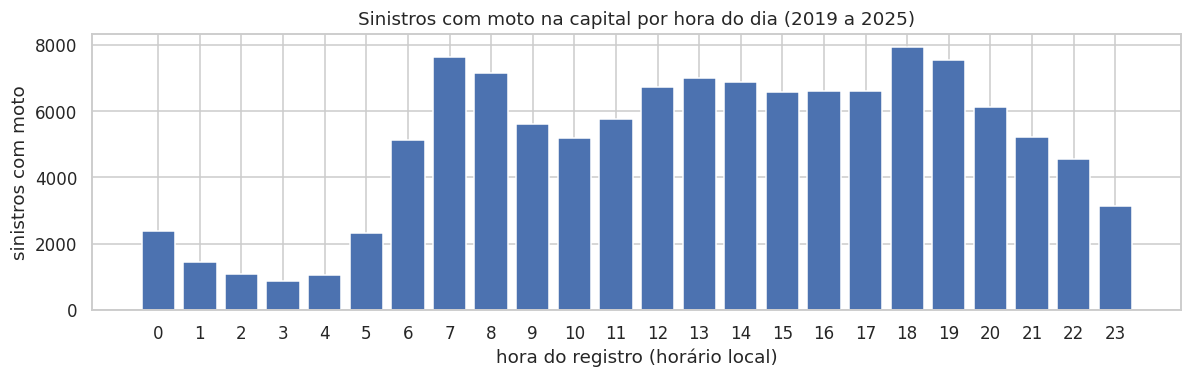

In [10]:
# Hora do sinistro: horas vazias e acúmulo suspeito à meia-noite

FATOR_SUSPEITA_MEIA_NOITE = 3.0       # regra prévia: "00:00" é tratado como hora desconhecida se tiver
                                      # mais de 3 vezes a média das horas cheias vizinhas (23:00 e 01:00)

hm = moto["hora_sinistro"].str.extract(r"^\s*(\d{1,2}):(\d{2})")
moto["hora"] = pd.to_numeric(hm[0], errors="coerce").astype("Int64")
moto["minuto"] = pd.to_numeric(hm[1], errors="coerce").astype("Int64")
moto.loc[~moto["hora"].between(0, 23).fillna(False), "hora"] = pd.NA

sem_hora = moto["hora"].isna()
n_0000 = int(((moto["hora"] == 0) & (moto["minuto"] == 0)).sum())
n_2300 = int(((moto["hora"] == 23) & (moto["minuto"] == 0)).sum())
n_0100 = int(((moto["hora"] == 1) & (moto["minuto"] == 0)).sum())
razao = n_0000 / max(1, (n_2300 + n_0100) / 2)
pct_minuto_zero = (moto.loc[~sem_hora, "minuto"] == 0).mean()

print("=" * 70)
print("HORA DO SINISTRO (sinistros com moto na capital)")
print("=" * 70)
print(f"Sem hora válida: {sem_hora.sum():,} ({sem_hora.mean():.2%})")
print(f"Entre os com vítima grave ou fatal: {moto.loc[moto['tem_grave_fatal'], 'hora'].isna().mean():.2%} sem hora")
print(f"Registros às 00:00: {n_0000:,} | às 23:00: {n_2300:,} | às 01:00: {n_0100:,} | razão: {razao:.2f}")
print(f"Registros em hora cheia (minuto 00), em qualquer hora: {pct_minuto_zero:.1%} (sem arredondamento seria ~1,7%)")
MEIA_NOITE_SUSPEITA = razao > FATOR_SUSPEITA_MEIA_NOITE
print(f"\n'00:00' tratado como hora desconhecida? {'SIM' if MEIA_NOITE_SUSPEITA else 'NÃO'} "
      f"(regra: razão > {FATOR_SUSPEITA_MEIA_NOITE})")

# Distribuição por hora: o perfil do dia antes de qualquer modelo
dist_hora = moto[~sem_hora].groupby("hora").size()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(dist_hora.index, dist_hora.values, color="#4C72B0")
ax.set_xticks(range(24))
ax.set_xlabel("hora do registro (horário local)")
ax.set_ylabel("sinistros com moto")
ax.set_title("Sinistros com moto na capital por hora do dia (2019 a 2025)")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item2_sinistros_por_hora.png", dpi=150, bbox_inches="tight")
plt.show()

### **2.5 Decisão da variável-alvo e tabela de eventos**

A célula aplica as regras definidas no início do item, sem ajuste manual:

1. escolhe o alvo A ou B conforme a porcentagem medida em 2.2 e o limiar de 80%;
2. exclui os sinistros sem hora utilizável (e o "00:00", se a regra de 2.4 o marcou como suspeito);
3. cria a `datahora_local`, a hora cheia do sinistro no horário de Brasília, que é a chave de junção com a grade de horas do Item 4;
4. salva a tabela de eventos em `dados/processados/eventos_alvo.parquet`. Ela guarda também logradouro e coordenadas, que o Item 10 usa para os trechos críticos.

In [11]:
# Decisão da variável-alvo e tabela de eventos para a base horária

# Regra do protocolo, aplicada aos números medidos em 2.2
ALVO = "A" if pct_vitima_na_moto >= LIMIAR_VITIMA_NA_MOTO else "B"
DESCRICAO_ALVO = {
    "A": "sinistros com pelo menos uma motocicleta e pelo menos uma vítima com lesão grave ou fatal",
    "B": "sinistros com pelo menos uma vítima com lesão grave ou fatal que estava em motocicleta",
}[ALVO]

if ALVO == "A":
    ids_alvo = moto.loc[moto["tem_grave_fatal"], "id_sinistro"]
else:
    ids_alvo = pd.Series(ids_b)

eventos = sinistros[sinistros["id_sinistro"].isin(ids_alvo)].copy()
hm = eventos["hora_sinistro"].str.extract(r"^\s*(\d{1,2}):(\d{2})")
eventos["hora"] = pd.to_numeric(hm[0], errors="coerce").astype("Int64")
eventos["minuto"] = pd.to_numeric(hm[1], errors="coerce").astype("Int64")
eventos.loc[~eventos["hora"].between(0, 23).fillna(False), "hora"] = pd.NA
if MEIA_NOITE_SUSPEITA:
    eventos.loc[(eventos["hora"] == 0) & (eventos["minuto"] == 0), "hora"] = pd.NA

n_total = len(eventos)
eventos = eventos[eventos["hora"].notna()].copy()
n_sem_hora = n_total - len(eventos)

# Hora local cheia do sinistro: é a chave de junção com a grade de horas do Item 4
eventos["datahora_local"] = eventos["data_sinistro"] + pd.to_timedelta(eventos["hora"].astype(int), unit="h")
eventos = eventos[["id_sinistro", "datahora_local", "ano_sinistro", "tipo_registro", "logradouro",
                   "latitude", "longitude", "qtd_motocicleta", "qtd_gravidade_fatal", "qtd_gravidade_grave"]]

CACHE_EVENTOS = DIR_PROCESSADOS / "eventos_alvo.parquet"
eventos.to_parquet(CACHE_EVENTOS, index=False)

horas_periodo = len(pd.date_range(f"{ANO_INICIO}-01-01", f"{ANO_FIM}-12-31 23:00", freq="h"))
print("=" * 70)
print("VARIÁVEL-ALVO")
print("=" * 70)
print(f"Alvo escolhido pela regra: {ALVO} ({pct_vitima_na_moto:.1%} contra o limiar de {LIMIAR_VITIMA_NA_MOTO:.0%})")
print(f"Definição: {DESCRICAO_ALVO}")
print(f"Sinistros do alvo: {n_total:,} | sem hora utilizável (excluídos): {n_sem_hora:,} ({n_sem_hora / n_total:.2%})")
print(f"Eventos que entram na base horária: {len(eventos):,}")
print(f"Média no período: {len(eventos) / horas_periodo:.3f} sinistros graves por hora "
      f"({len(eventos) / (horas_periodo / 24):.1f} por dia)")
display(eventos.groupby("ano_sinistro").size().to_frame("sinistros graves com hora"))
print(f"Tabela salva em {CACHE_EVENTOS.name}")

VARIÁVEL-ALVO
Alvo escolhido pela regra: A (88.6% contra o limiar de 80%)
Definição: sinistros com pelo menos uma motocicleta e pelo menos uma vítima com lesão grave ou fatal
Sinistros do alvo: 13,117 | sem hora utilizável (excluídos): 89 (0.68%)
Eventos que entram na base horária: 13,028
Média no período: 0.212 sinistros graves por hora (5.1 por dia)


,sinistros graves com hora
ano_sinistro,
2019,1787
2020,1753
2021,1804
2022,1874
2023,1818
2024,1947
2025,2045


Tabela salva em eventos_alvo.parquet


### **Discussão do Item 2**

#### **As notificações não trazem veículos nem pessoas (2.1)**

Os 108.821 registros do tipo NOTIFICACAO, 35,5% da capital, têm a quantidade de motos 100% vazia e só 3,4% deles têm pessoas registradas. Isso confirma a hipótese do Item 1: as notificações nunca poderiam aparecer como "com moto". Considerando só os 197.571 sinistros com boletim de ocorrência (fatais e não fatais), **as motos estão em 61,1% dos sinistros da capital**, e não em 39,4%. A tabela também mostra que, nesses sinistros, `qtd_motocicleta` vazia significa zero motos: as porcentagens "com moto" e "vazia" somam 100% em cada tipo de registro.

#### **Gravidade estável ao longo dos anos (2.1)**

Entre os 120.621 sinistros com moto, 13.117 (10,9%) têm pelo menos uma vítima grave ou fatal, com variação pequena de ano a ano (de 10,1% a 11,7%). A gravidade "não disponível" fica entre 5,4% e 6,9% em quase todos os anos, com um pico de 10,8% em 2021, e os campos de gravidade totalmente vazios não passam de 0,6%. O salto dos sinistros fatais visto no Item 1 tem uma pista aqui: de 2021 para 2022, os sinistros com vítima fatal sobem de 340 para 467 (127 a mais), mas os com vítima grave ou fatal sobem só de 1.814 para 1.899 (85 a mais). Ou seja, os sinistros com vítima grave e sem morte diminuem, o que sugere que parte dos casos antes registrados como graves passou a ser registrada como fatal. Para o alvo, que soma graves e fatais, essa mudança quase não pesa, e a série cresce de forma gradual. É mais um motivo para não usar só os fatais como alvo.

#### **Quem é a vítima grave (2.2)**

A tabela de sinistros e a de pessoas concordam em 100% dos casos sobre o número de vítimas graves ou fatais, e 99,9% dos sinistros com moto têm pessoas registradas. **Em 88,6% dos sinistros do alvo A, a vítima grave ou fatal estava na moto**, acima do limiar de 80% definido antes de ver os dados. Por isso, a regra manteve o **alvo A**. Entre todas as vítimas graves ou fatais desses sinistros, 95,3% eram motociclistas e 3,8% eram pedestres. A proporção entre os dois alvos (B / A) fica entre 88,0% e 89,9% em todos os anos, então os dois teriam o mesmo comportamento no tempo. O alvo A também é o que responde à pergunta como ela foi feita ("sinistros graves envolvendo motocicletas").

#### **Os dados batem com fontes independentes (2.3)**

A quantidade de motos é igual nas tabelas de sinistros e de veículos em 100% dos casos. Em 2025, a tabela de pessoas tem **1.038 vítimas fatais na capital (divulgado: 1.034) e 477 motociclistas mortos (divulgado: 475)**. A diferença de 4 e 2 mortes é compatível com a atualização da base: um óbito em até 30 dias pode ser incluído depois da divulgação, e os dados usados aqui são de 19/10/2026. É uma validação forte de que o recorte (capital, período e motocicletas) está correto. Também mostra que pedestres (410) são o segundo grupo que mais morre no trânsito da cidade.

#### **A hora do sinistro é confiável (2.4)**

Só 89 sinistros com moto não têm hora (0,07%), e todos estão entre os graves (0,68% deles). Provavelmente são registros fatais montados a partir de outras fontes, sem o horário. Eles foram excluídos, o que subconta muito pouco o alvo. O horário 00:00 não tem acúmulo suspeito (90 registros, contra 110 às 23:00 e 56 às 01:00, razão 1,08, bem abaixo do limite de 3), então foi mantido. Há um leve arredondamento para a hora cheia (2,7% dos registros no minuto 00, contra 1,7% esperado), que não afeta um modelo que agrega por hora.

#### **O perfil do dia já aparece (gráfico de 2.4)**

Os sinistros com moto têm dois picos, às 7h e às 18h (perto de 7,6 mil e 7,9 mil no período), um patamar alto entre 12h e 17h e o mínimo às 3h (menos de mil). É o desenho dos horários de deslocamento e de entregas, compatível com a hipótese H1. O gráfico mostra todos os sinistros com moto. O Item 5 refaz a análise só com os graves, que podem ter outro perfil (por exemplo, mais peso à noite).

#### **A variável-alvo (2.5)**

Ficam **13.028 sinistros graves com moto com hora utilizável**, entre 1.753 (2020) e 2.045 (2025) por ano. Na média, são **0,212 por hora (5,1 por dia)**: a grande maioria das horas terá zero sinistros graves. Isso confirma duas escolhas do protocolo. O objetivo de Poisson foi feito para contagens raras. E o MAE sozinho engana, porque prever sempre zero já teria um erro baixo.

Um ponto fica registrado para o Item 9. A média de 2019 a 2024 é de cerca de 1.830 sinistros graves por ano, e 2025 teve 2.045 (11,7% a mais). Como o ano não entra no modelo, é esperado que ele preveja um pouco menos do que aconteceu em 2025. Esse viés de nível será medido e discutido.

#### **Conclusão do Item 2**

O alvo é a **quantidade de sinistros com pelo menos uma motocicleta e pelo menos uma vítima com lesão grave ou fatal, por hora local**. A definição segue o dicionário de dados, é estável ao longo dos anos, representa o risco do entregador (88,6% com a vítima na moto) e foi validada com os números oficiais de 2025. A tabela de eventos está salva para a construção da base horária, depois que o Item 3 preparar o INMET.

## **Item 3: INMET: leitura, faltantes e conversão de fuso**

O Infosiga registra a hora do sinistro no horário de Brasília, e o INMET registra o tempo em UTC. Se os dois não forem alinhados com cuidado, a chuva das 18h seria atribuída aos sinistros das 21h, e o modelo aprenderia um efeito errado. Este item lê os 7 anos da estação A701, alinha cada medição à hora local do Infosiga e mede a qualidade dos dados.

- **3.1** leitura, conversão de fuso e alinhamento das horas;
- **3.2** valores impossíveis e horas sem medição;
- **3.3** conferência física: totais por ano e perfil do dia.

### **Escolhas e justificativas**

| Escolha | Justificativa |
|---|---|
| Só três variáveis: chuva (mm na hora), temperatura do ar e umidade relativa | São exatamente as que o Serviço de Risco recebe na previsão (`chuvaMmHora`, `temperaturaC` e `umidadePct`, Contrato v1.1). Pressão, vento e radiação não estariam disponíveis no uso real |
| Colunas encontradas pelo nome sem acento | O nome das colunas tem acentos e caracteres especiais. A busca sem acento funciona mesmo se a grafia variar entre os anos |
| `-9999` e campos vazios viram dado ausente | São os códigos de ausência do INMET. Um -9999 tratado como número destruiria qualquer média |
| Conversão pelo fuso `America/Sao_Paulo`, não por "menos 3 horas" fixo | Até 16/02/2019 ainda havia horário de verão (UTC-2). No fim dele, uma hora local aparece duas vezes, e nesse caso fica a média dos dois registros |
| **Cada registro vai para a hora anterior** | O registro das 18h resume o que aconteceu entre 17h e 18h, como mostram as colunas "...NA HORA ANT." (hora anterior) do próprio arquivo. No Infosiga, a hora 17 vai de 17:00 a 17:59, então o registro das 18h vai para a hora 17 |
| Grade local completa, de 01/01/2019 00h a 31/12/2025 23h | Toda hora do estudo aparece, com ou sem medição. As horas sem medição ficam marcadas aqui, e a decisão de excluí-las do treino e do teste é aplicada no Item 4 |
| Faixas físicas plausíveis: chuva de 0 a 150 mm, temperatura de -5 a 45 °C, umidade de 1% a 100% | Regra definida antes de olhar os dados. Valor fora da faixa é erro de sensor e vira ausente |

### **3.1 Leitura, conversão de fuso e alinhamento das horas**

A célula lê os 7 arquivos, converte data e hora de UTC para o horário de Brasília e mostra quantos registros caíram em cada diferença de fuso (UTC-2 no horário de verão do início de 2019 e UTC-3 no resto). Depois desloca cada registro para a hora que ele resume e monta a grade local completa de 61.368 horas.

Duas consequências esperadas do alinhamento, que a célula conta:

- as primeiras horas convertidas caem na noite de 31/12/2018, fora do período, e são descartadas;
- as últimas horas locais de 2025 dependem de registros de 01/01/2026 em UTC, que não foram baixados, e ficam sem medição (aparecem em 3.2).

In [12]:
# INMET: leitura dos 7 anos, padronização e conversão de UTC para o horário de Brasília

import unicodedata

CACHE_INMET = DIR_PROCESSADOS / "inmet_horario_local.parquet"


def normalizar(texto: str) -> str:
    """Remove acentos e padroniza em maiúsculas, para achar a coluna mesmo se a grafia variar entre anos."""
    return unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode().upper().strip()


# Colunas usadas e o início do nome de cada uma no arquivo do INMET (sem acento)
COLUNAS_INMET = {
    "chuva_mm": "PRECIPITACAO TOTAL, HORARIO",
    "temperatura_c": "TEMPERATURA DO AR - BULBO SECO, HORARIA",
    "umidade_pct": "UMIDADE RELATIVA DO AR, HORARIA",
}


def ler_inmet(caminho: Path) -> pd.DataFrame:
    """Lê um ano da A701 e devolve data e hora em UTC com chuva, temperatura e umidade."""
    bruto = pd.read_csv(caminho, sep=";", skiprows=8, encoding=CODIFICACAO[caminho.name], dtype=str)
    nomes = {normalizar(c): c for c in bruto.columns}
    df = pd.DataFrame()
    for novo, prefixo in COLUNAS_INMET.items():
        original = next(c for n, c in nomes.items() if n.startswith(prefixo))
        df[novo] = para_decimal(bruto[original])
    # "2019/01/01" + "0000 UTC" vira 2019-01-01 00:00 em UTC
    hora = bruto.iloc[:, 1].str.replace("UTC", "", regex=False).str.replace(":", "", regex=False).str.strip().str.zfill(4)
    df["datahora_utc"] = pd.to_datetime(bruto.iloc[:, 0].str.strip() + " " + hora, format="%Y/%m/%d %H%M", utc=True)
    return df


print("=" * 70)
print("INMET A701: LEITURA E CONVERSÃO DE FUSO")
print("=" * 70)

if CACHE_INMET.exists() and not FORCAR_RELEITURA:
    inmet = pd.read_parquet(CACHE_INMET)
    print(f"Cache encontrado: {CACHE_INMET.name} ({len(inmet):,} horas). Leitura dos CSVs pulada.")
else:
    partes = []
    for ano, arq in ARQ_INMET.items():
        df = ler_inmet(arq)
        partes.append(df)
        print(f"{ano}: {len(df):,} horas | de {df['datahora_utc'].min():%d/%m %H:%M} a {df['datahora_utc'].max():%d/%m %H:%M} UTC")
    utc = pd.concat(partes, ignore_index=True)

    # Códigos de dado ausente do INMET (-9999) viram vazio
    for c in COLUNAS_INMET:
        utc.loc[utc[c] <= -9999, c] = np.nan

    # Conversão pelo fuso oficial: UTC-2 até 16/02/2019 (horário de verão) e UTC-3 depois
    local = utc["datahora_utc"].dt.tz_convert(FUSO_LOCAL)
    utc["registro_local"] = local.dt.tz_localize(None)
    utc["offset_h"] = local.apply(lambda t: t.utcoffset().total_seconds() / 3600)
    print("\nDiferença em relação ao UTC (registros por offset):")
    display(utc.groupby("offset_h")["registro_local"].agg(["count", "min", "max"]))

    # Cada registro resume a hora ANTERIOR (o registro das 18h traz a chuva das 17h às 18h).
    # No Infosiga, a "hora 17" vai de 17:00 a 17:59: o registro das 18h vai para a hora 17.
    utc["datahora_local"] = utc["registro_local"] - pd.Timedelta(hours=1)

    # No fim do horário de verão (16/02/2019), uma hora local aparece duas vezes: fica a média
    duplicadas = int(utc["datahora_local"].duplicated().sum())
    inmet = (utc.groupby("datahora_local", as_index=False)[list(COLUNAS_INMET)].mean())

    # Grade local completa do estudo: toda hora de 2019 a 2025 aparece, com ou sem medição
    grade = pd.DataFrame({"datahora_local": pd.date_range(f"{ANO_INICIO}-01-01 00:00",
                                                          f"{ANO_FIM}-12-31 23:00", freq="h")})
    fora_do_periodo = int((~inmet["datahora_local"].isin(grade["datahora_local"])).sum())
    inmet = grade.merge(inmet, on="datahora_local", how="left")
    inmet.to_parquet(CACHE_INMET, index=False)

    print(f"Horas locais duplicadas no fim do horário de verão (média aplicada): {duplicadas}")
    print(f"Horas locais fora de {ANO_INICIO} a {ANO_FIM} descartadas (noite de 31/12/2018): {fora_do_periodo}")
    print(f"Cache salvo em {CACHE_INMET.name}")

print(f"\nGrade local: {len(inmet):,} horas, de {inmet['datahora_local'].min():%d/%m/%Y %H:%M} "
      f"a {inmet['datahora_local'].max():%d/%m/%Y %H:%M}")

INMET A701: LEITURA E CONVERSÃO DE FUSO
Cache encontrado: inmet_horario_local.parquet (61,368 horas). Leitura dos CSVs pulada.

Grade local: 61,368 horas, de 01/01/2019 00:00 a 31/12/2025 23:00


### **3.2 Valores impossíveis e horas sem medição**

Primeiro, a célula aplica as faixas físicas plausíveis: o que estiver fora vira ausente, e a contagem é mostrada. Depois mede, por ano, a porcentagem de horas sem chuva, sem temperatura, sem umidade e sem alguma das três. Também mede a maior lacuna, a maior sequência de horas seguidas sem medição, que diferencia falhas curtas de um sensor parado por semanas.

O `dados/README.md` antecipa cerca de 7,4% das horas de 2023 e 0,5% das de 2025 sem chuva. A tabela confere esses números.

In [13]:
# Valores impossíveis e horas sem medição, por ano e por variável

# Faixas físicas plausíveis para a cidade de São Paulo (regra definida antes de olhar os dados)
FAIXAS_PLAUSIVEIS = {"chuva_mm": (0, 150), "temperatura_c": (-5, 45), "umidade_pct": (1, 100)}

print("=" * 70)
print("INMET: VALORES FORA DA FAIXA FÍSICA")
print("=" * 70)
for c, (minimo, maximo) in FAIXAS_PLAUSIVEIS.items():
    fora = inmet[c].notna() & ~inmet[c].between(minimo, maximo)
    print(f"{c:<14s} faixa {minimo} a {maximo}: {int(fora.sum())} valores fora (viram vazio) | "
          f"mín encontrado {inmet[c].min():.1f} | máx encontrado {inmet[c].max():.1f}")
    inmet.loc[fora, c] = np.nan

inmet["ano"] = inmet["datahora_local"].dt.year
inmet["tempo_completo"] = inmet[list(COLUNAS_INMET)].notna().all(axis=1)


def maior_lacuna(vazio: pd.Series) -> int:
    """Maior sequência de horas seguidas sem medição."""
    grupos = (vazio != vazio.shift()).cumsum()
    return int(vazio.groupby(grupos).sum().max()) if vazio.any() else 0


faltantes = inmet.groupby("ano").agg(
    horas=("datahora_local", "size"),
    sem_chuva=("chuva_mm", lambda s: s.isna().mean()),
    sem_temperatura=("temperatura_c", lambda s: s.isna().mean()),
    sem_umidade=("umidade_pct", lambda s: s.isna().mean()),
    sem_alguma_variavel=("tempo_completo", lambda s: 1 - s.mean()),
)
faltantes["maior_lacuna_h"] = [maior_lacuna(~g["tempo_completo"]) for _, g in inmet.groupby("ano")]
faltantes.loc["Total"] = [len(inmet), inmet["chuva_mm"].isna().mean(), inmet["temperatura_c"].isna().mean(),
                          inmet["umidade_pct"].isna().mean(), 1 - inmet["tempo_completo"].mean(),
                          maior_lacuna(~inmet["tempo_completo"])]
print()
print("=" * 70)
print("INMET: HORAS SEM MEDIÇÃO (grade local de 2019 a 2025)")
print("=" * 70)
display(faltantes.style.format({"horas": "{:,.0f}", "sem_chuva": "{:.2%}", "sem_temperatura": "{:.2%}",
                                "sem_umidade": "{:.2%}", "sem_alguma_variavel": "{:.2%}", "maior_lacuna_h": "{:,.0f}"}))

# As últimas horas locais de 2025 dependem de medições de 01/01/2026 em UTC, que não foram baixadas
fim = inmet[inmet["datahora_local"] >= f"{ANO_FIM}-12-31 19:00"][["datahora_local", "chuva_mm", "temperatura_c"]]
print(f"Últimas horas locais de {ANO_FIM} (das 20h às 23h, os registros estão no arquivo de 2026 em UTC):")
display(fim)
print(f"Horas com tempo completo: {int(inmet['tempo_completo'].sum()):,} de {len(inmet):,} "
      f"({inmet['tempo_completo'].mean():.2%})")

INMET: VALORES FORA DA FAIXA FÍSICA
chuva_mm       faixa 0 a 150: 0 valores fora (viram vazio) | mín encontrado 0.0 | máx encontrado 82.0
temperatura_c  faixa -5 a 45: 0 valores fora (viram vazio) | mín encontrado 4.4 | máx encontrado 37.3
umidade_pct    faixa 1 a 100: 0 valores fora (viram vazio) | mín encontrado 12.0 | máx encontrado 100.0

INMET: HORAS SEM MEDIÇÃO (grade local de 2019 a 2025)


,horas,sem_chuva,sem_temperatura,sem_umidade,sem_alguma_variavel,maior_lacuna_h
ano,,,,,,
2019,"8,760",0.00%,0.00%,0.00%,0.00%,0
2020,"8,784",0.02%,0.01%,0.01%,0.02%,1
2021,"8,760",0.01%,0.01%,0.02%,0.02%,1
2022,"8,760",0.01%,0.00%,0.00%,0.01%,1
2023,"8,760",7.36%,2.42%,2.42%,7.39%,219
2024,"8,784",0.23%,0.22%,0.22%,0.23%,9
2025,"8,760",0.58%,0.58%,0.58%,0.58%,15
Total,"61,368",1.17%,0.46%,0.46%,1.18%,219


Últimas horas locais de 2025 (das 20h às 23h, os registros estão no arquivo de 2026 em UTC):


,datahora_local,chuva_mm,temperatura_c
61363,2025-12-31 19:00:00,0.0000,25.4000
61364,2025-12-31 20:00:00,NaN,NaN
61365,2025-12-31 21:00:00,NaN,NaN
61366,2025-12-31 22:00:00,NaN,NaN
61367,2025-12-31 23:00:00,NaN,NaN


Horas com tempo completo: 60,645 de 61,368 (98.82%)


### **3.3 Conferência física: totais por ano e perfil do dia**

Uma forma simples de validar a leitura e o fuso é ver se os números fazem sentido físico:

- **por ano:** chuva total, porcentagem de horas com chuva, temperatura média e máxima e umidade média;
- **intensidade da chuva:** nas horas em que choveu, a mediana, os percentis e o máximo, além de quantas horas chegaram a 10 mm, o valor em que o componente `chuva` do Índice de Risco atinge 100 (Contrato v1.1);
- **perfil do dia:** com o fuso certo, a temperatura média mínima cai no começo da manhã e a máxima no meio da tarde. Se a conversão estivesse errada em 3 horas, o perfil apareceria deslocado.

O gráfico é salvo em `figuras/item3_perfil_horario_tempo.png`.

INMET: RESUMO POR ANO (horas com tempo completo)


,chuva_total_mm,pct_horas_com_chuva,temperatura_media_c,temperatura_max_c,umidade_media_pct
ano,,,,,
2019,"1,752",7.7%,21.0,35.7,67.9
2020,"1,731",7.7%,20.5,37.3,67.5
2021,"1,205",7.0%,20.1,35.4,68.4
2022,"1,471",8.7%,20.0,33.2,69.5
2023,"1,744",7.7%,21.3,37.2,68.8
2024,"1,524",7.9%,21.6,35.9,66.5
2025,"1,458",6.5%,20.4,35.9,68.3


Horas com chuva: 4,608 (7.6%) | mediana 0.8 mm | p90 6.2 mm | p99 21.6 mm | máx 82.0 mm
Horas com 10 mm ou mais (componente chuva do índice = 100): 248 (0.41%)

Hora local da temperatura média mínima: 5h | máxima: 13h | hora com mais chuva: 17h


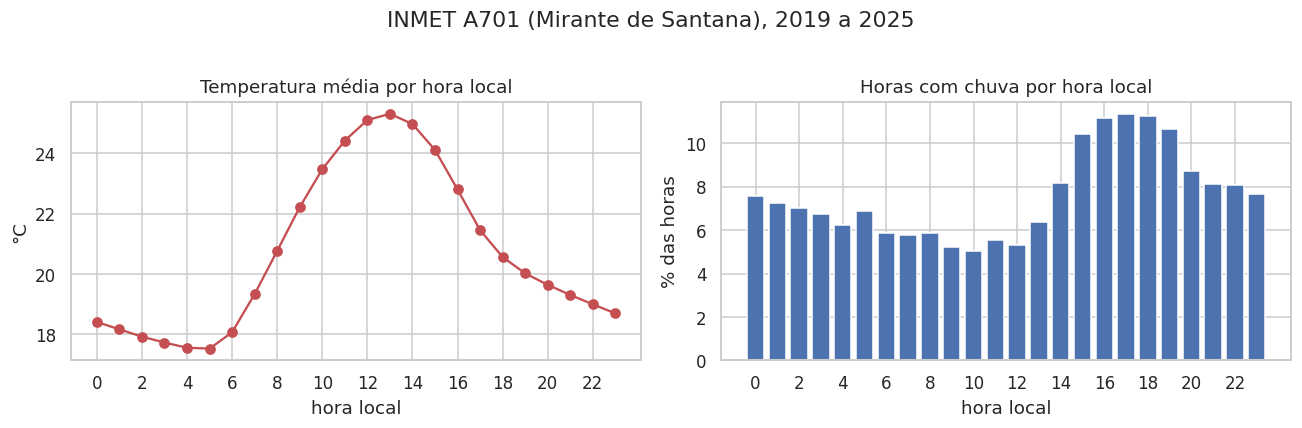

In [14]:
# Conferência física: totais por ano e perfil do dia no horário local

com_dados = inmet[inmet["tempo_completo"]]
resumo_ano = com_dados.groupby("ano").agg(
    chuva_total_mm=("chuva_mm", "sum"),
    pct_horas_com_chuva=("chuva_mm", lambda s: (s > 0).mean()),
    temperatura_media_c=("temperatura_c", "mean"),
    temperatura_max_c=("temperatura_c", "max"),
    umidade_media_pct=("umidade_pct", "mean"),
)
print("=" * 70)
print("INMET: RESUMO POR ANO (horas com tempo completo)")
print("=" * 70)
display(resumo_ano.style.format({"chuva_total_mm": "{:,.0f}", "pct_horas_com_chuva": "{:.1%}",
                                 "temperatura_media_c": "{:.1f}", "temperatura_max_c": "{:.1f}",
                                 "umidade_media_pct": "{:.1f}"}))

# Intensidade da chuva nas horas em que choveu (referência para o Item 5 e para o índice do Contrato)
chuva = com_dados.loc[com_dados["chuva_mm"] > 0, "chuva_mm"]
print(f"Horas com chuva: {len(chuva):,} ({len(chuva) / len(com_dados):.1%}) | mediana {chuva.median():.1f} mm | "
      f"p90 {chuva.quantile(0.90):.1f} mm | p99 {chuva.quantile(0.99):.1f} mm | máx {chuva.max():.1f} mm")
print(f"Horas com 10 mm ou mais (componente chuva do índice = 100): {(com_dados['chuva_mm'] >= 10).sum():,} "
      f"({(com_dados['chuva_mm'] >= 10).mean():.2%})")

# Perfil do dia: se o fuso estiver certo, a temperatura mínima cai no começo da manhã e a máxima no meio da tarde
perfil = com_dados.assign(hora=com_dados["datahora_local"].dt.hour).groupby("hora").agg(
    temperatura_media_c=("temperatura_c", "mean"),
    pct_horas_com_chuva=("chuva_mm", lambda s: (s > 0).mean() * 100),
)
print(f"\nHora local da temperatura média mínima: {perfil['temperatura_media_c'].idxmin()}h | "
      f"máxima: {perfil['temperatura_media_c'].idxmax()}h | hora com mais chuva: {perfil['pct_horas_com_chuva'].idxmax()}h")

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
eixos[0].plot(perfil.index, perfil["temperatura_media_c"], marker="o", color="#C44E52")
eixos[0].set_title("Temperatura média por hora local")
eixos[0].set_ylabel("°C")
eixos[1].bar(perfil.index, perfil["pct_horas_com_chuva"], color="#4C72B0")
eixos[1].set_title("Horas com chuva por hora local")
eixos[1].set_ylabel("% das horas")
for ax in eixos:
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("hora local")
fig.suptitle("INMET A701 (Mirante de Santana), 2019 a 2025", y=1.02)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item3_perfil_horario_tempo.png", dpi=150, bbox_inches="tight")
plt.show()

### **Discussão do Item 3**

#### **Leitura e fuso (3.1)**

Os 7 arquivos estão completos em número de registros: 8.760 horas por ano, ou 8.784 nos anos bissextos de 2020 e 2024, sempre de 01/01 às 00:00 a 31/12 às 23:00 UTC. As medições ausentes aparecem como campos vazios, não como linhas que faltam. A conversão pelo fuso oficial colocou 1.130 registros em UTC-2 (o horário de verão, até 16/02/2019) e 60.238 em UTC-3. O fim do horário de verão gerou 1 hora local duplicada, resolvida pela média, e o alinhamento descartou 3 horas que caíam na noite de 31/12/2018. O resultado é a grade local completa de 61.368 horas, exatamente o período do estudo.

#### **Nenhum valor impossível (3.2)**

A chuva vai de 0 a 82 mm em uma hora, a temperatura de 4,4 a 37,3 °C e a umidade de 12% a 100%. Nenhuma faixa física foi violada. Os 82 mm em uma hora são extremos, mas plausíveis para uma tempestade de verão em São Paulo.

#### **Horas sem medição (3.2)**

De 2019 a 2022, as falhas são desprezíveis (até 0,02% das horas). Em 2023, 7,36% das horas não têm chuva e 2,42% não têm temperatura e umidade, com uma lacuna de até 219 horas seguidas (cerca de 9 dias). Isso indica que o pluviômetro falhou mais vezes que o termômetro. Em 2024 faltam 0,23%, e em 2025 faltam 0,58%, que incluem as 4 últimas horas do ano, cujos registros estão no arquivo de 2026 em UTC. Os números batem com o `dados/README.md` (cerca de 7,4% em 2023 e 0,5% em 2025). No total, **60.645 horas (98,82%) têm o tempo completo**, e as 723 restantes ficam fora do treino e do teste, como define o protocolo.

#### **Os números fazem sentido físico (3.3)**

A chuva anual vai de 1.205 mm (2021, um ano seco no Sudeste) a 1.752 mm (2019), e a temperatura média anual fica entre 20,0 e 21,6 °C. Chove em 7,6% das horas, quase sempre pouco: nas horas com chuva, a mediana é de 0,8 mm, o percentil 90 é de 6,2 mm e o 99 é de 21,6 mm. Só 248 horas (0,41%) chegaram a 10 mm, o valor em que o componente `chuva` do Índice de Risco atinge 100. O índice vai, portanto, separar bem os raros temporais fortes, e a maioria das horas de chuva será de garoa ou chuva fraca.

#### **O alinhamento está certo (gráfico de 3.3)**

A temperatura média é mínima na hora local 5 e máxima na hora 13. Como a hora h carrega o registro feito ao fim dela (às 14h, no caso da hora 13), o pico real fica por volta das 14h, como esperado em São Paulo. Se a conversão de fuso estivesse errada, o perfil apareceria deslocado em 3 horas. As chuvas se concentram à tarde: em mais de 10% das horas entre 15h e 19h há chuva, com pico às 17h. É o padrão das tempestades de verão, que se formam com o calor do dia.

#### **Um cuidado para o Item 5 e para o modelo**

O pico de chuva (17h) praticamente coincide com o pico de sinistros com moto (18h, gráfico do Item 2). Numa comparação simples entre horas com chuva e sem chuva, a chuva pareceria perigosa só porque cai no horário de pico do trânsito. Por isso, o efeito da chuva será medido **na mesma hora do dia**, e o modelo recebe a hora como variável. Assim ele consegue separar os dois efeitos.

#### **Conclusão do Item 3**

Os dados do tempo estão alinhados à hora local do Infosiga, sem valores impossíveis e com 98,82% das horas completas. Com isso, a base horária pode ser montada.

## **Item 4: Base horária: grade completa, calendário, feriados e junção com o tempo**

Este item monta a tabela que o modelo vai usar: **uma linha por hora local de 2019 a 2025**, com a quantidade de sinistros graves com moto (o alvo), o tempo daquela hora e o calendário.

- **4.1** regra de feriados da cidade de São Paulo;
- **4.2** montagem, conferências e gravação da base em `dados/processados/base_horaria.parquet`.

### **Escolhas e justificativas**

| Escolha | Justificativa |
|---|---|
| Grade com as 61.368 horas, inclusive as sem sinistro (alvo = 0) | Sem as horas zeradas, o modelo nunca veria o "nada aconteceu" e superestimaria o risco (protocolo) |
| Calendário só com hora, dia da semana, mês e feriado | São as variáveis que o Serviço de Risco consegue montar a partir da requisição (Contrato v1.1, seção 8.1). O ano fica na base só para dividir treino e teste e para diagnóstico, nunca como variável do modelo |
| Dia da semana de 0 (segunda) a 6 (domingo), hora de 0 a 23 e mês de 1 a 12, como inteiros | Árvores não precisam de one-hot. A convenção vai documentada no `metadados_modelo.json` |
| Feriados: nacionais e estaduais (biblioteca `holidays`), municipais da capital (25/01, Corpus Christi e 20/11) e segunda e terça de Carnaval | O Carnaval é ponto facultativo, mas na prática muda o trânsito da cidade como um feriado. A regra gera uma lista de datas de 2019 a 2030, que vai para o `metadados_modelo.json`, para o Serviço de Risco reproduzir exatamente, sem depender da versão da biblioteca |
| Horas sem tempo completo ficam na base, marcadas em `tempo_completo` | A exclusão do treino e do teste fica explícita e reproduzível. Quantas horas e quantos sinistros ficam de fora é medido aqui |
| Base sem nenhuma coluna por sinistro (sem `id_sinistro`, logradouro ou coordenadas) | É a única tabela de `processados/` versionada no GitHub (Contrato v1.1, seção 10): só contagens agregadas, tempo e calendário, sem dados pessoais |

**Limitação conhecida.** Em 2020 e 2021, durante a pandemia, a Prefeitura e o Estado anteciparam feriados para reduzir a circulação. A regra usa o calendário regular, e esses dias não aparecem como feriado. O efeito é pequeno (poucos dias em 7 anos) e fica registrado na conclusão.

### **4.1 Regra de feriados da cidade de São Paulo**

A função `feriados_capital_sp` junta, para cada ano:

1. os feriados nacionais e estaduais de São Paulo da biblioteca `holidays` (categoria pública), como Tiradentes, Finados e 9 de julho;
2. os municipais da capital: aniversário da cidade (25/01), Corpus Christi (60 dias depois da Páscoa) e Consciência Negra (20/11, municipal desde 2004 e nacional desde 2024);
3. a segunda e a terça de Carnaval (48 e 47 dias antes da Páscoa).

As datas que dependem da Páscoa são calculadas diretamente, sem depender da biblioteca. A lista cobre de 2019 a 2030, o período do estudo mais os anos de uso do modelo. Os feriados de 2025 aparecem para conferência.

In [15]:
# Feriados: regra única, que o Serviço de Risco reproduz pela lista de datas exportada

from dateutil.easter import easter

ANOS_FERIADOS = range(ANO_INICIO, 2031)     # período do estudo + anos de uso do modelo (lista vai para o metadados)


def feriados_capital_sp(anos) -> dict:
    """Feriados da cidade de São Paulo: nacionais e estaduais (holidays), municipais e Carnaval."""
    datas = {}
    for ano in anos:
        # Nacionais e estaduais de SP (categoria "public" da biblioteca holidays)
        for data, nome in holidays.Brazil(subdiv="SP", years=ano, language="pt_BR").items():
            datas[data] = nome
        pascoa = easter(ano)
        # Municipais da capital: aniversário da cidade, Corpus Christi e Consciência Negra
        datas[pd.Timestamp(ano, 1, 25).date()] = "Aniversário de São Paulo (municipal)"
        datas[pascoa + pd.Timedelta(days=60)] = "Corpus Christi (municipal)"
        datas.setdefault(pd.Timestamp(ano, 11, 20).date(), "Consciência Negra (municipal)")
        # Carnaval: ponto facultativo, mas na prática dia de folga na cidade (segunda e terça)
        datas[pascoa - pd.Timedelta(days=48)] = "Carnaval (segunda)"
        datas[pascoa - pd.Timedelta(days=47)] = "Carnaval (terça)"
    return dict(sorted(datas.items()))


FERIADOS = feriados_capital_sp(ANOS_FERIADOS)
DIAS_SEMANA = ["segunda", "terça", "quarta", "quinta", "sexta", "sábado", "domingo"]
DATAS_FERIADO = set(FERIADOS)

print("=" * 70)
print("FERIADOS DA CIDADE DE SÃO PAULO")
print("=" * 70)
por_ano = pd.Series([d.year for d in FERIADOS]).value_counts().sort_index()
print("Quantidade por ano:", por_ano.to_dict())
print(f"\nFeriados de {ANO_TESTE} (conferência):")
display(pd.DataFrame([(d.strftime("%d/%m/%Y"), DIAS_SEMANA[d.weekday()], n)
                      for d, n in FERIADOS.items() if d.year == ANO_TESTE],
                     columns=["data", "dia da semana", "feriado"]).style.hide(axis="index"))

FERIADOS DA CIDADE DE SÃO PAULO
Quantidade por ano: {2019: 15, 2020: 15, 2021: 15, 2022: 15, 2023: 15, 2024: 15, 2025: 15, 2026: 15, 2027: 15, 2028: 15, 2029: 15, 2030: 15}

Feriados de 2025 (conferência):


data,dia da semana,feriado
01/01/2025,quarta,Confraternização Universal
25/01/2025,sábado,Aniversário de São Paulo (municipal)
03/03/2025,segunda,Carnaval (segunda)
04/03/2025,terça,Carnaval (terça)
18/04/2025,sexta,Sexta-feira Santa
21/04/2025,segunda,Tiradentes
01/05/2025,quinta,Dia do Trabalhador
19/06/2025,quinta,Corpus Christi (municipal)
09/07/2025,quarta,Revolução Constitucionalista
07/09/2025,domingo,Independência do Brasil


### **4.2 Montagem, conferências e gravação da base horária**

A célula:

1. conta os sinistros graves com moto de cada hora local (tabela de eventos do Item 2);
2. junta essa contagem à grade completa de horas do Item 3, e as horas sem sinistro recebem 0;
3. cria as variáveis de calendário;
4. confere, no próprio código, que há uma linha por hora (61.368), que nenhum evento se perdeu na junção e que não há colunas por sinistro;
5. salva o arquivo com o nome exato `base_horaria.parquet`.

No fim, mostra quantas horas e quantos sinistros ficam de fora por falta de dados do tempo e resume as horas que entram no modelo, separadas em treino (2019 a 2024) e teste (2025).

In [16]:
# Base horária: uma linha por hora local de 2019 a 2025, com o alvo, o tempo e o calendário

ARQ_BASE = DIR_PROCESSADOS / "base_horaria.parquet"     # nome exato liberado no .gitignore

# 1) Alvo: quantos sinistros graves com moto começaram em cada hora local
contagem = eventos.groupby("datahora_local").size().rename("sinistros_graves")
fora_da_grade = int((~contagem.index.isin(inmet["datahora_local"])).sum())

# 2) Grade completa (vinda do Item 3) + alvo; horas sem sinistro recebem 0
base = inmet[["datahora_local", "chuva_mm", "temperatura_c", "umidade_pct", "tempo_completo"]].merge(
    contagem, left_on="datahora_local", right_index=True, how="left")
base["sinistros_graves"] = base["sinistros_graves"].fillna(0).astype(int)

# 3) Calendário: só o que o Serviço de Risco consegue montar a partir da requisição (Contrato v1.1)
base["hora"] = base["datahora_local"].dt.hour                     # 0 a 23
base["dia_semana"] = base["datahora_local"].dt.dayofweek          # 0 = segunda ... 6 = domingo
base["mes"] = base["datahora_local"].dt.month                     # 1 a 12
base["feriado"] = base["datahora_local"].dt.date.isin(DATAS_FERIADO).astype(int)
base["ano"] = base["datahora_local"].dt.year                      # só para dividir treino e teste e diagnosticar

base = base[["datahora_local", "ano", "hora", "dia_semana", "mes", "feriado",
             "chuva_mm", "temperatura_c", "umidade_pct", "tempo_completo", "sinistros_graves"]]

# Conferências
assert len(base) == base["datahora_local"].nunique() == 61_368, "a grade deve ter uma linha por hora"
assert base["sinistros_graves"].sum() == len(eventos), "nenhum evento pode se perder na junção"
colunas_proibidas = {"id_sinistro", "logradouro", "latitude", "longitude"}
assert not colunas_proibidas & set(base.columns), "a base versionada não pode ter colunas por sinistro"

base.to_parquet(ARQ_BASE, index=False)

incompletas = base[~base["tempo_completo"]]
print("=" * 70)
print("BASE HORÁRIA")
print("=" * 70)
print(f"Horas: {len(base):,} | eventos fora da grade: {fora_da_grade} | "
      f"sinistros graves somados: {base['sinistros_graves'].sum():,} (eventos do Item 2: {len(eventos):,})")
print(f"Horas com feriado: {base['feriado'].sum():,} ({base['feriado'].mean():.1%})")
print(f"Horas sem tempo completo: {len(incompletas):,} ({len(incompletas) / len(base):.2%}), "
      f"com {incompletas['sinistros_graves'].sum():,} sinistros graves "
      f"({incompletas['sinistros_graves'].sum() / base['sinistros_graves'].sum():.2%} do total)")

# Horas que entram no modelo (protocolo: horas sem tempo completo ficam fora do treino e do teste)
base_modelo = base[base["tempo_completo"]]
resumo = base_modelo.groupby(np.where(base_modelo["ano"] == ANO_TESTE, f"teste ({ANO_TESTE})",
                                      f"treino ({ANOS_TREINO[0]} a {ANOS_TREINO[-1]})")).agg(
    horas=("sinistros_graves", "size"),
    sinistros_graves=("sinistros_graves", "sum"),
    media_por_hora=("sinistros_graves", "mean"),
    pct_horas_com_zero=("sinistros_graves", lambda s: (s == 0).mean()),
)
print("\nHoras que entram no modelo:")
display(resumo.style.format({"horas": "{:,}", "sinistros_graves": "{:,}", "media_por_hora": "{:.3f}",
                             "pct_horas_com_zero": "{:.1%}"}))

tamanho_kb = ARQ_BASE.stat().st_size / 1024
print(f"\nArquivo salvo: {ARQ_BASE.name} ({tamanho_kb:,.0f} KB) | colunas: {', '.join(base.columns)}")
display(base.head())

BASE HORÁRIA
Horas: 61,368 | eventos fora da grade: 0 | sinistros graves somados: 13,028 (eventos do Item 2: 13,028)
Horas com feriado: 2,520 (4.1%)
Horas sem tempo completo: 723 (1.18%), com 160 sinistros graves (1.23% do total)

Horas que entram no modelo:


,horas,sinistros_graves,media_por_hora,pct_horas_com_zero
teste (2025),"8,709","2,025",0.233,80.0%
treino (2019 a 2024),"51,936","10,843",0.209,81.4%



Arquivo salvo: base_horaria.parquet (710 KB) | colunas: datahora_local, ano, hora, dia_semana, mes, feriado, chuva_mm, temperatura_c, umidade_pct, tempo_completo, sinistros_graves


,datahora_local,ano,hora,dia_semana,mes,feriado,chuva_mm,temperatura_c,umidade_pct,tempo_completo,sinistros_graves
0,2019-01-01 00:00:00,2019,0,1,1,1,0.0000,21.6000,76.0000,True,0
1,2019-01-01 01:00:00,2019,1,1,1,1,0.0000,21.6000,76.0000,True,0
2,2019-01-01 02:00:00,2019,2,1,1,1,0.0000,21.4000,75.0000,True,0
3,2019-01-01 03:00:00,2019,3,1,1,1,0.0000,21.1000,77.0000,True,0
4,2019-01-01 04:00:00,2019,4,1,1,1,0.0000,20.8000,79.0000,True,0


### **Discussão do Item 4**

#### **Feriados (4.1)**

A regra gera 15 feriados por ano, de 2019 a 2030, e a lista de 2025 confere com o calendário oficial da cidade. Os nomes saem em português graças ao parâmetro `language="pt_BR"`. Sem ele, a biblioteca segue o idioma do sistema, que no Colab é o inglês. Na base, os feriados somam 2.520 horas (4,1%), ou seja, 105 dias (15 por ano, em 7 anos). Vários feriados caem em fim de semana (em 2025, por exemplo, 7/9, 12/10 e 2/11 foram domingos). Por isso, o efeito do feriado deve aparecer sobretudo nos dias úteis, e o modelo pode combinar `feriado` com `dia_semana`.

#### **A base está íntegra (4.2)**

A grade tem as 61.368 horas, uma linha por hora, e os 13.028 sinistros graves do Item 2 foram todos distribuídos (nenhum fora da grade). As conferências do código passaram: uma linha por hora, nenhum evento perdido e nenhuma coluna por sinistro. A primeira linha também confirma o calendário: 01/01/2019 foi uma terça (`dia_semana` = 1) e aparece como feriado.

#### **A exclusão das horas sem tempo completo não distorce o alvo**

São 723 horas (1,18%) com 160 sinistros graves (1,23% do total). A média nessas horas (0,22 por hora) é praticamente igual à geral (0,21), então a falta de dados do tempo não está concentrada em horas mais ou menos perigosas, e excluí-las não cria viés.

#### **Treino e teste**

O treino (2019 a 2024) tem 51.936 horas e 10.843 sinistros graves, uma média de 0,209 por hora, com 81,4% das horas sem nenhum. O teste (2025) tem 8.709 horas e 2.025 sinistros graves, uma média de 0,233 por hora, com 80,0% das horas zeradas. A média do teste é 11,5% maior que a do treino, o mesmo aumento visto no Item 2 (+11,7% no total do ano). Como o ano fica fora do modelo, esse aumento de nível é o principal suspeito de diferença entre treino e teste, e será medido no Item 9.

#### **O arquivo versionado**

O `base_horaria.parquet` tem 710 KB e só as colunas de calendário, tempo, a marcação `tempo_completo` e o alvo `sinistros_graves`. Não tem nenhum identificador, logradouro ou coordenada, como exige o Contrato v1.1 para a única tabela de `processados/` que vai para o GitHub.

#### **Conclusão do Item 4**

A base horária está pronta, completa e verificada: ela é a matéria-prima dos Itens 5 a 9.

## **Item 5: Análise exploratória**

Antes de treinar qualquer modelo, este item responde: o que os dados já mostram sobre as hipóteses H1 a H4 da Introdução?

**Regra para não contaminar o teste:** tudo o que orienta decisões usa só as horas de treino (2019 a 2024, com tempo completo). O ano de 2025 aparece apenas na série anual, como descrição, porque é o conjunto de teste.

- **5.1** distribuição do alvo: quão rara é uma hora com sinistro grave, e se ela se parece com uma Poisson;
- **5.2** série anual e sazonalidade por mês;
- **5.3** hora do dia e dia da semana (hipótese H1);
- **5.4** efeito da chuva, da temperatura, da umidade e dos feriados **na mesma hora** (hipóteses H2 e H3).

### **Como o efeito do tempo é medido (5.4)**

O Item 3 mostrou que o pico de chuva (17h) quase coincide com o pico de sinistros (18h). Comparar horas com e sem chuva diretamente misturaria os dois efeitos. Por isso, cada hora é comparada com o **normal do mesmo horário**: o esperado de uma hora é a média histórica de sinistros graves naquela hora e naquele dia da semana, e a **razão observado/esperado** de uma faixa de chuva diz quanto acima ou abaixo do normal ela fica. Uma razão de 1,20 significa 20% mais sinistros graves do que o normal para aqueles horários. O intervalo de confiança de 95% mostra se a diferença pode ser só acaso: se o intervalo inclui 1, não dá para afirmar efeito.

Todas as figuras são salvas em `figuras/` com o prefixo `item5_`.

### **5.1 Distribuição do alvo**

A tabela mostra quantas horas de treino tiveram 0, 1, 2, 3 ou 4 ou mais sinistros graves e compara com o que uma distribuição de Poisson com a mesma média daria. Dois números resumem o formato:

- **variância dividida pela média:** numa Poisson pura, as duas são iguais (razão 1). Uma razão acima de 1 indica que o risco varia de hora para hora, que é justamente o que o modelo tenta explicar;
- **o MAE de "prever sempre 0":** a referência mínima, que mostra por que o MAE sozinho não basta para avaliar o modelo.

In [17]:
# Distribuição do alvo nas horas de treino: quão rara é uma hora com sinistro grave?

from scipy.stats import poisson

# A análise que orienta decisões usa só o treino (2019 a 2024); 2025 fica guardado para o teste
treino_eda = base[base["tempo_completo"] & base["ano"].isin(ANOS_TREINO)].copy()
y = treino_eda["sinistros_graves"]
media, variancia = y.mean(), y.var()

contagens = y.clip(upper=4)
observado = contagens.value_counts(normalize=True).reindex(range(5), fill_value=0)
esperado_poisson = [poisson.pmf(k, media) for k in range(4)] + [poisson.sf(3, media)]
distribuicao = pd.DataFrame({
    "sinistros graves na hora": ["0", "1", "2", "3", "4 ou mais"],
    "horas": contagens.value_counts().reindex(range(5), fill_value=0).values,
    "% observado": observado.values * 100,
    "% esperado se fosse Poisson com a mesma média": np.array(esperado_poisson) * 100,
})

print("=" * 70)
print(f"DISTRIBUIÇÃO DO ALVO (treino, {ANOS_TREINO[0]} a {ANOS_TREINO[-1]}, {len(y):,} horas)")
print("=" * 70)
display(distribuicao.style.format({"horas": "{:,}", "% observado": "{:.2f}%",
                                   "% esperado se fosse Poisson com a mesma média": "{:.2f}%"}).hide(axis="index"))
print(f"Média: {media:.3f} | variância: {variancia:.3f} | variância / média: {variancia / media:.2f} "
      f"(1 = Poisson puro) | máximo em uma hora: {y.max()}")
print(f"Prever sempre 0 teria MAE de {y.mean():.3f} no treino, sem nenhum valor para o entregador.")

DISTRIBUIÇÃO DO ALVO (treino, 2019 a 2024, 51,936 horas)


sinistros graves na hora,horas,% observado,% esperado se fosse Poisson com a mesma média
0,"42,297",81.44%,81.16%
1,"8,548",16.46%,16.94%
2,989,1.90%,1.77%
3,92,0.18%,0.12%
4 ou mais,10,0.02%,0.01%


Média: 0.209 | variância: 0.216 | variância / média: 1.04 (1 = Poisson puro) | máximo em uma hora: 5
Prever sempre 0 teria MAE de 0.209 no treino, sem nenhum valor para o entregador.


### **5.2 Série anual e sazonalidade por mês**

A tabela mostra o total de sinistros graves por ano, a média por hora e a variação em relação à média dos anos de treino. Ela antecipa o tamanho do possível viés de nível de 2025, já que o ano não entra no modelo. O gráfico mostra a série anual, com o ano de teste em laranja, e a média por hora em cada mês do treino, para ver se há época do ano mais perigosa.

SINISTROS GRAVES COM MOTO POR ANO (todas as horas)


,sinistros_graves,media_por_hora,variação vs. média do treino
ano,,,
2019,"1,787",0.204,-2.4%
2020,"1,753",0.200,-4.2%
2021,"1,804",0.206,-1.4%
2022,"1,874",0.214,+2.4%
2023,"1,818",0.208,-0.7%
2024,"1,947",0.222,+6.4%
2025,"2,045",0.233,+11.7%


Média por hora, por mês (treino): menor em 1 (0.181) e maior em 8 (0.237)


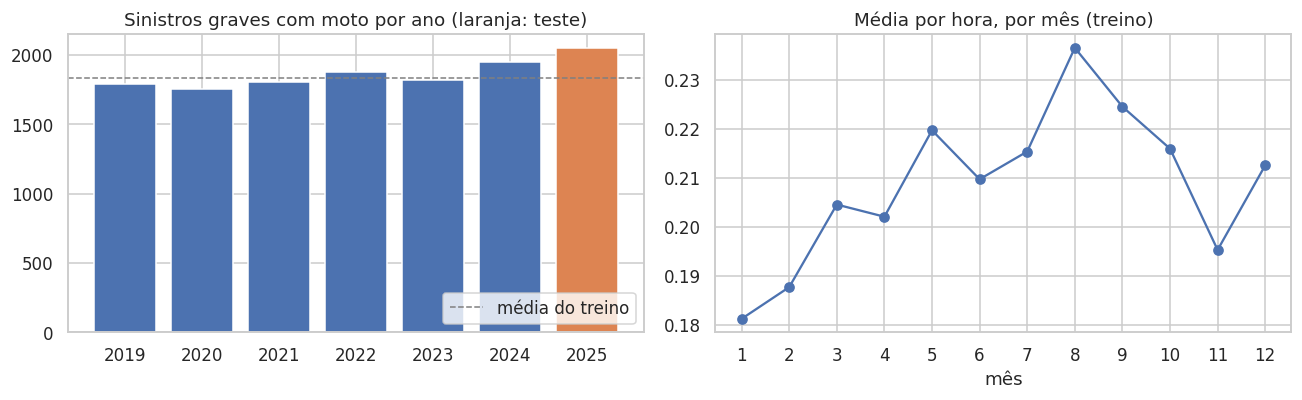

In [18]:
# Série anual e sazonalidade por mês

anual = base.groupby("ano").agg(sinistros_graves=("sinistros_graves", "sum"),
                                media_por_hora=("sinistros_graves", "mean"))
anual["variação vs. média do treino"] = anual["sinistros_graves"] / anual.loc[ANOS_TREINO, "sinistros_graves"].mean() - 1
print("=" * 70)
print("SINISTROS GRAVES COM MOTO POR ANO (todas as horas)")
print("=" * 70)
display(anual.style.format({"sinistros_graves": "{:,}", "media_por_hora": "{:.3f}",
                            "variação vs. média do treino": "{:+.1%}"}))

mensal = treino_eda.groupby("mes")["sinistros_graves"].mean()
print(f"Média por hora, por mês (treino): menor em {mensal.idxmin()} ({mensal.min():.3f}) e "
      f"maior em {mensal.idxmax()} ({mensal.max():.3f})")

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
cores = ["#4C72B0" if a in ANOS_TREINO else "#DD8452" for a in anual.index]
eixos[0].bar(anual.index.astype(str), anual["sinistros_graves"], color=cores)
eixos[0].axhline(anual.loc[ANOS_TREINO, "sinistros_graves"].mean(), color="gray", ls="--", lw=1,
                 label="média do treino")
eixos[0].set_title("Sinistros graves com moto por ano (laranja: teste)")
eixos[0].legend(loc="lower right")
eixos[1].plot(mensal.index, mensal.values, marker="o", color="#4C72B0")
eixos[1].set_xticks(range(1, 13))
eixos[1].set_title("Média por hora, por mês (treino)")
eixos[1].set_xlabel("mês")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item5_serie_anual_mensal.png", dpi=150, bbox_inches="tight")
plt.show()

### **5.3 Hora do dia e dia da semana (hipótese H1)**

O mapa de calor mostra a média de sinistros graves por hora em cada combinação de dia da semana e hora do dia. É o padrão que o calendário sozinho já explica, e é a base da linha de base "média por hora e dia da semana" do Item 7.

O gráfico ao lado responde a uma pergunta diferente: entre os sinistros com moto de cada hora, **que fração é grave?** O Item 2 mostrou quando os sinistros com moto acontecem. Aqui aparece quando eles são mais graves. Se a fração subir à noite, a madrugada pode ter poucos sinistros, mas mais violentos.

HORA DO DIA E DIA DA SEMANA (treino)
Média por hora: pico às 18h (0.319) e mínimo às 3h (0.098), razão de 3.2 vezes
Dia com maior média: sábado | menor: terça
% de sinistros com moto que são graves: de 7.7% (às 13h) a 29.1% (às 3h)


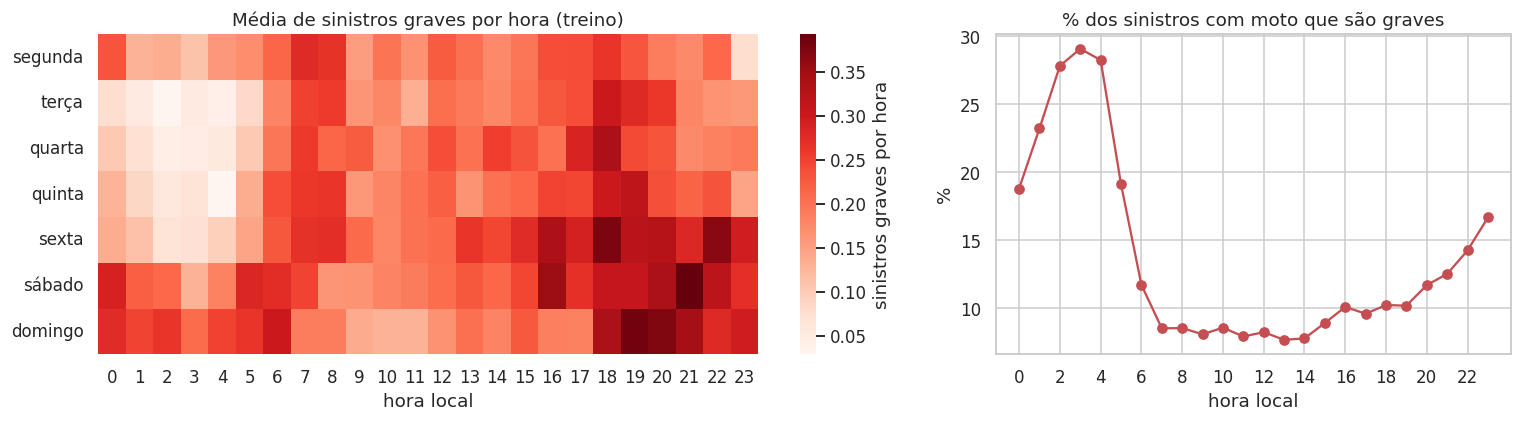

In [19]:
# Hora do dia e dia da semana: o padrão que o calendário sozinho já explica

mapa = treino_eda.pivot_table(index="dia_semana", columns="hora", values="sinistros_graves", aggfunc="mean")
mapa.index = DIAS_SEMANA

# Gravidade por hora: entre os sinistros com moto do treino, que fração teve vítima grave ou fatal
moto_treino = moto[moto["ano_sinistro"].isin(ANOS_TREINO) & moto["hora"].notna()]
gravidade_hora = moto_treino.groupby("hora")["tem_grave_fatal"].mean() * 100
por_hora = treino_eda.groupby("hora")["sinistros_graves"].mean()

print("=" * 70)
print("HORA DO DIA E DIA DA SEMANA (treino)")
print("=" * 70)
print(f"Média por hora: pico às {por_hora.idxmax()}h ({por_hora.max():.3f}) e mínimo às {por_hora.idxmin()}h "
      f"({por_hora.min():.3f}), razão de {por_hora.max() / por_hora.min():.1f} vezes")
print(f"Dia com maior média: {mapa.mean(axis=1).idxmax()} | menor: {mapa.mean(axis=1).idxmin()}")
print(f"% de sinistros com moto que são graves: de {gravidade_hora.min():.1f}% (às {gravidade_hora.idxmin()}h) "
      f"a {gravidade_hora.max():.1f}% (às {gravidade_hora.idxmax()}h)")

fig, eixos = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(mapa, cmap="Reds", ax=eixos[0], cbar_kws={"label": "sinistros graves por hora"})
eixos[0].set_title("Média de sinistros graves por hora (treino)")
eixos[0].set_xlabel("hora local")
eixos[0].set_ylabel("")
eixos[1].plot(gravidade_hora.index, gravidade_hora.values, marker="o", color="#C44E52")
eixos[1].set_xticks(range(0, 24, 2))
eixos[1].set_title("% dos sinistros com moto que são graves")
eixos[1].set_xlabel("hora local")
eixos[1].set_ylabel("%")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item5_hora_dia_semana.png", dpi=150, bbox_inches="tight")
plt.show()

### **5.4 Efeito do tempo e dos feriados na mesma hora (hipóteses H2 e H3)**

Para cada faixa de chuva, temperatura, umidade e para os feriados, a tabela mostra:

- a **média bruta** de sinistros graves por hora, que mistura o efeito do tempo com o do horário;
- o **observado** (total de sinistros graves nas horas da faixa) e o **esperado** (soma do normal de cada uma dessas horas, pela média histórica da mesma hora e do mesmo dia da semana);
- a **razão observado/esperado**, com intervalo de confiança de 95%.

As faixas de chuva seguem o Item 3: sem chuva, fraca (até 2 mm), moderada (de 2 a 10 mm) e forte (10 mm ou mais, quando o componente `chuva` do índice chega a 100). A célula também mostra a correlação entre as três variáveis do tempo, porque temperatura e umidade costumam andar juntas e o modelo precisa lidar com isso.

CHUVA: média bruta e razão observado / esperado na mesma hora (treino)


,horas,media_bruta,observado,esperado,razao_O_E,ic95_inf,ic95_sup
faixa_chuva,,,,,,,
1. sem chuva,"47,893",0.211,"10,125","9,973",1.02,1.00,1.04
2. fraca (até 2 mm),"2,877",0.170,488,611,0.80,0.73,0.87
3. moderada (2 a 10 mm),953,0.187,178,210,0.85,0.73,0.98
4. forte (10 mm ou mais),213,0.244,52,49,1.06,0.81,1.39


TEMPERATURA: média bruta e razão observado / esperado na mesma hora (treino)


,horas,media_bruta,observado,esperado,razao_O_E,ic95_inf,ic95_sup
faixa_temperatura,,,,,,,
1. abaixo de 15 °C,"4,838",0.194,940,939,1.00,0.94,1.07
2. 15 a 20 °C,"18,704",0.201,"3,761","3,797",0.99,0.96,1.02
3. 20 a 25 °C,"18,958",0.213,"4,029","4,097",0.98,0.95,1.01
4. 25 a 30 °C,"7,638",0.225,"1,722","1,630",1.06,1.01,1.11
5. 30 °C ou mais,"1,798",0.217,391,380,1.03,0.93,1.14


UMIDADE: média bruta e razão observado / esperado na mesma hora (treino)


,horas,media_bruta,observado,esperado,razao_O_E,ic95_inf,ic95_sup
faixa_umidade,,,,,,,
1. abaixo de 50%,"9,126",0.227,"2,073","1,967",1.05,1.01,1.10
2. 50 a 70%,"13,151",0.223,"2,930","2,804",1.04,1.01,1.08
3. 70 a 85%,"21,126",0.210,"4,428","4,452",0.99,0.97,1.02
4. 85 a 95%,"8,112",0.166,"1,349","1,538",0.88,0.83,0.93
5. 95% ou mais,421,0.150,63,82,0.77,0.60,0.99


FERIADO: média bruta e razão observado / esperado na mesma hora (treino)


,horas,media_bruta,observado,esperado,razao_O_E,ic95_inf,ic95_sup
dia,,,,,,,
dia comum,"49,812",0.209,"10,389","10,405",1.00,0.98,1.02
feriado,"2,124",0.214,454,438,1.04,0.94,1.14


Correlação entre as variáveis do tempo (treino):


,chuva_mm,temperatura_c,umidade_pct
chuva_mm,1.0000,-0.0400,0.1500
temperatura_c,-0.0400,1.0000,-0.6900
umidade_pct,0.1500,-0.6900,1.0000


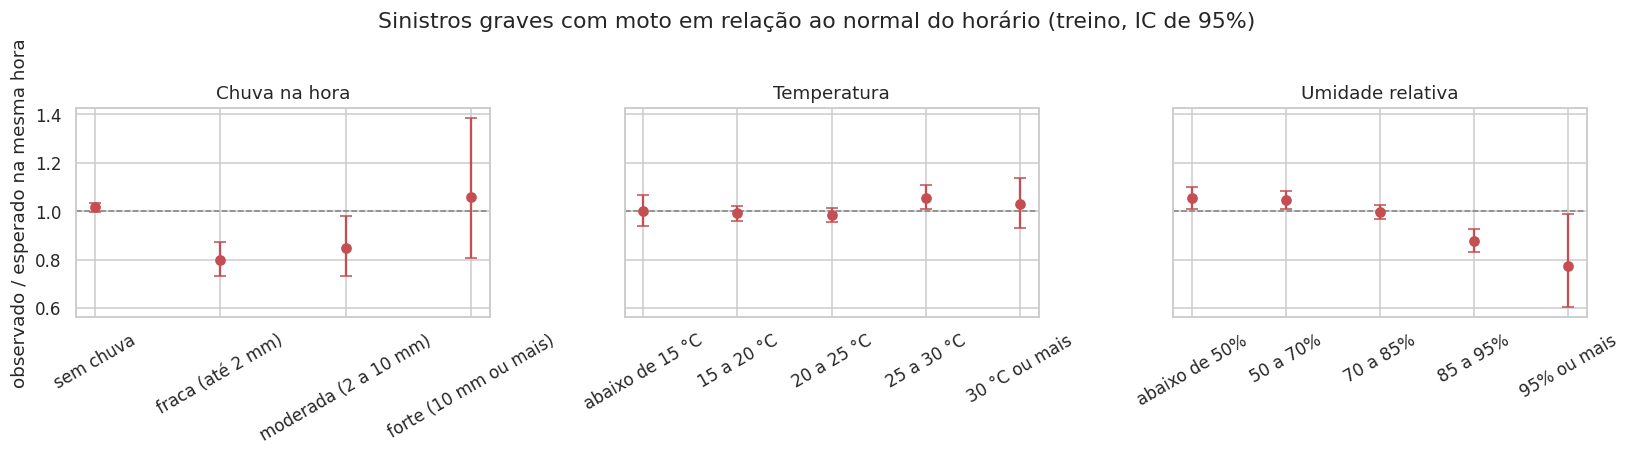

In [20]:
# Efeito do tempo e dos feriados NA MESMA HORA: razão entre observado e esperado

# Esperado de cada hora = média histórica (treino) daquela hora naquele dia da semana.
# Razão observado / esperado acima de 1 = mais sinistros graves do que o normal para aquele horário.
treino_eda["esperado"] = treino_eda.groupby(["hora", "dia_semana"])["sinistros_graves"].transform("mean")

treino_eda["faixa_chuva"] = np.select(
    [treino_eda["chuva_mm"] == 0, treino_eda["chuva_mm"] < 2, treino_eda["chuva_mm"] < 10],
    ["1. sem chuva", "2. fraca (até 2 mm)", "3. moderada (2 a 10 mm)"], "4. forte (10 mm ou mais)")
treino_eda["faixa_temperatura"] = pd.cut(treino_eda["temperatura_c"], [-np.inf, 15, 20, 25, 30, np.inf], right=False,
                                         labels=["1. abaixo de 15 °C", "2. 15 a 20 °C", "3. 20 a 25 °C",
                                                 "4. 25 a 30 °C", "5. 30 °C ou mais"])
treino_eda["faixa_umidade"] = pd.cut(treino_eda["umidade_pct"], [-np.inf, 50, 70, 85, 95, np.inf], right=False,
                                     labels=["1. abaixo de 50%", "2. 50 a 70%", "3. 70 a 85%",
                                             "4. 85 a 95%", "5. 95% ou mais"])
treino_eda["dia"] = np.where(treino_eda["feriado"] == 1, "feriado", "dia comum")


def razao_observado_esperado(coluna: str) -> pd.DataFrame:
    """Compara cada faixa com o normal da mesma hora e dia da semana, com intervalo de confiança de 95%."""
    g = treino_eda.groupby(coluna, observed=True).agg(
        horas=("sinistros_graves", "size"),
        media_bruta=("sinistros_graves", "mean"),
        observado=("sinistros_graves", "sum"),
        esperado=("esperado", "sum"),
    )
    g["razao_O_E"] = g["observado"] / g["esperado"]
    erro = 1.96 / np.sqrt(g["observado"].clip(lower=1))           # aproximação de Poisson para o total observado
    g["ic95_inf"], g["ic95_sup"] = g["razao_O_E"] * np.exp(-erro), g["razao_O_E"] * np.exp(erro)
    return g


formato = {"horas": "{:,}", "media_bruta": "{:.3f}", "observado": "{:,}", "esperado": "{:,.0f}",
           "razao_O_E": "{:.2f}", "ic95_inf": "{:.2f}", "ic95_sup": "{:.2f}"}
resultados = {}
for coluna, titulo in [("faixa_chuva", "CHUVA"), ("faixa_temperatura", "TEMPERATURA"),
                       ("faixa_umidade", "UMIDADE"), ("dia", "FERIADO")]:
    resultados[coluna] = razao_observado_esperado(coluna)
    print("=" * 70)
    print(f"{titulo}: média bruta e razão observado / esperado na mesma hora (treino)")
    print("=" * 70)
    display(resultados[coluna].style.format(formato))

print("Correlação entre as variáveis do tempo (treino):")
display(treino_eda[["chuva_mm", "temperatura_c", "umidade_pct"]].corr().round(2))

fig, eixos = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (coluna, titulo) in zip(eixos, [("faixa_chuva", "Chuva na hora"),
                                         ("faixa_temperatura", "Temperatura"),
                                         ("faixa_umidade", "Umidade relativa")]):
    g = resultados[coluna]
    rotulos = [str(i).split(". ", 1)[1] for i in g.index]
    ax.errorbar(rotulos, g["razao_O_E"], yerr=[g["razao_O_E"] - g["ic95_inf"], g["ic95_sup"] - g["razao_O_E"]],
                fmt="o", color="#C44E52", capsize=4)
    ax.axhline(1, color="gray", ls="--", lw=1)
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=30)
eixos[0].set_ylabel("observado / esperado na mesma hora")
fig.suptitle("Sinistros graves com moto em relação ao normal do horário (treino, IC de 95%)", y=1.03)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item5_efeito_tempo.png", dpi=150, bbox_inches="tight")
plt.show()

### **Discussão do Item 5**

#### **O alvo é quase uma Poisson pura (5.1)**

Nas 51.936 horas de treino, 81,44% não tiveram nenhum sinistro grave com moto, contra 81,16% esperados por uma Poisson com a mesma média (0,209). A variância (0,216) é só 4% maior que a média, e o máximo foi de 5 sinistros graves em uma hora. Isso tem duas consequências:

- **o objetivo de Poisson do XGBoost é a escolha certa** para este alvo;
- **o acaso pesa muito hora a hora.** Mesmo um modelo perfeito não acertaria quantos sinistros vão acontecer numa hora específica, só a média esperada. Por isso, as métricas hora a hora vão parecer modestas, e o que importa é comparar o modelo com as linhas de base (hipótese H4). Prever sempre 0 já dá MAE de 0,209, sem nenhum valor para o entregador.

#### **Tendência de alta recente (5.2)**

De 2019 a 2023, o total anual ficou perto da média do treino (de 4,2% abaixo a 2,4% acima). Depois subiu: 1.947 em 2024 (+6,4%) e 2.045 em 2025 (+11,7%). Em 2022, o ano em que os sinistros fatais saltaram no Item 1, o alvo subiu só 2,4%, o que confirma que somar graves e fatais protege o alvo da mudança de registro entre as duas categorias. Como o ano fica fora do modelo, é esperado que ele preveja um nível abaixo do observado em 2025. O Item 9 mede esse viés.

#### **Sazonalidade por mês (5.2)**

A média por hora vai de 0,181 em janeiro a 0,237 em agosto (31% a mais), com setembro também alto (0,224) e novembro mais baixo (0,195). O mês mais seguro é janeiro, que é justamente o de mais chuva e de férias escolares, e o mais perigoso é agosto, no meio da estação seca. Isso sugere que o volume de deslocamentos pesa mais que o tempo, o que antecipa o resultado de 5.4. O mês entra no modelo para capturar esse padrão.

#### **H1 confirmada: o horário é o fator dominante (5.3)**

A média vai de 0,098 sinistro grave por hora às 3h a 0,319 às 18h, uma diferença de 3,2 vezes. O mapa de calor mostra dois padrões:

- **dias úteis:** picos nos horários de deslocamento (7h a 8h e 17h a 19h) e madrugadas calmas, sobretudo de terça a quinta;
- **fins de semana e sexta à noite:** as noites ficam tão perigosas quanto os picos dos dias úteis. A célula mais escura é sábado às 21h, seguida de domingo entre 19h e 20h. Sábado tem a maior média diária e terça, a menor.

#### **De madrugada, os sinistros são poucos, mas muito mais graves (5.3)**

Entre os sinistros com moto, a fração com vítima grave ou fatal vai de 7,7% às 13h a 29,1% às 3h, quase 4 vezes mais. As causas prováveis (velocidade, visibilidade, álcool) não estão na base e ficam como hipótese. Também é possível que sinistros leves da madrugada sejam menos registrados, o que aumentaria essa fração. Para o entregador, a leitura é que o horário de menos movimento não é o mais seguro: quando um sinistro acontece, tem muito mais chance de ser grave.

#### **H2 não confirmada: na mesma hora, chuva fraca e moderada vêm com menos sinistros graves (5.4)**

Comparando cada hora com o normal do mesmo horário e dia da semana:

| Chuva na hora | Horas | Razão observado/esperado | IC de 95% |
|---|---|---|---|
| Sem chuva | 47.893 | 1,02 | 1,00 a 1,04 |
| Fraca (até 2 mm) | 2.877 | 0,80 | 0,73 a 0,87 |
| Moderada (2 a 10 mm) | 953 | 0,85 | 0,73 a 0,98 |
| Forte (10 mm ou mais) | 213 | 1,06 | 0,81 a 1,39 |

Nas horas de chuva fraca, houve 20% menos sinistros graves do que o normal para aqueles horários, e nas de chuva moderada, 15% menos, com intervalos que não incluem 1. Na chuva forte, a razão é de 1,06, mas com só 213 horas o intervalo vai de 0,81 a 1,39 e não permite conclusão. A média bruta da chuva forte (0,244) parece alta só porque os temporais caem à tarde, no horário de pico. Esse é exatamente o engano que a comparação na mesma hora evita.

Isso **não significa que pilotar na chuva seja seguro.** É uma associação com o número de sinistros graves, não o risco de cada viagem. A explicação mais provável é a **exposição**: com chuva, parte dos motociclistas para, adia viagens ou anda mais devagar. Há também uma força no sentido contrário, a demanda por entregas, que costuma subir com chuva. Sem o volume de motos circulando, os dados públicos não permitem separar esses efeitos. Esse é o limite já anunciado na Introdução, que volta na conclusão.

#### **H3: a temperatura quase não muda o quadro, e a umidade alta acompanha menos sinistros (5.4)**

Na mesma hora, só a faixa de 25 a 30 °C fica um pouco acima do normal (1,06, com IC de 1,01 a 1,11), e as outras faixas ficam em torno de 1. A umidade tem um padrão mais claro: acima de 85%, os sinistros graves ficam 12% abaixo do normal (0,88), e acima de 95%, 23% abaixo (0,77). A umidade alta acompanha chuva, garoa e neblina (correlação de 0,15 com a chuva), então provavelmente capta o mesmo efeito de exposição. Temperatura e umidade são fortemente ligadas (correlação de -0,69). As árvores lidam bem com isso, mas a importância de uma pode aparecer dividida com a outra no Item 9.

#### **Feriados (5.4)**

Na mesma hora e no mesmo dia da semana, os feriados ficam 4% acima do normal, com intervalo de 0,94 a 1,14, sem efeito claro. A variável continua no modelo porque faz parte do Contrato e pode ajudar combinada com o dia da semana.

#### **Veredito preliminar das hipóteses**

| Hipótese | Resultado da análise exploratória |
|---|---|
| H1 (horário) | **Confirmada.** Variação de 3,2 vezes ao longo do dia, com picos de deslocamento nos dias úteis e noites perigosas nos fins de semana |
| H2 (chuva aumenta os sinistros graves) | **Não confirmada.** Na mesma hora, chuva fraca e moderada vêm com 15% a 20% menos sinistros graves. Chuva forte é inconclusiva |
| H3 (temperatura e umidade com efeito menor) | **Parcialmente.** A temperatura tem efeito pequeno. A umidade alta acompanha menos sinistros, provavelmente pelo mesmo motivo da chuva |
| H4 (tempo acrescenta pouco hora a hora) | **Coerente com os dados.** Alvo quase Poisson e 81% de horas zeradas. O teste definitivo é a ablação do Item 9 |

#### **Conclusão do Item 5**

Os dados estão prontos para a modelagem, e as expectativas ficam registradas: o calendário deve explicar a maior parte do que é previsível, o tempo deve acrescentar pouco, e o efeito da chuva, se aparecer, deve ser de redução na contagem. O modelo vai testar isso com todas as variáveis ao mesmo tempo, e a ablação do Item 9 mede o quanto o tempo realmente acrescenta.

## **Item 6: Escolha justificada do modelo, variáveis e divisão treino/teste**

Este item fecha três decisões antes de qualquer treino:

- **6.1** qual modelo usar entre os cinco permitidos pelo enunciado, e por quê;
- **6.2** quais variáveis entram e como os dados são divididos em treino e teste;
- **6.3** como a validação cruzada é feita dentro do treino.

A partir daqui, a modelagem lê a base do arquivo versionado `dados/processados/base_horaria.parquet`, e não da memória dos itens anteriores. Assim, quem clonar o repositório consegue reproduzir os Itens 6 a 10 sem baixar os dados brutos.

### **6.1 Escolha justificada do modelo**

#### **O que o problema pede (Itens 2 a 5):**

- prever uma **contagem por hora**, quase sempre 0 ou 1 (81% das horas zeradas, média de 0,21 e variância praticamente igual à média, como numa Poisson);
- usar **7 variáveis tabulares**: hora, dia da semana, mês, feriado, chuva, temperatura e umidade;
- capturar **interações**: o mapa de calor do Item 5 mostra que o efeito da hora depende do dia da semana (as noites perigosas são as de sexta, sábado e domingo);
- devolver **um número não negativo**, a quantidade esperada, que o Serviço de Risco transforma no componente `sinistro`;
- usar **somente as entradas que o Serviço de Risco recebe** (Contrato v1.8, seção 8.1): a hora do turno e a previsão do tempo, sem histórico de horas anteriores.

#### **Os cinco modelos permitidos:**

| Modelo | Como seria usado aqui | Avaliação |
|---|---|---|
| KMeans + PCA | Agruparia horas parecidas | **Não serve.** É não supervisionado e não prevê quantidade, e a pergunta é "quantos sinistros graves são esperados" |
| LSTM | Aprenderia a sequência das horas | **Não serve.** O Serviço de Risco não recebe a sequência das horas anteriores, só a previsão do turno. Além disso, um alvo raro (81% de zeros) com 52 mil horas é pouco para uma rede recorrente |
| MLP | Rede densa com saída de Poisson (o tipo de rede do CP5) | **Possível, mas pior para este caso.** Exige padronizar as entradas, codificar a hora de forma cíclica e ajustar muitos hiperparâmetros, e é a menos interpretável. Em tabelas pequenas, os modelos de árvores costumam ser mais precisos |
| Random Forest | Média de muitas árvores profundas, independentes entre si | **Boa alternativa.** Captura interações e foi vista em aula. Mas cada árvore aprende sozinha, e com um alvo tão raro a média de árvores profundas fica ruidosa. A exportação também exigiria um pickle, que o Contrato evita |
| **XGBoost** | Árvores pequenas treinadas em sequência, cada uma corrigindo o erro das anteriores | **Escolhido** |

#### **Por que o XGBoost:**

1. **Objetivo de Poisson (`count:poisson`):** o modelo trabalha na escala do logaritmo, então a previsão é sempre positiva e os efeitos são multiplicativos ("nesta hora, a chuva multiplica o esperado por 0,85"), que é a forma natural de falar de taxas de eventos raros. É o formato que o Item 5 encontrou nos dados.
2. **Interações sem trabalho manual:** cada árvore combina várias variáveis (por exemplo, hora, dia da semana e chuva), sem precisar criar colunas de interação.
3. **Variáveis correlacionadas:** temperatura e umidade têm correlação de -0,69 (Item 5). Árvores não sofrem com isso como uma regressão linear, embora a importância possa se dividir entre as duas.
4. **Rápido em CPU:** cerca de 1 segundo por treino, o que permite testar 27 combinações com validação cruzada.
5. **Exportação estável:** o formato JSON nativo do XGBoost é o arquivo que o Contrato v1.8 pede (`modelo_sinistros_xgb.json`).

**Como o XGBoost funciona, em uma frase:** ele soma as respostas de muitas árvores pequenas, cada uma ajustada para corrigir o que as anteriores ainda erram, e no objetivo de Poisson a previsão final é a exponencial dessa soma.

#### **Os três hiperparâmetros da grade (Item 8):**

| Hiperparâmetro | O que controla | Valores | Efeito esperado |
|---|---|---|---|
| `n_estimators` | Quantas árvores são somadas | 200, 400 e 800 | Mais árvores aprendem mais detalhes, mas podem decorar o acaso do treino |
| `max_depth` | Profundidade de cada árvore, ou quantas perguntas ela faz em sequência | 3, 5 e 7 | Profundidade 3 combina até 3 variáveis por caminho. Árvores mais fundas capturam interações mais específicas e se ajustam mais ao treino |
| `learning_rate` | Peso de cada nova árvore na soma | 0,03, 0,1 e 0,3 | Valores pequenos aprendem devagar e pedem mais árvores. Valores grandes aprendem rápido, mas tendem a se ajustar demais |

Os três interagem: `learning_rate` × `n_estimators` dá, aproximadamente, o quanto o modelo "aprende" no total. A grade vai de modelos que devem ficar simples demais (0,03 com 200 árvores rasas) até modelos que devem decorar o treino (0,3 com 800 árvores de profundidade 7), para que o Item 9 mostre os dois lados.

**Parâmetros fixos:** `tree_method="hist"` (rápido em CPU), `random_state=42` e `n_jobs=2` (os 2 núcleos do Colab). Os demais ficam no padrão da biblioteca. Por exemplo, sem subamostragem, o treino é determinístico. Em todos os treinos, a única coisa que muda são os três hiperparâmetros da grade.

### **6.2 Variáveis finais e divisão temporal**

**Variáveis de entrada:** `hora`, `dia_semana`, `mes`, `feriado`, `chuva_mm`, `temperatura_c` e `umidade_pct`. São exatamente as que o Serviço de Risco consegue montar a partir do `POST /indice-turno`. O `ano` fica fora, como definido no protocolo.

**Divisão:** treino com todas as horas de 2019 a 2024 e teste com todas as horas de 2025, sempre só as horas com tempo completo. O teste é usado **uma única vez**, no Item 9, depois de escolhida a melhor combinação. A divisão por ano simula o uso real: o modelo é treinado com o passado e usado num período que ele nunca viu. Uma divisão aleatória colocaria horas vizinhas (e muito parecidas) dos dois lados e daria uma nota otimista demais.

A célula confere, no próprio código, que treino e teste não têm nenhuma hora em comum, que todo o teste vem depois do treino e que nenhuma variável está vazia. Depois compara as variáveis de entrada nos dois conjuntos. Se 2025 tivesse um tempo muito diferente dos anos de treino (por exemplo, muito mais chuva), parte do erro de teste viria dessa mudança, e não do modelo.

In [21]:
# Variáveis finais e divisão temporal entre treino e teste

ARQ_BASE = DIR_PROCESSADOS / "base_horaria.parquet"
base = pd.read_parquet(ARQ_BASE)            # a modelagem parte do arquivo versionado, não da memória

# Variáveis de entrada: só o que o Serviço de Risco monta a partir do POST /indice-turno (Contrato v1.8, 8.1)
VARIAVEIS_CALENDARIO = ["hora", "dia_semana", "mes", "feriado"]
VARIAVEIS_TEMPO = ["chuva_mm", "temperatura_c", "umidade_pct"]
VARIAVEIS = VARIAVEIS_CALENDARIO + VARIAVEIS_TEMPO
COLUNA_ALVO = "sinistros_graves"

# Protocolo: horas sem tempo completo ficam fora do treino e do teste
dados = base[base["tempo_completo"]].sort_values("datahora_local").reset_index(drop=True)
treino = dados[dados["ano"].isin(ANOS_TREINO)].reset_index(drop=True)
teste = dados[dados["ano"] == ANO_TESTE].reset_index(drop=True)

X_treino, y_treino = treino[VARIAVEIS], treino[COLUNA_ALVO]
X_teste, y_teste = teste[VARIAVEIS], teste[COLUNA_ALVO]

# Conferências da divisão: nenhuma hora em comum e o teste inteiro depois do treino
assert set(treino["datahora_local"]).isdisjoint(teste["datahora_local"]), "treino e teste não podem se sobrepor"
assert treino["datahora_local"].max() < teste["datahora_local"].min(), "o teste precisa vir depois do treino"
assert not X_treino.isna().any().any() and not X_teste.isna().any().any(), "não pode haver variável vazia"

print("=" * 70)
print("VARIÁVEIS E DIVISÃO TREINO / TESTE")
print("=" * 70)
print(f"Variáveis de entrada ({len(VARIAVEIS)}): {', '.join(VARIAVEIS)}")
print(f"Alvo: {COLUNA_ALVO} (sinistros graves com moto na hora local)\n")

divisao = pd.DataFrame({
    "conjunto": ["treino", "teste"],
    "período": [f"{treino['datahora_local'].min():%d/%m/%Y %Hh} a {treino['datahora_local'].max():%d/%m/%Y %Hh}",
                f"{teste['datahora_local'].min():%d/%m/%Y %Hh} a {teste['datahora_local'].max():%d/%m/%Y %Hh}"],
    "horas": [len(treino), len(teste)],
    "% das horas": [len(treino) / len(dados) * 100, len(teste) / len(dados) * 100],
    "sinistros graves": [int(y_treino.sum()), int(y_teste.sum())],
    "média por hora": [y_treino.mean(), y_teste.mean()],
})
display(divisao.style.format({"horas": "{:,}", "% das horas": "{:.1f}%", "sinistros graves": "{:,}",
                              "média por hora": "{:.3f}"}).hide(axis="index"))

# O teste se parece com o treino nas variáveis de entrada? (mudança de distribuição entre os anos)
comparacao_entradas = pd.DataFrame({
    "treino": [X_treino["chuva_mm"].gt(0).mean() * 100, X_treino["chuva_mm"].mean(), X_treino["temperatura_c"].mean(),
               X_treino["umidade_pct"].mean(), X_treino["feriado"].mean() * 100],
    "teste": [X_teste["chuva_mm"].gt(0).mean() * 100, X_teste["chuva_mm"].mean(), X_teste["temperatura_c"].mean(),
              X_teste["umidade_pct"].mean(), X_teste["feriado"].mean() * 100],
}, index=["% das horas com chuva", "chuva média (mm/h)", "temperatura média (°C)", "umidade média (%)",
          "% das horas em feriado"])
print("Variáveis de entrada no treino e no teste:")
display(comparacao_entradas.round(2))
print(f"Faixas no treino: chuva de {X_treino['chuva_mm'].min():.1f} a {X_treino['chuva_mm'].max():.1f} mm, "
      f"temperatura de {X_treino['temperatura_c'].min():.1f} a {X_treino['temperatura_c'].max():.1f} °C, "
      f"umidade de {X_treino['umidade_pct'].min():.0f} a {X_treino['umidade_pct'].max():.0f}%")
print(f"Horas de teste fora dessas faixas: "
      f"{int(((X_teste['chuva_mm'] > X_treino['chuva_mm'].max()) | (X_teste['temperatura_c'] > X_treino['temperatura_c'].max()) | (X_teste['temperatura_c'] < X_treino['temperatura_c'].min())).sum())}")

VARIÁVEIS E DIVISÃO TREINO / TESTE
Variáveis de entrada (7): hora, dia_semana, mes, feriado, chuva_mm, temperatura_c, umidade_pct
Alvo: sinistros_graves (sinistros graves com moto na hora local)



conjunto,período,horas,% das horas,sinistros graves,média por hora
treino,01/01/2019 00h a 31/12/2024 23h,"51,936",85.6%,"10,843",0.209
teste,01/01/2025 00h a 31/12/2025 19h,"8,709",14.4%,"2,025",0.233


Variáveis de entrada no treino e no teste:


,treino,teste
% das horas com chuva,7.7800,6.4900
chuva média (mm/h),0.1800,0.1700
temperatura média (°C),20.7400,20.4300
umidade média (%),68.0700,68.2600
% das horas em feriado,4.0900,4.1200


Faixas no treino: chuva de 0.0 a 67.6 mm, temperatura de 4.4 a 37.3 °C, umidade de 12 a 100%
Horas de teste fora dessas faixas: 1


### **6.3 Validação cruzada: 5 dobras expansivas por ano**

A validação cruzada escolhe a melhor combinação de hiperparâmetros **sem tocar no teste**. Ela usa só os 6 anos de treino, sempre respeitando a ordem do tempo: cada dobra treina com os anos anteriores e valida no ano seguinte.

| Dobra | Treina com | Valida em |
|---|---|---|
| 1 | 2019 | 2020 |
| 2 | 2019 e 2020 | 2021 |
| 3 | 2019 a 2021 | 2022 |
| 4 | 2019 a 2022 | 2023 |
| 5 | 2019 a 2023 | 2024 |

**Por que assim, e não com o `KFold` comum ou o `TimeSeriesSplit` do scikit-learn:**

- o `KFold` embaralharia horas de anos diferentes e usaria o futuro para prever o passado;
- o `TimeSeriesSplit` corta a série em blocos de mesmo tamanho, que não coincidem com os anos e deixariam estações do ano incompletas na validação;
- com um ano inteiro em cada validação, todas as estações aparecem, e cada dobra imita o uso real (treinar com o passado e usar no ano seguinte).

**Ponto de atenção:** a dobra 1 treina só com 2019 e valida em 2020, o ano da pandemia. É de esperar que seja a pior das cinco. A seleção usa a média das cinco dobras, e o Item 8 mostra o resultado de cada uma.

As dobras ficam na lista `DOBRAS_CV`, no formato que o `GridSearchCV` aceita diretamente.

In [22]:
# Validação cruzada: 5 dobras expansivas por ano, só dentro do treino

anos_hora = treino["ano"].to_numpy()
DOBRAS_CV = []                      # lista de (posições de treino, posições de validação), no formato do GridSearchCV
linhas = []
for ano_validacao in ANOS_TREINO[1:]:                     # 2020 a 2024
    pos_treino = np.where(anos_hora < ano_validacao)[0]
    pos_validacao = np.where(anos_hora == ano_validacao)[0]
    # A dobra só vale se tudo o que treina vier antes do que valida
    assert treino.loc[pos_treino, "datahora_local"].max() < treino.loc[pos_validacao, "datahora_local"].min()
    DOBRAS_CV.append((pos_treino, pos_validacao))
    linhas.append({
        "dobra": len(DOBRAS_CV),
        "treina com": f"{ANOS_TREINO[0]}" if ano_validacao == ANOS_TREINO[1] else f"{ANOS_TREINO[0]} a {ano_validacao - 1}",
        "valida em": ano_validacao,
        "horas de treino": len(pos_treino),
        "horas de validação": len(pos_validacao),
        "sinistros graves na validação": int(y_treino.iloc[pos_validacao].sum()),
        "média por hora na validação": y_treino.iloc[pos_validacao].mean(),
    })

print("=" * 70)
print("DOBRAS DA VALIDAÇÃO CRUZADA (expansivas, por ano, só no treino)")
print("=" * 70)
display(pd.DataFrame(linhas).style.format({"horas de treino": "{:,}", "horas de validação": "{:,}",
                                           "sinistros graves na validação": "{:,}",
                                           "média por hora na validação": "{:.3f}"}).hide(axis="index"))
anos_nas_dobras = sorted(set(treino.loc[np.concatenate([np.r_[a, b] for a, b in DOBRAS_CV]), "ano"]))
print(f"Anos usados nas dobras: {anos_nas_dobras} (o teste, {ANO_TESTE}, fica de fora)")

DOBRAS DA VALIDAÇÃO CRUZADA (expansivas, por ano, só no treino)


dobra,treina com,valida em,horas de treino,horas de validação,sinistros graves na validação,média por hora na validação
1,2019,2020,"8,760","8,782","1,753",0.200
2,2019 a 2020,2021,"17,542","8,758","1,804",0.206
3,2019 a 2021,2022,"26,300","8,759","1,874",0.214
4,2019 a 2022,2023,"35,059","8,113","1,680",0.207
5,2019 a 2023,2024,"43,172","8,764","1,945",0.222


Anos usados nas dobras: [2019, 2020, 2021, 2022, 2023, 2024] (o teste, 2025, fica de fora)


### **Discussão do Item 6**

#### **Divisão (6.2)**

O treino tem 51.936 horas (85,6%) e 10.843 sinistros graves, uma média de 0,209 por hora. O teste tem 8.709 horas (14,4%) e 2.025 sinistros graves, uma média de 0,233. O teste termina às 19h de 31/12/2025, porque as últimas 4 horas do ano não têm dados do tempo (Item 3). As conferências do código passaram: nenhuma hora em comum, todo o teste depois do treino e nenhuma variável vazia.

#### **O tempo de 2025 se parece com o dos anos de treino (6.2)**

Temperatura média (20,4 contra 20,7 °C), umidade (68,3% contra 68,1%), chuva média por hora (0,17 contra 0,18 mm) e horas de feriado (4,1% nos dois) praticamente não mudam. A única diferença visível é que 2025 teve menos horas com chuva (6,5% contra 7,8%), o que confirma o Item 3. Pelo Item 5, horas com chuva fraca ou moderada têm de 15% a 20% menos sinistros graves. Com 1,3 ponto percentual a menos de horas chuvosas, isso explicaria um aumento de no máximo cerca de 0,3% nos sinistros, muito longe dos 11,5% a mais que o teste tem em relação ao treino. **O aumento de 2025 vem do volume de sinistros graves, e não de um tempo diferente.** É essa diferença de nível que o Item 9 vai medir.

#### **Uma hora de teste fora da faixa do treino**

No treino, a chuva vai até 67,6 mm por hora. A hora de 82 mm vista no Item 3 está em 2025, e é a única hora de teste fora das faixas. Árvores não extrapolam: para o modelo, qualquer chuva acima do maior corte aprendido vale o mesmo que esse corte. O efeito no teste é desprezível (1 hora em 8.709), mas a regra vale também para o Serviço de Risco. Uma previsão de chuva acima de 67,6 mm por hora recebe a mesma resposta do modelo que um valor próximo desse limite. As faixas do treino vão para o `metadados_modelo.json` (Item 10).

#### **Dobras (6.3)**

As 5 dobras têm cerca de 8,8 mil horas de validação cada. A exceção é 2023, com 8.113 horas, por causa das lacunas do pluviômetro (Item 3). O treino cresce de 8.760 horas (só 2019) a 43.172 (2019 a 2023). A média de sinistros graves na validação vai de 0,200 (2020, a pandemia) a 0,222 (2024). Então a própria validação cruzada já enfrenta uma pequena mudança de nível a cada ano, em especial na dobra 5. Isso é bom: a validação simula a mesma situação do teste, e a nota dela não fica otimista demais.

#### **Conclusão do Item 6**

O modelo (XGBoost com objetivo de Poisson), as 7 variáveis, a divisão temporal e as dobras estão definidos e conferidos. O próximo passo é medir quanto as linhas de base acertam, para saber o que o modelo precisa superar.

## **Item 7: Linhas de base**

Um modelo só vale a pena se fizer melhor do que regras simples que qualquer pessoa calcularia com uma planilha. Este item mede três **linhas de base**, todas médias históricas:

| Linha de base | O que prevê para uma hora |
|---|---|
| Média geral | A média de sinistros graves por hora de todo o período de ajuste, igual para qualquer hora |
| Média por hora | A média histórica daquela hora do dia (a "média histórica por hora" da Ficha da CitizenTech) |
| Média por hora e dia da semana | A média histórica daquela hora naquele dia da semana (o padrão do mapa de calor do Item 5) |

Elas são avaliadas **exatamente como o modelo será**, nos mesmos três conjuntos:

- **treino:** ajusta e avalia nos mesmos dados de 2019 a 2024 (desempenho dentro da amostra);
- **validação:** as mesmas 5 dobras do Item 6, ajustando a média só nos anos anteriores a cada ano de validação;
- **teste:** ajusta em 2019 a 2024 e avalia em 2025.

### **Métricas (as mesmas nos Itens 7 a 9):**

| Métrica | Como ler |
|---|---|
| MAE | Erro médio, em sinistros graves por hora. Menor é melhor |
| RMSE | Como o MAE, mas pune mais os erros grandes. Menor é melhor |
| Deviance de Poisson | A métrica própria para contagens e a usada para escolher o modelo (Item 8). Menor é melhor |
| D² | Fração da deviance explicada em relação a prever a média constante do próprio conjunto. 0% = igual à média, valores maiores são melhores, e pode ser negativo |
| Viés de nível | Soma prevista dividida pela soma real, menos 1. Um valor de -10% significa que a previsão somou 10% menos sinistros do que aconteceu |

### **Dois cuidados de leitura:**

1. **No teste, o D² compara com a média do próprio ano de 2025**, que nenhuma previsão feita com 2019 a 2024 conhecia. Com o aumento de nível de 2025, até uma boa previsão pode ter D² perto de zero ou negativo. Por isso, o viés de nível aparece separado: ele mostra quanto do erro vem só da mudança de nível.
2. **Prever sempre zero** tem MAE baixo (0,233 no teste), mas deviance infinita e viés de -100%. É o exemplo do Item 5 de por que o MAE sozinho engana.

A função `avaliar` criada aqui é reutilizada no Item 9, para a comparação final lado a lado.

### **7.1 Métricas das linhas de base em treino, validação e teste**

A célula define a função `avaliar` e a função `prever_media`. Esta última calcula a média do alvo em cada grupo (hora, ou hora e dia da semana) só com os dados que a linha de base pode ver e, se um grupo não existir, usa a média geral. Depois avalia as três linhas de base nos três conjuntos. Na validação, as métricas mostradas são a média das 5 dobras.

In [23]:
# Métricas comuns aos Itens 7 a 9 e as três linhas de base

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance, d2_tweedie_score


def avaliar(y_real, y_previsto) -> dict:
    """Métricas de contagem: erro médio, erro quadrático, deviance de Poisson, D² e viés de nível."""
    y_real = np.asarray(y_real, dtype=float)
    y_previsto = np.clip(np.asarray(y_previsto, dtype=float), 1e-9, None)   # Poisson exige previsão positiva
    return {
        "MAE": mean_absolute_error(y_real, y_previsto),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_previsto)),
        "deviance_poisson": mean_poisson_deviance(y_real, y_previsto),
        "D2": d2_tweedie_score(y_real, y_previsto, power=1),
        "vies_nivel": y_previsto.sum() / y_real.sum() - 1,                    # soma prevista contra soma real
    }


# Cada linha de base é uma "média histórica" calculada só nos dados que ela pode ver
LINHAS_DE_BASE = {
    "média geral": [],
    "média por hora": ["hora"],
    "média por hora e dia da semana": ["hora", "dia_semana"],
}


def prever_media(df_ajuste: pd.DataFrame, df_prever: pd.DataFrame, chaves: list) -> np.ndarray:
    """Prevê a média do alvo no grupo da hora (ou a média geral, se o grupo não existir no ajuste)."""
    media_geral = df_ajuste[COLUNA_ALVO].mean()
    if not chaves:
        return np.full(len(df_prever), media_geral)
    medias = df_ajuste.groupby(chaves)[COLUNA_ALVO].mean().rename("prev")
    return df_prever[chaves].merge(medias, left_on=chaves, right_index=True, how="left")["prev"].fillna(media_geral).to_numpy()


linhas = []
for nome, chaves in LINHAS_DE_BASE.items():
    # Treino: ajusta e avalia nos mesmos dados (desempenho "dentro da amostra")
    m_treino = avaliar(y_treino, prever_media(treino, treino, chaves))
    # Validação cruzada: mesmas 5 dobras do Item 6, ajustando só nos anos anteriores
    m_dobras = [avaliar(y_treino.iloc[v], prever_media(treino.iloc[t], treino.iloc[v], chaves)) for t, v in DOBRAS_CV]
    m_cv = {k: np.mean([m[k] for m in m_dobras]) for k in m_dobras[0]}
    # Teste: ajusta em 2019 a 2024 e avalia em 2025
    m_teste = avaliar(y_teste, prever_media(treino, teste, chaves))
    for conjunto, m in [("treino", m_treino), ("validação (média das 5 dobras)", m_cv), ("teste (2025)", m_teste)]:
        linhas.append({"linha de base": nome, "conjunto": conjunto, **m})

RESULTADOS_LINHAS_DE_BASE = pd.DataFrame(linhas)
print("=" * 70)
print("LINHAS DE BASE: MÉTRICAS EM TREINO, VALIDAÇÃO E TESTE")
print("=" * 70)
display(RESULTADOS_LINHAS_DE_BASE.style.format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "deviance_poisson": "{:.4f}",
                                                "D2": "{:.2%}", "vies_nivel": "{:+.1%}"}).hide(axis="index"))
print("Leitura: MAE, RMSE e deviance quanto menor, melhor; D² quanto maior, melhor (0% = prever a média constante).")
print(f"Referência: prever sempre 0 teria MAE de {y_teste.mean():.4f} no teste, mas deviance infinita e viés de -100%.")

LINHAS DE BASE: MÉTRICAS EM TREINO, VALIDAÇÃO E TESTE


linha de base,conjunto,MAE,RMSE,deviance_poisson,D2,vies_nivel
média geral,treino,0.3401,0.4652,0.7208,0.00%,-0.0%
média geral,validação (média das 5 dobras),0.3378,0.4662,0.7228,-0.05%,-2.5%
média geral,teste (2025),0.3576,0.5018,0.7743,-0.34%,-10.2%
média por hora,treino,0.3347,0.4617,0.7046,2.25%,+0.0%
média por hora,validação (média das 5 dobras),0.3327,0.4633,0.7095,1.78%,-2.5%
média por hora,teste (2025),0.3519,0.4980,0.7564,1.98%,-10.2%
média por hora e dia da semana,treino,0.3300,0.4585,0.6880,4.54%,+0.0%
média por hora e dia da semana,validação (média das 5 dobras),0.3288,0.4628,0.7081,1.95%,-2.5%
média por hora e dia da semana,teste (2025),0.3487,0.4967,0.7485,3.00%,-10.2%


Leitura: MAE, RMSE e deviance quanto menor, melhor; D² quanto maior, melhor (0% = prever a média constante).
Referência: prever sempre 0 teria MAE de 0.2325 no teste, mas deviance infinita e viés de -100%.


### **7.2 Perfil por hora no ano de teste**

O gráfico compara, para cada hora do dia, a média de sinistros graves observada em 2025 com o que a melhor linha de base esperada (média por hora e dia da semana, ajustada em 2019 a 2024) previa. Ele mostra se o aumento de 2025 aconteceu em todas as horas por igual (uma mudança de nível geral) ou se concentrou em alguns horários. A figura é salva em `figuras/item7_linha_de_base_por_hora.png`.

PERFIL POR HORA NO TESTE (média de sinistros graves por hora)
Horas do dia em que 2025 ficou acima da linha de base: 21 de 24
Maior diferença: às 12h (+31%) | menor: às 22h (-8%)


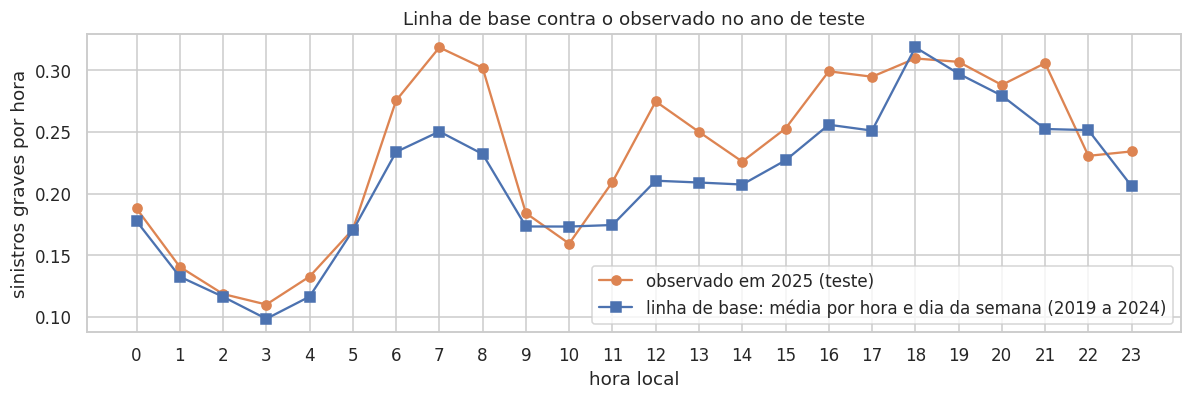

In [24]:
# Perfil por hora: o que a melhor linha de base prevê para 2025 e o que aconteceu

perfil_teste = teste.assign(previsto=prever_media(treino, teste, ["hora", "dia_semana"])).groupby("hora").agg(
    observado_2025=(COLUNA_ALVO, "mean"), previsto_linha_de_base=("previsto", "mean"))
perfil_teste["media_treino"] = treino.groupby("hora")[COLUNA_ALVO].mean()

print("=" * 70)
print("PERFIL POR HORA NO TESTE (média de sinistros graves por hora)")
print("=" * 70)
diferenca = perfil_teste["observado_2025"] / perfil_teste["previsto_linha_de_base"] - 1
print(f"Horas do dia em que 2025 ficou acima da linha de base: {(diferenca > 0).sum()} de 24")
print(f"Maior diferença: às {diferenca.idxmax()}h ({diferenca.max():+.0%}) | menor: às {diferenca.idxmin()}h ({diferenca.min():+.0%})")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(perfil_teste.index, perfil_teste["observado_2025"], marker="o", color="#DD8452", label="observado em 2025 (teste)")
ax.plot(perfil_teste.index, perfil_teste["previsto_linha_de_base"], marker="s", color="#4C72B0",
        label="linha de base: média por hora e dia da semana (2019 a 2024)")
ax.set_xticks(range(24))
ax.set_xlabel("hora local")
ax.set_ylabel("sinistros graves por hora")
ax.set_title("Linha de base contra o observado no ano de teste")
ax.legend()
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item7_linha_de_base_por_hora.png", dpi=150, bbox_inches="tight")
plt.show()

### **Discussão do Item 7**

#### **A régua para o modelo (7.1)**

A melhor linha de base é a **média por hora e dia da semana**, com deviance de validação de **0,7081** (D² de 1,95%) e de teste de 0,7485 (D² de 3,00%). É esse valor de validação que o XGBoost precisa superar no Item 8. A média só por hora fica logo atrás (validação 0,7095), e a média geral é a pior (0,7228). Nas três métricas de erro, a ordem é a mesma: quanto mais o calendário é usado, menor o erro.

#### **Até uma média por grupo se ajusta demais ao treino**

A linha de base por hora e dia da semana explica 4,54% da deviance no treino, mas só 1,95% na validação. São 168 médias (24 horas × 7 dias), cada uma calculada com cerca de 300 horas por ano, e parte do que elas "aprendem" é acaso. A média só por hora, com 24 grupos maiores, perde muito menos do treino para a validação (de 2,25% para 1,78%). É o mesmo fenômeno de overfitting que o Item 9 vai medir no XGBoost, aqui num modelo simples.

#### **Os D² são pequenos, e isso é esperado**

O horário muda o risco em 3,2 vezes ao longo do dia (Item 5), mas as médias por hora explicam no máximo 4,5% da deviance. Não há contradição. Numa hora típica, o esperado é 0,2 sinistro grave, e se ocorre 0 ou 1 é quase só acaso, o que nenhum modelo prevê. O que o calendário acerta é a **média** de cada horário, que é justamente o que o índice usa. A hipótese H4 aparece aqui pela primeira vez em números.

#### **A armadilha do MAE confirmada**

Prever sempre zero tem MAE de 0,2325 no teste, **menor** que o de qualquer linha de base (0,3487 na melhor). O MAE premia prever o valor mais comum, que é zero, e não a média esperada. Por isso o protocolo usa a deviance de Poisson para escolher o modelo, e o MAE aparece só como informação complementar.

#### **O viés de nível aparece em todas as linhas de base**

Na validação, as médias ficam em média 2,5% abaixo do observado, porque cada ano de validação é um pouco mais alto que os anteriores. No teste, **todas somam 10,2% a menos** do que aconteceu em 2025. É o aumento já visto nos Itens 2, 5 e 6. Esse viés não depende da linha de base, porque vem da diferença entre o nível médio de 2019 a 2024 e o de 2025.

#### **O aumento de 2025 se concentrou de dia (7.2)**

Em 21 das 24 horas, 2025 ficou acima do esperado, mas não por igual:

- **manhã (6h a 8h):** de 18% a 28% acima, com 0,319 às 7h contra 0,250 esperados;
- **meio do dia (11h a 16h):** de 9% a 31% acima, com o maior aumento às 12h (+31%);
- **noite (17h a 22h):** perto do esperado, ligeiramente abaixo às 18h e 8% abaixo às 22h;
- **madrugada (0h a 5h):** praticamente igual ao histórico.

Um aumento só de dia não parece mudança na forma de registro, que afetaria todos os horários. O padrão é compatível com mais motos circulando de dia, por exemplo com o crescimento das entregas no horário comercial. É uma hipótese que os dados não permitem confirmar, porque não há medida de volume de motos por hora (o limite de exposição da Introdução). Para o modelo, a consequência é clara: nenhuma variável de calendário ou de tempo explica uma mudança que só aconteceu em 2025, e o teste vai mostrar esse limite.

#### **Conclusão do Item 7**

O XGBoost precisa ficar abaixo de **0,7081 de deviance na validação** para valer a pena. Como o calendário sozinho já leva o D² a cerca de 2% e o Item 5 indicou pouco efeito do tempo, o ganho esperado é modesto. O que importa é se ele é consistente nas 5 dobras.

## **Item 8: Treino com diferentes hiperparâmetros (validação cruzada só no treino)**

O enunciado pede pelo menos 10 combinações de 3 hiperparâmetros, com validação cruzada só no treino. A grade do protocolo tem **27 combinações** (3 valores de `max_depth` × 3 de `learning_rate` × 3 de `n_estimators`), cada uma treinada e avaliada nas **5 dobras expansivas por ano** do Item 6. São 135 treinos. O ano de 2025 não participa de nenhum deles.

- **8.1** a grade e o cronômetro: mede o treino mais leve e o mais pesado e estima o tempo total antes de rodar;
- **8.2** o `GridSearchCV`, com cache em disco;
- **8.3** o resultado: ranking das 27 combinações, estabilidade da melhor nas 5 dobras e mapas da grade.

### **Escolhas e justificativas**

| Escolha | Justificativa |
|---|---|
| `GridSearchCV` com `cv=DOBRAS_CV` | Recebe as dobras do Item 6 prontas, então a validação respeita a ordem do tempo |
| Seleção pela deviance de Poisson média na validação | A métrica própria para contagens, definida no protocolo. MAE e RMSE são calculados juntos, só como informação |
| `return_train_score=True` | Guarda também o erro no treino de cada dobra, para medir o gap entre treino e validação, o sinal de overfitting |
| `refit=False` | A melhor combinação é retreinada no Item 9, com o treino inteiro, junto com os outros modelos da comparação |
| `n_jobs=1` no `GridSearchCV` e 2 no XGBoost | O Colab tem 2 núcleos. Os dois paralelismos ao mesmo tempo disputariam a CPU e deixariam tudo mais lento |
| Cache em `dados/processados/grade_resultados.csv`, com a opção `FORCAR_GRADE` | Se a sessão cair depois da grade, a célula lê o resultado salvo em vez de rodar tudo de novo |

O scikit-learn devolve as métricas de erro com o sinal trocado (por convenção, "quanto maior, melhor"). A célula desfaz o sinal, para que todas as tabelas mostrem os erros como positivos: quanto menor, melhor.

### **8.1 Grade e cronômetro**

Antes de rodar 135 treinos, a célula mede dois deles na maior dobra (2019 a 2023): o mais leve (200 árvores de profundidade 3) e o mais pesado (800 árvores de profundidade 7). A estimativa do total multiplica o tempo médio dos dois pelas 27 combinações e corrige pelo tamanho das dobras, porque as primeiras treinam com menos anos.

In [25]:
# Modelo, grade de hiperparâmetros e cronômetro antes de rodar

from sklearn.model_selection import GridSearchCV

def novo_modelo(**hiperparametros) -> xgb.XGBRegressor:
    """XGBoost com objetivo de Poisson e os parâmetros fixos do Item 6."""
    return xgb.XGBRegressor(objective="count:poisson", tree_method="hist", random_state=SEED, n_jobs=2,
                            **hiperparametros)


GRADE = {
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.1, 0.3],
    "n_estimators": [200, 400, 800],
}
n_combinacoes = int(np.prod([len(v) for v in GRADE.values()]))
n_treinos = n_combinacoes * len(DOBRAS_CV) + 1                    # + 1 retreino da melhor no treino inteiro

# Cronômetro: o treino mais leve e o mais pesado da grade, na maior dobra (dobra 5)
pos_maior_dobra = DOBRAS_CV[-1][0]
tempos = {}
for nome, params in [("mais leve", dict(max_depth=3, learning_rate=0.03, n_estimators=200)),
                     ("mais pesado", dict(max_depth=7, learning_rate=0.3, n_estimators=800))]:
    t0 = time.time()
    novo_modelo(**params).fit(X_treino.iloc[pos_maior_dobra], y_treino.iloc[pos_maior_dobra])
    tempos[nome] = time.time() - t0

# As dobras menores treinam com menos horas: o total escala pela soma dos tamanhos das dobras
fator_dobras = sum(len(t) for t, _ in DOBRAS_CV) / len(pos_maior_dobra)
estimativa_s = n_combinacoes * np.mean(list(tempos.values())) * fator_dobras + tempos["mais pesado"]

print("=" * 70)
print("GRADE DE HIPERPARÂMETROS")
print("=" * 70)
for nome, valores in GRADE.items():
    print(f"{nome:<14s} {valores}")
print(f"\nCombinações: {n_combinacoes} | dobras: {len(DOBRAS_CV)} | treinos no total: {n_treinos}")
print(f"Treino mais leve na maior dobra: {tempos['mais leve']:.2f} s | mais pesado: {tempos['mais pesado']:.2f} s")
print(f"Estimativa para a grade inteira: cerca de {estimativa_s / 60:.1f} min")

GRADE DE HIPERPARÂMETROS
max_depth      [3, 5, 7]
learning_rate  [0.03, 0.1, 0.3]
n_estimators   [200, 400, 800]

Combinações: 27 | dobras: 5 | treinos no total: 136
Treino mais leve na maior dobra: 0.63 s | mais pesado: 3.18 s
Estimativa para a grade inteira: cerca de 2.6 min


### **8.2 Busca em grade com validação cruzada**

O `GridSearchCV` treina cada uma das 27 combinações nas 5 dobras e guarda, para cada dobra, a deviance, o MAE e o RMSE na validação e no treino. Com `verbose=1`, ele mostra uma linha com o total de treinos ao começar. O resultado vai para o CSV de cache, e a melhor combinação (menor deviance média na validação) fica em `MELHORES_PARAMS`.

**Tempo:** o que o 8.1 estimou. Se a sessão cair no meio da grade, basta rodar a célula de novo. Se cair depois que a grade terminou, a célula lê o cache em menos de 1 segundo.

In [26]:
# GridSearchCV: 27 combinações x 5 dobras expansivas, só no treino, com cache em disco

FORCAR_GRADE = False                                          # True roda a grade de novo mesmo com o cache
CACHE_GRADE = DIR_PROCESSADOS / "grade_resultados.csv"

if CACHE_GRADE.exists() and not FORCAR_GRADE:
    grade = pd.read_csv(CACHE_GRADE)
    print(f"Cache encontrado: {CACHE_GRADE.name} ({len(grade)} combinações). Grade não foi rodada de novo.")
else:
    busca = GridSearchCV(
        estimator=novo_modelo(),
        param_grid=GRADE,
        cv=DOBRAS_CV,                                        # as 5 dobras do Item 6, nunca o teste
        scoring={"deviance": "neg_mean_poisson_deviance",    # métrica de seleção (protocolo)
                 "MAE": "neg_mean_absolute_error",
                 "RMSE": "neg_root_mean_squared_error"},
        refit=False,                                          # o retreino da melhor é feito no Item 9
        return_train_score=True,                              # para medir o gap entre treino e validação
        n_jobs=1,                                             # o paralelismo fica no XGBoost (n_jobs=2)
        verbose=1,
    )
    t0 = time.time()
    busca.fit(X_treino, y_treino)
    duracao = time.time() - t0
    grade = pd.DataFrame(busca.cv_results_)
    # O scikit-learn devolve as métricas de erro com o sinal trocado (quanto maior, melhor): desfaz o sinal
    for coluna in [c for c in grade.columns if c.startswith(("mean_", "split")) and "_time" not in c]:
        grade[coluna] = -grade[coluna]
    grade.to_csv(CACHE_GRADE, index=False)
    print(f"Grade concluída em {duracao / 60:.1f} min. Resultados salvos em {CACHE_GRADE.name}")

grade = grade.rename(columns={"param_max_depth": "max_depth", "param_learning_rate": "learning_rate",
                              "param_n_estimators": "n_estimators"})
grade["gap_deviance"] = grade["mean_test_deviance"] - grade["mean_train_deviance"]   # validação menos treino
grade = grade.sort_values("mean_test_deviance").reset_index(drop=True)
MELHORES_PARAMS = {k: (int(grade.loc[0, k]) if k != "learning_rate" else float(grade.loc[0, k]))
                   for k in ["max_depth", "learning_rate", "n_estimators"]}
print(f"Melhor combinação (menor deviance média na validação): {MELHORES_PARAMS}")

Cache encontrado: grade_resultados.csv (27 combinações). Grade não foi rodada de novo.
Melhor combinação (menor deviance média na validação): {'max_depth': 5, 'learning_rate': 0.03, 'n_estimators': 200}


### **8.3 Resultado da grade**

A célula mostra:

1. **as 27 combinações em ordem**, da menor para a maior deviance média na validação. Para cada uma, aparecem a deviance no treino, a deviance e o desvio padrão na validação, o **gap** (validação menos treino; quanto maior, mais a combinação se ajustou ao treino), o MAE, o RMSE e o ganho sobre a melhor linha de base do Item 7 (0,7081). Na tabela, `mean_test_` é o nome que o scikit-learn dá à validação, não ao teste de 2025;
2. **quantas combinações superam a linha de base**;
3. **a melhor combinação dobra a dobra**, contra a linha de base: um ganho que aparece nas 5 dobras é confiável, e um que aparece só na média pode ser acaso;
4. **mapas da grade**, com a deviance de validação e o gap, por profundidade e taxa de aprendizado, um para cada número de árvores. A figura é salva em `figuras/item8_grade_hiperparametros.png`.

GRADE: AS 27 COMBINAÇÕES, DA MELHOR PARA A PIOR (deviance média na validação)


max_depth,learning_rate,n_estimators,mean_train_deviance,mean_test_deviance,std_test_deviance,gap_deviance,mean_test_MAE,mean_test_RMSE,ganho vs. linha de base
5,0.03,200,0.6553,0.6990,0.0137,+0.0437,0.3294,0.4614,+1.29%
3,0.03,400,0.6704,0.6993,0.0141,+0.0288,0.3300,0.4614,+1.25%
3,0.03,200,0.6775,0.6998,0.0153,+0.0223,0.3310,0.4615,+1.17%
3,0.10,200,0.6632,0.7003,0.0125,+0.0371,0.3296,0.4617,+1.10%
3,0.03,800,0.6606,0.7008,0.0122,+0.0402,0.3295,0.4618,+1.03%
5,0.03,400,0.6387,0.7019,0.0122,+0.0631,0.3285,0.4621,+0.88%
3,0.10,400,0.6502,0.7033,0.0107,+0.0532,0.3289,0.4624,+0.67%
7,0.03,200,0.6121,0.7037,0.0121,+0.0916,0.3280,0.4625,+0.63%
5,0.10,200,0.6198,0.7070,0.0102,+0.0872,0.3281,0.4633,+0.16%
3,0.30,200,0.6382,0.7078,0.0090,+0.0696,0.3287,0.4637,+0.04%


Deviance de validação da melhor linha de base (média por hora e dia da semana): 0.7081
Combinações que superam essa linha de base: 10 de 27

Melhor combinação contra a linha de base, dobra a dobra (deviance de validação):


valida em,XGBoost (melhor),linha de base,ganho
2020,0.6820,0.7054,+3.32%
2021,0.6892,0.6989,+1.40%
2022,0.7101,0.7123,+0.30%
2023,0.6946,0.7001,+0.79%
2024,0.7192,0.7238,+0.64%


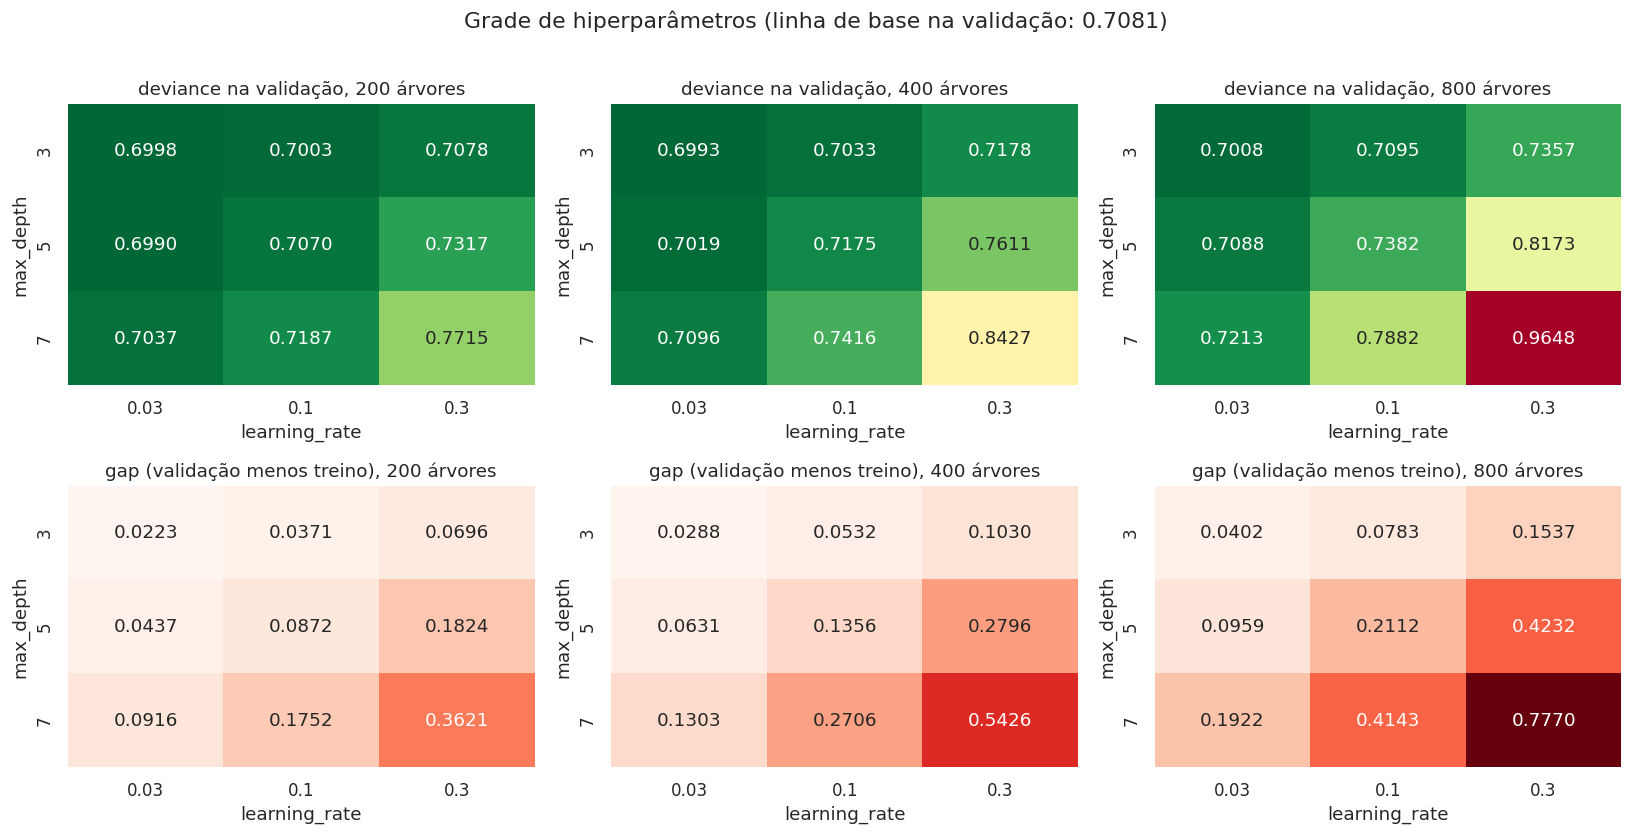

In [27]:
# Resultado da grade: ranking, estabilidade entre dobras e comparação com a melhor linha de base

referencia = RESULTADOS_LINHAS_DE_BASE.query("`linha de base` == 'média por hora e dia da semana' and "
                                             "conjunto == 'validação (média das 5 dobras)'").iloc[0]
dev_linha_de_base = referencia["deviance_poisson"]

colunas = ["max_depth", "learning_rate", "n_estimators", "mean_train_deviance", "mean_test_deviance",
           "std_test_deviance", "gap_deviance", "mean_test_MAE", "mean_test_RMSE"]
tabela = grade[colunas].copy()
tabela["ganho vs. linha de base"] = 1 - tabela["mean_test_deviance"] / dev_linha_de_base
print("=" * 70)
print("GRADE: AS 27 COMBINAÇÕES, DA MELHOR PARA A PIOR (deviance média na validação)")
print("=" * 70)
display(tabela.style.format({"learning_rate": "{:.2f}", "mean_train_deviance": "{:.4f}", "mean_test_deviance": "{:.4f}",
                             "std_test_deviance": "{:.4f}", "gap_deviance": "{:+.4f}", "mean_test_MAE": "{:.4f}",
                             "mean_test_RMSE": "{:.4f}", "ganho vs. linha de base": "{:+.2%}"}).hide(axis="index"))

n_melhores = int((tabela["mean_test_deviance"] < dev_linha_de_base).sum())
print(f"Deviance de validação da melhor linha de base (média por hora e dia da semana): {dev_linha_de_base:.4f}")
print(f"Combinações que superam essa linha de base: {n_melhores} de {len(tabela)}")

# Estabilidade: a melhor combinação ganha em todas as dobras?
melhor = grade.iloc[0]
dobras_melhor = [melhor[f"split{i}_test_deviance"] for i in range(len(DOBRAS_CV))]
dobras_base = []
for t, v in DOBRAS_CV:
    dobras_base.append(avaliar(y_treino.iloc[v], prever_media(treino.iloc[t], treino.iloc[v], ["hora", "dia_semana"]))["deviance_poisson"])
por_dobra = pd.DataFrame({"valida em": ANOS_TREINO[1:], "XGBoost (melhor)": dobras_melhor,
                          "linha de base": dobras_base})
por_dobra["ganho"] = 1 - por_dobra["XGBoost (melhor)"] / por_dobra["linha de base"]
print("\nMelhor combinação contra a linha de base, dobra a dobra (deviance de validação):")
display(por_dobra.style.format({"XGBoost (melhor)": "{:.4f}", "linha de base": "{:.4f}", "ganho": "{:+.2%}"}).hide(axis="index"))

# Mapas da grade: deviance de validação e gap, por profundidade e taxa de aprendizado, para cada nº de árvores
fig, eixos = plt.subplots(2, 3, figsize=(15, 7.5))
for j, n in enumerate(GRADE["n_estimators"]):
    sub = grade[grade["n_estimators"] == n]
    for i, (coluna, titulo, cmap) in enumerate([("mean_test_deviance", "deviance na validação", "RdYlGn_r"),
                                                ("gap_deviance", "gap (validação menos treino)", "Reds")]):
        mapa = sub.pivot(index="max_depth", columns="learning_rate", values=coluna)
        sns.heatmap(mapa, annot=True, fmt=".4f", cmap=cmap, ax=eixos[i, j], cbar=False,
                    vmin=grade[coluna].min(), vmax=grade[coluna].max())
        eixos[i, j].set_title(f"{titulo}, {n} árvores")
        eixos[i, j].set_xlabel("learning_rate")
        eixos[i, j].set_ylabel("max_depth")
fig.suptitle(f"Grade de hiperparâmetros (linha de base na validação: {dev_linha_de_base:.4f})", y=1.01)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item8_grade_hiperparametros.png", dpi=150, bbox_inches="tight")
plt.show()

### **Discussão do Item 8**

#### **Tempo (8.1 e 8.2).**

O cronômetro estimou 3,4 minutos, e a grade levou 4,1 minutos (135 treinos), um erro de cerca de 20%. A estimativa média os tempos do treino mais leve (0,57 s) e do mais pesado (4,25 s), e a maioria das combinações fica mais perto do lado pesado. Para a estimativa de um tempo de execução, foi suficiente.

#### **A melhor combinação (8.2 e 8.3)**

É `max_depth` = 5, `learning_rate` = 0,03 e 200 árvores, com deviance média de **0,6990** na validação, contra **0,7081** da melhor linha de base: um ganho de **1,29%**. Das 27 combinações, 10 superam a linha de base.

#### **O ganho aparece nas 5 dobras**

A melhor combinação vence a linha de base em todos os anos de validação: +3,32% em 2020, +1,40% em 2021, +0,30% em 2022, +0,79% em 2023 e +0,64% em 2024. Um ganho que só aparecesse na média poderia ser acaso. Um ganho em todas as dobras, mesmo pequeno, é consistente. O maior ganho é o da dobra 1, que treina só com 2019: com poucos dados, as 168 médias da linha de base são ruidosas, e o XGBoost generaliza melhor porque compartilha informação entre horas e dias parecidos em vez de calcular cada média isolada.

#### **As primeiras colocadas estão empatadas**

As cinco melhores ficam entre 0,6990 e 0,7008, uma diferença de 0,0018. Isso é bem menor que a variação entre dobras (desvio padrão de cerca de 0,012 a 0,015). Pela regra do protocolo, definida antes de rodar, fica a de menor média (5, 0,03 e 200 árvores). Vale registrar que a segunda e a terceira, com profundidade 3, ficaram a menos de 0,001 de distância e com gap ainda menor (0,0223 na terceira). Na prática, as três são equivalentes, e a escolha não muda as conclusões.

#### **O overfitting aparece de forma clara (mapas de 8.3)**

O gap entre validação e treino cresce com os três hiperparâmetros ao mesmo tempo: árvores mais fundas, taxa de aprendizado maior e mais árvores. Ele vai de 0,0223 (profundidade 3, taxa 0,03, 200 árvores) até 0,7770 (profundidade 7, taxa 0,3, 800 árvores). Nesse extremo, a deviance no treino cai para 0,1878, o modelo praticamente decorou as horas do treino, e a de validação sobe para 0,9648, **36% pior que a simples média por hora e dia da semana**. É o retrato do overfitting: mais capacidade sempre melhora o treino e, a partir de certo ponto, piora o que o modelo nunca viu. A região boa da grade fica onde a taxa é baixa (0,03) e a profundidade vai de 3 a 5.

#### **O lado do sub-ajuste não apareceu**

A combinação mais simples da grade (profundidade 3, taxa 0,03, 200 árvores) já supera a linha de base (+1,17%) e fica empatada com a melhor. Ou seja, o sinal que existe nos dados é simples, quase todo de calendário, e um modelo pequeno já o captura. Para ver o sub-ajuste de verdade, seria preciso ir abaixo da grade (por exemplo, 50 árvores). O ponto de equilíbrio está no canto simples da grade.

#### **De novo, a armadilha do MAE**

O MAE de validação **cai** conforme o modelo se sobreajusta: 0,3294 na melhor combinação e 0,2905 na pior pela deviance, que é o **menor MAE da grade inteira**. Um modelo sobreajustado faz previsões mais extremas, perto de zero na maioria das horas, e o MAE premia isso, porque o valor mais comum é zero (Item 7). O RMSE segue a deviance (0,4614 na melhor e 0,4946 na pior). Se a seleção fosse pelo MAE, o modelo escolhido seria justamente o pior. A escolha da deviance de Poisson no protocolo evitou esse erro.

#### **O que o ganho de 1,29% significa**

É um ganho pequeno, como a hipótese H4 antecipava: hora a hora, o acaso domina, e o calendário já explica a maior parte do que é previsível. O XGBoost acrescenta estimativas mais estáveis por horário e um pouco de mês, feriado e tempo. O Item 9 mede quanto desse ganho vem das variáveis do tempo, com a ablação.

#### **Conclusão do Item 8**

A combinação escolhida é **profundidade 5, taxa 0,03 e 200 árvores**, melhor que a linha de base em todas as dobras e com gap pequeno (0,0437). O próximo passo é retreiná-la com todo o treino e, pela primeira e única vez, avaliá-la no teste de 2025.

## **Item 9: Resultados em treino e teste, overfitting e efeito do tempo**

A combinação escolhida no Item 8 (profundidade 5, taxa 0,03 e 200 árvores) é retreinada com **todo o treino (2019 a 2024)** e avaliada, pela primeira e única vez, no **teste (2025)**. O item responde a sete perguntas:

| Parte | Pergunta |
|---|---|
| **9.1** | Quanto o modelo erra no treino, na validação e no teste, lado a lado com a linha de base? |
| **9.2** | Como o erro de treino e o de validação evoluem conforme as árvores são somadas (curva de aprendizado)? |
| **9.3** | Onde termina o sub-ajuste e começa o overfitting, variando a profundidade das árvores? |
| **9.4** | Quanto as variáveis do tempo acrescentam além do calendário (ablação)? |
| **9.5** | Quais variáveis o modelo mais usa? |
| **9.6** | O que o modelo aprendeu sobre a chuva, a temperatura e a umidade na mesma hora? |
| **9.7** | Onde o modelo erra no teste (por hora, por mês) e se as previsões estão calibradas |

### **Como ler o overfitting**

Um modelo sobreajustado tem erro baixo no treino e alto na validação e no teste. A diferença entre os dois é o **gap**. Um gap pequeno, com validação e teste próximos, indica que o modelo aprendeu o padrão, e não o acaso das horas de treino.

### **O teste é usado uma única vez, em 9.1**

As partes seguintes também usam 2025, mas só para **descrever** o modelo já escolhido (importância, cenários e diagnóstico), nunca para mudar alguma escolha.

### **9.1 Treino, validação e teste lado a lado**

A função `avaliar_modelo` faz, para um conjunto de variáveis e uma combinação de hiperparâmetros:

1. **validação:** treina nas 5 dobras do Item 6 e tira a média das métricas;
2. **treino e teste:** treina uma vez com todo o treino (2019 a 2024), mede o erro nesse mesmo treino e o erro no teste (2025).

Ela é aplicada a dois modelos: o **XGBoost escolhido**, com as 7 variáveis, e o **XGBoost só com calendário** (hora, dia da semana, mês e feriado), com os mesmos hiperparâmetros, que é a ablação de 9.4. A tabela traz também a melhor linha de base do Item 7. Para cada métrica, os três modelos aparecem nos três conjuntos, lado a lado, como pede o enunciado. O gráfico é salvo em `figuras/item9_metricas_treino_teste.png`.

RESULTADOS LADO A LADO (melhor combinação do Item 8: {'max_depth': 5, 'learning_rate': 0.03, 'n_estimators': 200})

deviance_poisson:


conjunto,treino,validação (média das 5 dobras),teste (2025)
modelo,,,
XGBoost com calendário e tempo (escolhido),0.6807,0.6990,0.7427
XGBoost só com calendário (ablação),0.6852,0.6977,0.7429
linha de base: média por hora e dia da semana,0.6880,0.7081,0.7485



D2:


conjunto,treino,validação (média das 5 dobras),teste (2025)
modelo,,,
XGBoost com calendário e tempo (escolhido),5.56%,3.23%,3.76%
XGBoost só com calendário (ablação),4.94%,3.41%,3.73%
linha de base: média por hora e dia da semana,4.54%,1.95%,3.00%



RMSE:


conjunto,treino,validação (média das 5 dobras),teste (2025)
modelo,,,
XGBoost com calendário e tempo (escolhido),0.4566,0.4614,0.4956
XGBoost só com calendário (ablação),0.4578,0.4612,0.4956
linha de base: média por hora e dia da semana,0.4585,0.4628,0.4967



MAE:


conjunto,treino,validação (média das 5 dobras),teste (2025)
modelo,,,
XGBoost com calendário e tempo (escolhido),0.3298,0.3294,0.3498
XGBoost só com calendário (ablação),0.3305,0.3294,0.3491
linha de base: média por hora e dia da semana,0.3300,0.3288,0.3487



vies_nivel:


conjunto,treino,validação (média das 5 dobras),teste (2025)
modelo,,,
XGBoost com calendário e tempo (escolhido),-0.0%,-3.0%,-9.8%
XGBoost só com calendário (ablação),+0.0%,-2.5%,-10.1%
linha de base: média por hora e dia da semana,+0.0%,-2.5%,-10.2%



Ganho do XGBoost escolhido sobre a linha de base em deviance: validação +1.29% | teste +0.78%


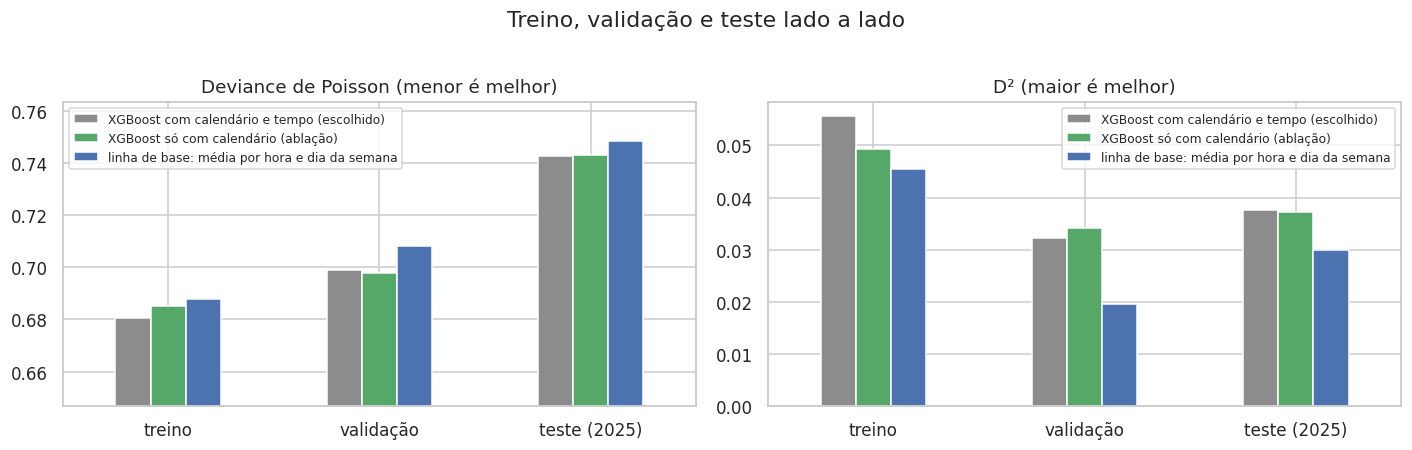

In [41]:
# Retreino da melhor combinação e métricas de treino, validação e teste lado a lado

def avaliar_modelo(variaveis: list, params: dict) -> tuple:
    """Treina nas 5 dobras (validação) e no treino inteiro (treino e teste) e devolve as métricas e o modelo."""
    m_dobras = []
    for t, v in DOBRAS_CV:
        m = novo_modelo(**params).fit(X_treino.iloc[t][variaveis], y_treino.iloc[t])
        m_dobras.append(avaliar(y_treino.iloc[v], m.predict(X_treino.iloc[v][variaveis])))
    modelo = novo_modelo(**params).fit(X_treino[variaveis], y_treino)
    metricas = {
        "treino": avaliar(y_treino, modelo.predict(X_treino[variaveis])),
        "validação (média das 5 dobras)": {k: np.mean([m[k] for m in m_dobras]) for k in m_dobras[0]},
        "teste (2025)": avaliar(y_teste, modelo.predict(X_teste[variaveis])),   # única vez que o teste é usado
    }
    return metricas, m_dobras, modelo


metricas_completo, dobras_completo, modelo_final = avaliar_modelo(VARIAVEIS, MELHORES_PARAMS)
metricas_calendario, dobras_calendario, modelo_calendario = avaliar_modelo(VARIAVEIS_CALENDARIO, MELHORES_PARAMS)

linhas = []
for nome, metricas in [("XGBoost com calendário e tempo (escolhido)", metricas_completo),
                       ("XGBoost só com calendário (ablação)", metricas_calendario)]:
    for conjunto, m in metricas.items():
        linhas.append({"modelo": nome, "conjunto": conjunto, **m})
base_ref = RESULTADOS_LINHAS_DE_BASE[RESULTADOS_LINHAS_DE_BASE["linha de base"] == "média por hora e dia da semana"]
for _, r in base_ref.iterrows():
    linhas.append({"modelo": "linha de base: média por hora e dia da semana", **r.drop("linha de base").to_dict()})
RESULTADOS_FINAIS = pd.DataFrame(linhas)

print("=" * 70)
print(f"RESULTADOS LADO A LADO (melhor combinação do Item 8: {MELHORES_PARAMS})")
print("=" * 70)
ordem = ["treino", "validação (média das 5 dobras)", "teste (2025)"]
for metrica in ["deviance_poisson", "D2", "RMSE", "MAE", "vies_nivel"]:
    pivo = RESULTADOS_FINAIS.pivot(index="modelo", columns="conjunto", values=metrica)[ordem]
    formato = "{:+.1%}" if metrica == "vies_nivel" else ("{:.2%}" if metrica == "D2" else "{:.4f}")
    print(f"\n{metrica}:")
    display(pivo.style.format(formato))

ganho_val = 1 - metricas_completo["validação (média das 5 dobras)"]["deviance_poisson"] / base_ref.iloc[1]["deviance_poisson"]
ganho_teste = 1 - metricas_completo["teste (2025)"]["deviance_poisson"] / base_ref.iloc[2]["deviance_poisson"]
print(f"\nGanho do XGBoost escolhido sobre a linha de base em deviance: validação {ganho_val:+.2%} | teste {ganho_teste:+.2%}")

# Gráfico: deviance e D² dos três modelos nos três conjuntos
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for ax, metrica, titulo in [(eixos[0], "deviance_poisson", "Deviance de Poisson (menor é melhor)"),
                            (eixos[1], "D2", "D² (maior é melhor)")]:
    pivo = RESULTADOS_FINAIS.pivot(index="conjunto", columns="modelo", values=metrica).loc[ordem]
    pivo.index = ["treino", "validação", "teste (2025)"]
    pivo.plot(kind="bar", ax=ax, rot=0, color=["#8C8C8C", "#55A868", "#4C72B0"])
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.legend(fontsize=8, loc="upper left" if metrica == "deviance_poisson" else "upper right")
    if metrica == "deviance_poisson":
        ax.set_ylim(pivo.min().min() * 0.95, pivo.max().max() * 1.02)
fig.suptitle("Treino, validação e teste lado a lado", y=1.02)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item9_metricas_treino_teste.png", dpi=150, bbox_inches="tight")
plt.show()

### **9.2 Curva de aprendizado: o erro conforme as árvores são somadas**

Na dobra 5 (treino de 2019 a 2023, validação em 2024), a célula treina 800 árvores e mede a deviance de treino e de validação a cada 20 árvores. Isso é feito para duas configurações:

- **a escolhida** (profundidade 5, taxa 0,03): mostra se 200 árvores é um bom ponto de parada;
- **a mais complexa da grade** (profundidade 7, taxa 0,3): mostra o overfitting acontecendo. O erro de treino continua caindo enquanto o de validação para de cair e começa a subir.

A linha pontilhada marca onde a validação atinge o menor erro. O gráfico é salvo em `figuras/item9_curva_aprendizado.png`.

CURVA DE APRENDIZADO (dobra 5: treino de 2019 a 2023, validação em 2024)
escolhida (profundidade 5, taxa 0.03): menor deviance de validação com 240 árvores (0.7191); com 800 árvores: treino 0.6466 | validação 0.7242
mais complexa da grade (profundidade 7, taxa 0,3): menor deviance de validação com 20 árvores (0.7236); com 800 árvores: treino 0.2902 | validação 0.8962


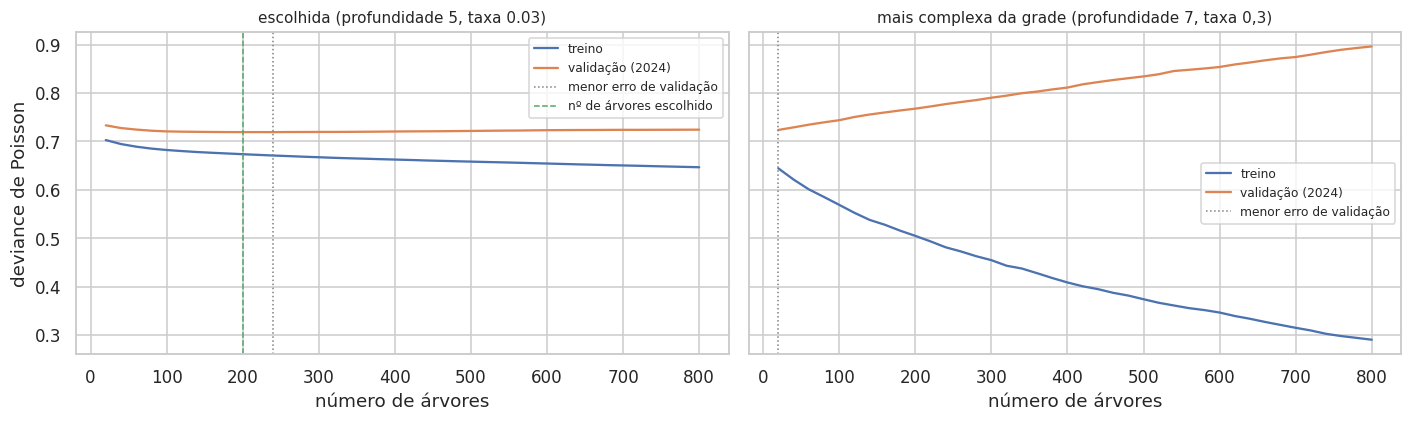

In [42]:
# Curva de aprendizado: deviance de treino e de validação conforme as árvores são somadas

t, v = DOBRAS_CV[-1]                                  # dobra 5: treina de 2019 a 2023 e valida em 2024
marcas = np.arange(20, 801, 20)                  # a cada 20 árvores
configuracoes = {
    f"escolhida (profundidade {MELHORES_PARAMS['max_depth']}, taxa {MELHORES_PARAMS['learning_rate']})":
        dict(max_depth=MELHORES_PARAMS["max_depth"], learning_rate=MELHORES_PARAMS["learning_rate"]),
    "mais complexa da grade (profundidade 7, taxa 0,3)": dict(max_depth=7, learning_rate=0.3),
}
curvas = {}
for nome, params in configuracoes.items():
    m = novo_modelo(n_estimators=800, **params).fit(X_treino.iloc[t], y_treino.iloc[t])
    curvas[nome] = pd.DataFrame({
        "árvores": marcas,
        "treino": [mean_poisson_deviance(y_treino.iloc[t], m.predict(X_treino.iloc[t], iteration_range=(0, k))) for k in marcas],
        "validação": [mean_poisson_deviance(y_treino.iloc[v], m.predict(X_treino.iloc[v], iteration_range=(0, k))) for k in marcas],
    })

print("=" * 70)
print("CURVA DE APRENDIZADO (dobra 5: treino de 2019 a 2023, validação em 2024)")
print("=" * 70)
for nome, c in curvas.items():
    melhor = c.loc[c["validação"].idxmin()]
    print(f"{nome}: menor deviance de validação com {int(melhor['árvores'])} árvores ({melhor['validação']:.4f}); "
          f"com 800 árvores: treino {c['treino'].iloc[-1]:.4f} | validação {c['validação'].iloc[-1]:.4f}")

fig, eixos = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (nome, c) in zip(eixos, curvas.items()):
    ax.plot(c["árvores"], c["treino"], color="#4C72B0", label="treino")
    ax.plot(c["árvores"], c["validação"], color="#DD8452", label="validação (2024)")
    ax.axvline(c.loc[c["validação"].idxmin(), "árvores"], color="gray", ls=":", lw=1, label="menor erro de validação")
    if nome.startswith("escolhida"):
        ax.axvline(MELHORES_PARAMS["n_estimators"], color="#55A868", ls="--", lw=1, label="nº de árvores escolhido")
    ax.set_title(nome, fontsize=10)
    ax.set_xlabel("número de árvores")
    ax.legend(fontsize=8)
eixos[0].set_ylabel("deviance de Poisson")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item9_curva_aprendizado.png", dpi=150, bbox_inches="tight")
plt.show()

### **9.3 Gap por profundidade: do sub-ajuste ao overfitting**

O Item 8 mostrou que o lado do sub-ajuste não apareceu na grade: até a combinação mais simples já superava a linha de base. Aqui, a taxa (0,03) e o número de árvores (200) ficam fixos, e a profundidade vai de **1 a 8**, nas mesmas 5 dobras. Com profundidade 1, cada árvore faz uma única pergunta e não combina variáveis, então o modelo não consegue representar, por exemplo, que a noite só é perigosa no fim de semana. Com profundidade 8, cada árvore combina até 8 condições e tende a decorar o treino.

A curva mostra o treino caindo sem parar conforme a profundidade aumenta e a validação descrevendo um "U": cai enquanto o modelo aprende padrões reais e sobe quando ele começa a decorar o acaso. A tabela traz o gap de cada profundidade, e o gráfico é salvo em `figuras/item9_gap_profundidade.png`.

CURVA DE VALIDAÇÃO POR PROFUNDIDADE (taxa 0.03, 200 árvores, 5 dobras, 65 s)


max_depth,treino,validação,gap
1,0.6951,0.7089,+0.0138
2,0.6850,0.7028,+0.0178
3,0.6775,0.6998,+0.0223
4,0.6683,0.6989,+0.0306
5,0.6553,0.6990,+0.0437
6,0.6373,0.7006,+0.0633
7,0.6121,0.7037,+0.0916
8,0.5826,0.7071,+0.1245


Menor deviance de validação com profundidade 4 | linha de base na validação: 0.7081


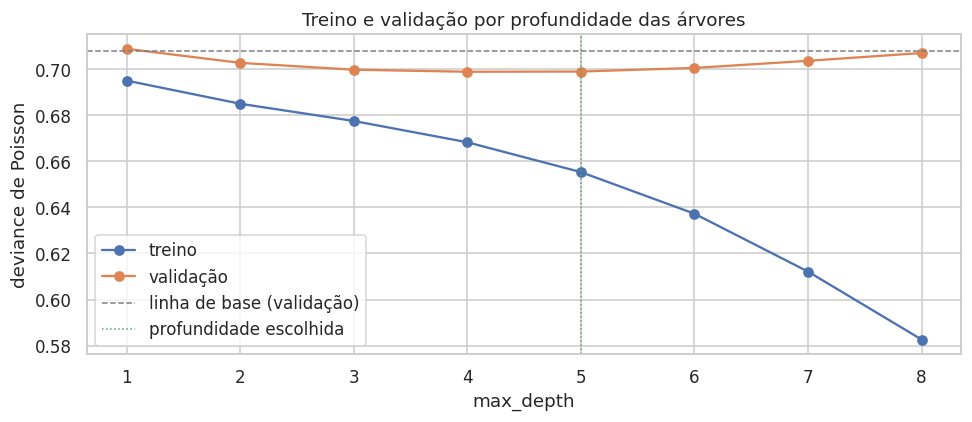

In [43]:
# Gap por profundidade: do sub-ajuste ao overfitting, com taxa e número de árvores fixos

profundidades = range(1, 9)
linhas = []
t0 = time.time()
for p in profundidades:
    params = {**MELHORES_PARAMS, "max_depth": p}
    treino_dev, val_dev = [], []
    for t, v in DOBRAS_CV:
        m = novo_modelo(**params).fit(X_treino.iloc[t], y_treino.iloc[t])
        treino_dev.append(mean_poisson_deviance(y_treino.iloc[t], m.predict(X_treino.iloc[t])))
        val_dev.append(mean_poisson_deviance(y_treino.iloc[v], m.predict(X_treino.iloc[v])))
    linhas.append({"max_depth": p, "treino": np.mean(treino_dev), "validação": np.mean(val_dev)})
curva_profundidade = pd.DataFrame(linhas)
curva_profundidade["gap"] = curva_profundidade["validação"] - curva_profundidade["treino"]

print("=" * 70)
print(f"CURVA DE VALIDAÇÃO POR PROFUNDIDADE (taxa {MELHORES_PARAMS['learning_rate']}, "
      f"{MELHORES_PARAMS['n_estimators']} árvores, 5 dobras, {time.time() - t0:.0f} s)")
print("=" * 70)
display(curva_profundidade.style.format({"treino": "{:.4f}", "validação": "{:.4f}", "gap": "{:+.4f}"}).hide(axis="index"))
melhor_p = int(curva_profundidade.loc[curva_profundidade["validação"].idxmin(), "max_depth"])
print(f"Menor deviance de validação com profundidade {melhor_p} | "
      f"linha de base na validação: {dev_linha_de_base:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curva_profundidade["max_depth"], curva_profundidade["treino"], marker="o", color="#4C72B0", label="treino")
ax.plot(curva_profundidade["max_depth"], curva_profundidade["validação"], marker="o", color="#DD8452", label="validação")
ax.axhline(dev_linha_de_base, color="gray", ls="--", lw=1, label="linha de base (validação)")
ax.axvline(MELHORES_PARAMS["max_depth"], color="#55A868", ls=":", lw=1, label="profundidade escolhida")
ax.set_xlabel("max_depth")
ax.set_ylabel("deviance de Poisson")
ax.set_title("Treino e validação por profundidade das árvores")
ax.legend()
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item9_gap_profundidade.png", dpi=150, bbox_inches="tight")
plt.show()

### **9.4 Ablação: quanto o tempo acrescenta além do calendário**

A pergunta de ML diz "dadas as condições do tempo". A ablação responde diretamente se o tempo importa: o mesmo XGBoost, com os mesmos hiperparâmetros, treinado **sem** chuva, temperatura e umidade. A tabela compara as duas versões em cada uma das 5 dobras e no teste.

- Se o tempo ajudar em todas as dobras, o efeito é consistente, mesmo que pequeno.
- Se ajudar só em algumas, o ganho médio pode ser acaso.

In [44]:
# Ablação: quanto as variáveis do tempo acrescentam além do calendário, dobra a dobra e no teste

ablacao = pd.DataFrame({
    "valida em": ANOS_TREINO[1:],
    "com tempo": [m["deviance_poisson"] for m in dobras_completo],
    "só calendário": [m["deviance_poisson"] for m in dobras_calendario],
})
ablacao.loc[len(ablacao)] = ["teste (2025)", metricas_completo["teste (2025)"]["deviance_poisson"],
                             metricas_calendario["teste (2025)"]["deviance_poisson"]]
ablacao["ganho do tempo"] = 1 - ablacao["com tempo"] / ablacao["só calendário"]

print("=" * 70)
print("ABLAÇÃO: XGBOOST COM E SEM AS VARIÁVEIS DO TEMPO (deviance de Poisson)")
print("=" * 70)
display(ablacao.style.format({"com tempo": "{:.4f}", "só calendário": "{:.4f}", "ganho do tempo": "{:+.2%}"}).hide(axis="index"))
dobras_que_ganham = int((ablacao["ganho do tempo"].iloc[:5] > 0).sum())
print(f"Dobras em que o tempo ajuda: {dobras_que_ganham} de 5 | "
      f"ganho médio na validação: {ablacao['ganho do tempo'].iloc[:5].mean():+.2%}")

ABLAÇÃO: XGBOOST COM E SEM AS VARIÁVEIS DO TEMPO (deviance de Poisson)


valida em,com tempo,só calendário,ganho do tempo
2020,0.6820,0.6783,-0.54%
2021,0.6892,0.6887,-0.07%
2022,0.7101,0.7083,-0.27%
2023,0.6946,0.6937,-0.12%
2024,0.7192,0.7198,+0.09%
teste (2025),0.7427,0.7429,+0.03%


Dobras em que o tempo ajuda: 1 de 5 | ganho médio na validação: -0.18%


### **9.5 Importância das variáveis**

Duas medidas, que respondem a perguntas diferentes:

| Medida | Pergunta | Como é calculada |
|---|---|---|
| **Ganho nas árvores** | Quanto cada variável foi usada para melhorar o ajuste durante o treino? | Soma da melhora da deviance em todos os cortes que usam a variável, em % do total |
| **Permutação no teste** | Quanto o modelo piora em 2025 se a variável virar ruído? | Embaralha a variável nas horas do teste, 10 vezes, e mede o aumento médio da deviance |

A permutação é a mais honesta das duas, porque é medida em dados que o modelo nunca viu. Uma variável com ganho alto e permutação perto de zero foi usada no treino para ajustar detalhes que não se repetem. Temperatura e umidade são correlacionadas (Item 5), e a importância delas pode aparecer dividida entre as duas. O gráfico é salvo em `figuras/item9_importancia_variaveis.png`.

IMPORTÂNCIA DAS VARIÁVEIS (modelo escolhido, treinado de 2019 a 2024)


,ganho nas árvores (%),permutação: aumento da deviance no teste,desvio entre repetições
hora,44.5,0.05471,0.00418
dia_semana,30.3,0.02169,0.00196
mes,5.1,0.00244,0.00057
temperatura_c,7.7,0.00198,0.00076
umidade_pct,7.9,0.00169,0.00070
feriado,1.7,0.00074,0.00022
chuva_mm,2.8,-0.00001,0.00026


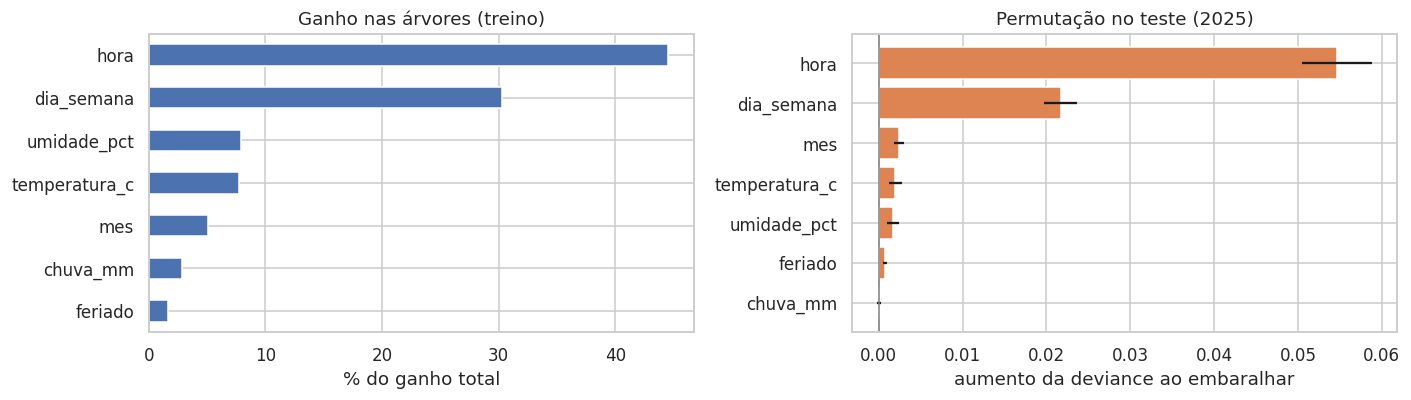

In [45]:
# Importância das variáveis: ganho nas árvores (treino) e permutação (teste)

from sklearn.inspection import permutation_importance

ganho = pd.Series(modelo_final.get_booster().get_score(importance_type="total_gain")).reindex(VARIAVEIS).fillna(0)
ganho = ganho / ganho.sum() * 100

# Permutação: embaralha uma variável por vez no teste e mede quanto a deviance piora
perm = permutation_importance(modelo_final, X_teste, y_teste, scoring="neg_mean_poisson_deviance",
                              n_repeats=10, random_state=SEED)
importancia = pd.DataFrame({
    "ganho nas árvores (%)": ganho,
    "permutação: aumento da deviance no teste": pd.Series(perm.importances_mean, index=VARIAVEIS),
    "desvio entre repetições": pd.Series(perm.importances_std, index=VARIAVEIS),
}).sort_values("permutação: aumento da deviance no teste", ascending=False)

print("=" * 70)
print("IMPORTÂNCIA DAS VARIÁVEIS (modelo escolhido, treinado de 2019 a 2024)")
print("=" * 70)
display(importancia.style.format({"ganho nas árvores (%)": "{:.1f}", "permutação: aumento da deviance no teste": "{:.5f}",
                                  "desvio entre repetições": "{:.5f}"}))

fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
importancia["ganho nas árvores (%)"].sort_values().plot(kind="barh", ax=eixos[0], color="#4C72B0")
eixos[0].set_title("Ganho nas árvores (treino)")
eixos[0].set_xlabel("% do ganho total")
p = importancia["permutação: aumento da deviance no teste"].sort_values()
eixos[1].barh(p.index, p.values, xerr=importancia.loc[p.index, "desvio entre repetições"], color="#DD8452")
eixos[1].axvline(0, color="gray", lw=1)
eixos[1].set_title("Permutação no teste (2025)")
eixos[1].set_xlabel("aumento da deviance ao embaralhar")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item9_importancia_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

### **9.6 O que o modelo aprendeu sobre o tempo**

É esta parte que decide o que a explicação ao entregador pode dizer sobre a chuva. Duas análises:

1. **Efeito médio (dependência parcial):** para cada valor de chuva (de 0 a 40 mm), a célula coloca esse valor em **todas** as horas do teste, mantém as demais variáveis como estavam e tira a média da previsão. O resultado sai como **multiplicador** em relação ao valor de referência (0 mm de chuva, 20 °C, 70% de umidade). Um multiplicador de 0,90 significa 10% menos sinistros graves esperados. O mesmo é feito para a temperatura e a umidade.
2. **Cenários na mesma hora:** uma quinta-feira de novembro com 24 °C e 85% de umidade, o tempo do exemplo do `POST /indice-turno` no Contrato, para várias horas do dia, mudando **só** a chuva. A segunda tabela divide cada valor pelo da mesma hora sem chuva.

**Cuidado de leitura:** como o modelo não sabe por que a chuva muda os sinistros, o multiplicador mede uma **associação**, e não o risco de cada viagem (o limite de exposição do Item 5). O gráfico é salvo em `figuras/item9_efeito_tempo_modelo.png`.

EFEITO MÉDIO NO TESTE: MULTIPLICADOR EM RELAÇÃO AO VALOR DE REFERÊNCIA
chuva_mm (referência = 0): 0.0: x1.00 | 0.5: x0.94 | 1.0: x0.95 | 2.0: x0.95 | 5.0: x1.00 | 10.0: x0.94 | 20.0: x1.15 | 40.0: x1.23
temperatura_c (referência = 20): 10: x0.92 | 15: x1.00 | 20: x1.00 | 25: x1.05 | 30: x1.09 | 35: x1.07
umidade_pct (referência = 70): 30: x1.10 | 50: x1.02 | 70: x1.00 | 85: x0.93 | 95: x0.98 | 100: x0.92

Sinistros graves esperados na hora (quinta-feira de novembro, 24 °C, 85% de umidade):


chuva_mm,0,1,2,5,7,10,20
hora,,,,,,,
3,0.072,0.079,0.076,0.077,0.072,0.072,0.074
7,0.260,0.251,0.241,0.265,0.248,0.248,0.250
12,0.200,0.208,0.200,0.220,0.205,0.205,0.212
17,0.245,0.258,0.248,0.294,0.265,0.265,0.366
18,0.269,0.283,0.272,0.304,0.279,0.279,0.379
20,0.245,0.258,0.248,0.277,0.255,0.255,0.353
22,0.208,0.223,0.215,0.240,0.220,0.220,0.305


Multiplicador em relação à mesma hora sem chuva:


chuva_mm,0,1,2,5,7,10,20
hora,,,,,,,
3,x1.00,x1.10,x1.05,x1.07,x1.01,x1.01,x1.04
7,x1.00,x0.96,x0.93,x1.02,x0.95,x0.95,x0.96
12,x1.00,x1.04,x1.00,x1.10,x1.02,x1.02,x1.06
17,x1.00,x1.05,x1.01,x1.20,x1.08,x1.08,x1.49
18,x1.00,x1.05,x1.01,x1.13,x1.04,x1.04,x1.41
20,x1.00,x1.05,x1.01,x1.13,x1.04,x1.04,x1.44
22,x1.00,x1.07,x1.03,x1.15,x1.06,x1.06,x1.46


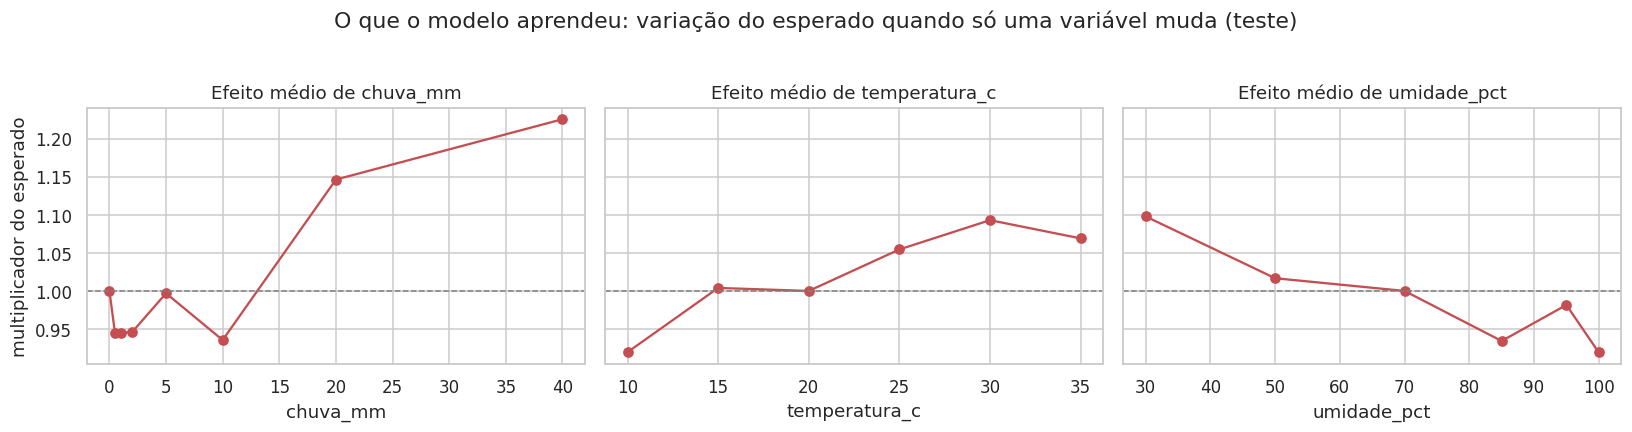

In [46]:
# O que o modelo aprendeu sobre o tempo: efeito médio e cenários de chuva na mesma hora

def efeito_medio(variavel: str, valores) -> pd.Series:
    """Dependência parcial: troca a variável em todas as horas do teste e tira a média da previsão."""
    return pd.Series([modelo_final.predict(X_teste.assign(**{variavel: valor})).mean() for valor in valores],
                     index=valores)


valores = {"chuva_mm": [0, 0.5, 1, 2, 5, 10, 20, 40], "temperatura_c": [10, 15, 20, 25, 30, 35],
           "umidade_pct": [30, 50, 70, 85, 95, 100]}
referencia_valor = {"chuva_mm": 0, "temperatura_c": 20, "umidade_pct": 70}
efeitos = {v: efeito_medio(v, vals) for v, vals in valores.items()}

print("=" * 70)
print("EFEITO MÉDIO NO TESTE: MULTIPLICADOR EM RELAÇÃO AO VALOR DE REFERÊNCIA")
print("=" * 70)
for v, s in efeitos.items():
    mult = s / s.loc[referencia_valor[v]]
    print(f"{v} (referência = {referencia_valor[v]}): " + " | ".join(f"{k}: x{m:.2f}" for k, m in mult.items()))

# Cenários: quinta-feira de novembro, 24 °C e 85% de umidade (o exemplo do Contrato), só a chuva muda
horas_cenario, chuvas_cenario = [3, 7, 12, 17, 18, 20, 22], [0, 1, 2, 5, 7, 10, 20]
cenarios = pd.DataFrame([{"hora": h, "chuva_mm": c, "dia_semana": 3, "mes": 11, "feriado": 0,
                          "temperatura_c": 24.0, "umidade_pct": 85.0} for h in horas_cenario for c in chuvas_cenario])
cenarios["previsto"] = modelo_final.predict(cenarios[VARIAVEIS])
tabela_cenarios = cenarios.pivot(index="hora", columns="chuva_mm", values="previsto")
print("\nSinistros graves esperados na hora (quinta-feira de novembro, 24 °C, 85% de umidade):")
display(tabela_cenarios.style.format("{:.3f}").background_gradient(cmap="Reds", axis=None))
print("Multiplicador em relação à mesma hora sem chuva:")
display((tabela_cenarios.div(tabela_cenarios[0], axis=0)).style.format("x{:.2f}"))

fig, eixos = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (v, s) in zip(eixos, efeitos.items()):
    ax.plot(s.index, s / s.loc[referencia_valor[v]], marker="o", color="#C44E52")
    ax.axhline(1, color="gray", ls="--", lw=1)
    ax.set_xlabel(v)
    ax.set_title(f"Efeito médio de {v}")
eixos[0].set_ylabel("multiplicador do esperado")
fig.suptitle("O que o modelo aprendeu: variação do esperado quando só uma variável muda (teste)", y=1.03)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item9_efeito_tempo_modelo.png", dpi=150, bbox_inches="tight")
plt.show()

### **9.7 Diagnóstico do teste: viés de nível e calibração**

O teste tem cerca de 11% mais sinistros graves que a média do treino (Itens 4 a 7). Esta parte mostra **onde** o modelo erra em 2025:

- **por hora do dia:** a média prevista contra a observada, para comparar com o padrão da linha de base no Item 7 (aumento concentrado de dia);
- **por mês:** os totais previsto e observado, para ver se o viés é constante ao longo do ano ou se concentra em alguns meses;
- **calibração:** as horas do teste são divididas em 10 faixas pela previsão, da menor para a maior. Se o modelo estiver bem calibrado, nas horas em que ele prevê mais, acontece mais, na mesma proporção, e os pontos ficam perto da diagonal. Um deslocamento paralelo à diagonal indica o viés de nível. Uma inclinação diferente indicaria que o modelo exagera ou subestima as diferenças entre horários.

O gráfico é salvo em `figuras/item9_diagnostico_teste.png`.

DIAGNÓSTICO DO TESTE (2025)
Soma prevista: 1,827 | observada: 2,025 | viés de nível: -9.8%
Meses com previsão abaixo do observado: 10 de 12 | viés de -23% a +26%
Horas com previsão abaixo do observado: 19 de 24

Calibração (horas do teste divididas em 10 faixas pela previsão):


,previsto,observado,horas
faixa_prevista,,,
0,0.074,0.064,872
1,0.137,0.146,871
2,0.178,0.187,870
3,0.195,0.215,871
4,0.207,0.218,871
5,0.221,0.263,873
6,0.235,0.276,871
7,0.249,0.321,868
8,0.273,0.287,871


Correlação entre previsto e observado nas 10 faixas: 0.972


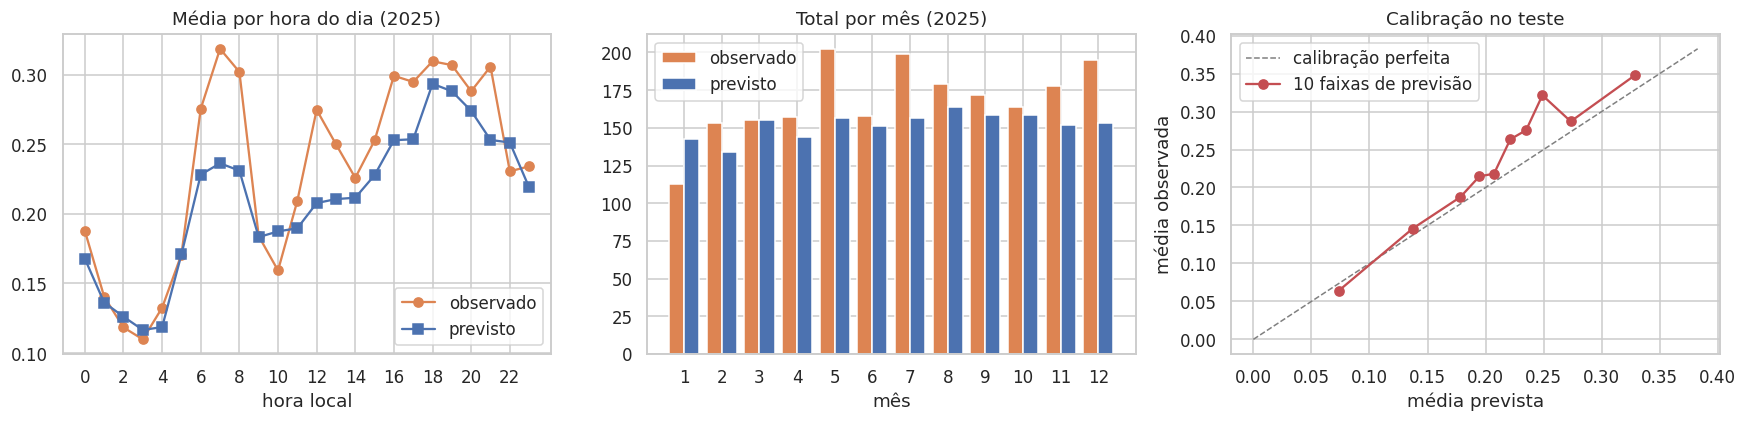

In [47]:
# Diagnóstico do teste: viés de nível por hora e por mês e calibração das previsões

diag = teste.assign(previsto=modelo_final.predict(X_teste))
por_hora_t = diag.groupby("hora").agg(observado=(COLUNA_ALVO, "mean"), previsto=("previsto", "mean"))
por_mes_t = diag.groupby("mes").agg(observado=(COLUNA_ALVO, "sum"), previsto=("previsto", "sum"))
diag["faixa_prevista"] = pd.qcut(diag["previsto"], 10, labels=False, duplicates="drop")
calibracao = diag.groupby("faixa_prevista").agg(previsto=("previsto", "mean"), observado=(COLUNA_ALVO, "mean"),
                                                horas=(COLUNA_ALVO, "size"))

print("=" * 70)
print("DIAGNÓSTICO DO TESTE (2025)")
print("=" * 70)
print(f"Soma prevista: {diag['previsto'].sum():,.0f} | observada: {diag[COLUNA_ALVO].sum():,} | "
      f"viés de nível: {diag['previsto'].sum() / diag[COLUNA_ALVO].sum() - 1:+.1%}")
razao_mes = por_mes_t["previsto"] / por_mes_t["observado"] - 1
print(f"Meses com previsão abaixo do observado: {(razao_mes < 0).sum()} de 12 | "
      f"viés de -{abs(razao_mes.min()):.0%} a {razao_mes.max():+.0%}")
razao_hora = por_hora_t["previsto"] / por_hora_t["observado"] - 1
print(f"Horas com previsão abaixo do observado: {(razao_hora < 0).sum()} de 24")
print("\nCalibração (horas do teste divididas em 10 faixas pela previsão):")
display(calibracao.style.format({"previsto": "{:.3f}", "observado": "{:.3f}", "horas": "{:,}"}))
correlacao_calibracao = np.corrcoef(calibracao["previsto"], calibracao["observado"])[0, 1]
print(f"Correlação entre previsto e observado nas 10 faixas: {correlacao_calibracao:.3f}")

fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
eixos[0].plot(por_hora_t.index, por_hora_t["observado"], marker="o", color="#DD8452", label="observado")
eixos[0].plot(por_hora_t.index, por_hora_t["previsto"], marker="s", color="#4C72B0", label="previsto")
eixos[0].set_xticks(range(0, 24, 2))
eixos[0].set_title("Média por hora do dia (2025)")
eixos[0].set_xlabel("hora local")
eixos[0].legend()
eixos[1].bar(por_mes_t.index - 0.2, por_mes_t["observado"], width=0.4, color="#DD8452", label="observado")
eixos[1].bar(por_mes_t.index + 0.2, por_mes_t["previsto"], width=0.4, color="#4C72B0", label="previsto")
eixos[1].set_xticks(range(1, 13))
eixos[1].set_title("Total por mês (2025)")
eixos[1].set_xlabel("mês")
eixos[1].legend()
limite = max(calibracao["previsto"].max(), calibracao["observado"].max()) * 1.1
eixos[2].plot([0, limite], [0, limite], color="gray", ls="--", lw=1, label="calibração perfeita")
eixos[2].plot(calibracao["previsto"], calibracao["observado"], marker="o", color="#C44E52", label="10 faixas de previsão")
eixos[2].set_title("Calibração no teste")
eixos[2].set_xlabel("média prevista")
eixos[2].set_ylabel("média observada")
eixos[2].legend()
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item9_diagnostico_teste.png", dpi=150, bbox_inches="tight")
plt.show()

### **Discussão do Item 9**

#### **O modelo supera a linha de base também no teste (9.1)**

Retreinado em 2019 a 2024, o XGBoost escolhido teve deviance de 0,6807 no treino, 0,6990 na validação e **0,7427 no teste**, contra 0,7485 da melhor linha de base, um ganho de **0,78%** em 2025 (1,29% na validação). O D² de teste foi de 3,76%, contra 3,00% da linha de base. O RMSE também melhora (0,4956 contra 0,4967), e o MAE fica praticamente igual (0,3498 contra 0,3487), pela armadilha já explicada nos Itens 7 e 8. O ganho é pequeno e caiu da validação para o teste, mas se manteve num ano que o modelo nunca viu.

#### **Não há overfitting no modelo escolhido**

O gap entre treino e validação é de 0,0183 e, entre treino e teste, de 0,0620. Quase toda a distância até o teste vem do viés de nível de 2025 (-9,8%), que afeta todos os modelos e a linha de base na mesma medida (de -9,8% a -10,2%). Não é uma particularidade do XGBoost.

#### **A curva de aprendizado (9.2)**

Na configuração escolhida, a validação atinge o menor erro com 240 árvores (0,7191) e fica praticamente plana depois disso. Com 800 árvores, o treino continua caindo (0,6466), enquanto a validação sobe só um pouco (0,7242). As 200 árvores escolhidas pela grade ficam perto do ponto ideal. Na configuração mais complexa da grade (profundidade 7, taxa 0,3), o retrato é o do overfitting clássico: o menor erro de validação acontece com só 20 árvores (0,7236). A partir daí, o treino despenca até 0,2902, e a validação sobe sem parar até 0,8962. Cada árvore a mais decora um pouco mais o acaso das horas de treino.

#### **O "U" da profundidade, agora com os dois lados (9.3)**

Com taxa de 0,03 e 200 árvores fixas, a validação cai de 0,7089 (profundidade 1) até o mínimo de 0,6989 (profundidade 4) e volta a subir até 0,7071 (profundidade 8), enquanto o treino cai sem parar (de 0,6951 a 0,5826) e o gap cresce de 0,0138 para 0,1245. Com profundidade 1, o modelo fica **pior que a linha de base** (0,7089 contra 0,7081). Isso é o sub-ajuste que não apareceu na grade do Item 8: árvores de uma só pergunta não combinam hora com dia da semana e perdem o padrão das noites de fim de semana. As profundidades 4 e 5 ficam empatadas (0,6989 e 0,6990), e a escolhida está no fundo do "U".

#### **As variáveis do tempo não acrescentam nada (9.4)**

É o resultado mais importante do item. O mesmo XGBoost, só com o calendário, tem deviance de validação de **0,6977**, ligeiramente **melhor** que a versão com o tempo (0,6990), e praticamente igual no teste (0,7429 contra 0,7427). Dobra a dobra, o tempo só ajuda em 2024 (+0,09%) e piora as outras quatro (de -0,07% a -0,54%), com média de -0,18%. No teste, o ganho é de 0,03%. A hipótese H4 se confirma com folga: **hora a hora, chuva, temperatura e umidade não mudam de forma mensurável quantos sinistros graves acontecem na cidade**, depois de considerar o horário, o dia da semana, o mês e os feriados.

#### **A importância das variáveis conta a mesma história (9.5)**

Hora (44,5% do ganho nas árvores) e dia da semana (30,3%) dominam. Na permutação no teste, embaralhar a hora piora a deviance em 0,0547, e o dia da semana, em 0,0217. Mês, temperatura e umidade ficam perto de 0,002, e o feriado, em 0,0007. **A chuva tem importância zero no teste** (-0,00001, com desvio de 0,00026). As variáveis do tempo somam 18,4% do ganho no treino, mas quase nada no teste: o modelo as usou para ajustar detalhes de 2019 a 2024 que não se repetem em 2025. É o mesmo diagnóstico da ablação, por outro caminho.

#### **O que o modelo aprendeu sobre a chuva não é confiável (9.6)**

Em média, chuva fraca (de 0,5 a 2 mm) aparece com multiplicador de 0,94 a 0,95, na mesma direção do Item 5, mas mais fraca. Chuva de 20 mm aparece com 1,15 e de 40 mm, com 1,23. Nos cenários de uma quinta-feira de novembro, 20 mm à noite chegam a multiplicar o esperado por 1,41 a 1,49. Esses números não devem ser lidos como efeito real, por três motivos:

1. **são poucas horas:** chuvas de 20 mm ou mais estão no último 1% das horas com chuva (Item 3), cerca de 40 a 50 horas em 7 anos, com uma dezena de sinistros graves no total;
2. **o padrão é irregular:** 5 mm multiplica por 1,13 a 1,20 à noite, mas 7 e 10 mm voltam para 1,04 a 1,08. Um efeito físico real não sobe, desce e sobe de novo assim. É o desenho típico de árvores ajustando poucos casos;
3. **a ablação e a permutação mostram que a chuva não melhora as previsões** em nenhum ano fora do treino.

A temperatura e a umidade mostram efeitos mais suaves e coerentes com o Item 5, com dias quentes um pouco acima (1,05 a 1,09 entre 25 e 35 °C) e umidade alta um pouco abaixo (0,92 a 0,93 acima de 85%). Mesmo assim, eles não se traduzem em ganho de previsão. Os cenários confirmam o que realmente pesa: sem chuva, o esperado vai de 0,072 sinistro grave às 3h a 0,269 às 18h, **3,7 vezes mais**, uma diferença bem maior que qualquer efeito do tempo.

#### **Onde o modelo erra em 2025 (9.7)**

A soma prevista foi de 1.827 sinistros graves, contra 2.025 observados (-9,8%). Em 10 dos 12 meses, a previsão ficou abaixo, com os maiores desvios em maio, julho e dezembro (cerca de 22% abaixo). Janeiro foi a exceção, com 26% acima (112 observados contra 142 previstos). Por hora, 19 das 24 ficaram abaixo, de novo concentradas de dia (6h a 8h e 11h a 16h), o mesmo padrão da linha de base no Item 7. Esse viés não vem de mudança na forma de registro entre graves e fatais, porque o alvo soma os dois (Item 2). Ele acompanha o aumento diurno de 2025, que nenhuma variável do modelo descreve.

#### **A calibração mostra que o modelo ordena bem as horas (9.7)**

Nas 10 faixas de previsão, a média observada sobe junto com a prevista (correlação de 0,972). Nas faixas de risco baixo, os pontos ficam sobre a diagonal (0,074 previsto contra 0,064 observado). Nas de risco médio e alto, ficam acima, por exemplo 0,249 previsto contra 0,321 observado. Ou seja, o modelo acerta **quais** horas são mais perigosas e erra o **nível** de 2025, sobretudo nas horas mais movimentadas. Para o Índice de Risco, que divide a previsão por um percentil histórico, ordenar bem as horas é o que mais importa. O retreino com 2025 incluído (Item 10) aproxima parcialmente o nível mais recente.

#### **Veredito das hipóteses com o modelo**

| Hipótese | Resultado final |
|---|---|
| H1 (horário) | **Confirmada.** Hora e dia da semana respondem pela maior parte da importância, e o esperado varia 3,7 vezes entre a madrugada e o fim da tarde |
| H2 (chuva aumenta os sinistros graves) | **Não confirmada.** A chuva não melhora as previsões fora do treino, e os efeitos de chuva forte aprendidos se apoiam em poucas horas e não são confiáveis |
| H3 (temperatura e umidade com efeito menor) | **Confirmada no sentido mais forte:** efeitos pequenos e coerentes, mas sem ganho de previsão |
| H4 (o tempo acrescenta pouco hora a hora) | **Confirmada.** Ablação com -0,18% na validação e +0,03% no teste |

#### **Conclusão do Item 9**

O XGBoost supera a média histórica por hora e dia da semana em todas as dobras e também no teste, sem overfitting na configuração escolhida. O ganho é pequeno, porque o acaso domina cada hora, e vem do calendário. As variáveis do tempo, como medidas pelo INMET hora a hora, não ajudam a prever quantos sinistros graves acontecem na cidade.

## **Item 10. Modelo final e exportação para o Serviço de Risco**

Este item transforma o resultado do estudo nos 4 arquivos que o Serviço de Risco carrega para calcular o componente `sinistro` do Índice de Risco do Turno (Contrato de Integração, seção 8.1), todos na pasta `ml/modelo/`:

| Arquivo | Conteúdo |
|---|---|
| `modelo_sinistros_xgb.json` | Modelo final, no formato nativo do XGBoost |
| `metadados_modelo.json` | Ordem e codificação das variáveis, conversão da requisição, feriados, período de treino, métricas e versões das bibliotecas |
| `p95_sinistros_graves.json` | Percentil 95 usado para levar a previsão à escala de 0 a 100 |
| `trechos_criticos.json` | Os trechos da cidade com mais sinistros graves com moto |

**Modelo exportado: só com o calendário (hora, dia da semana, mês e feriado).** Esta foi a decisão tomada com os números do Item 9, pelos motivos abaixo.

1. **Mesmo desempenho.** Na validação, o modelo só com calendário teve deviance de 0,6977 contra 0,6990 do modelo com o tempo, uma diferença de 0,2%. No teste de 2025, 0,7429 contra 0,7427, praticamente zero.
2. **O modelo com o tempo levaria ao Índice um efeito de chuva forte que não é confiável.** Chuva de 20 mm ou mais na hora quase não acontece (cerca de 40 horas em 7 anos), o efeito estimado é irregular e não melhorou nada fora do treino: a ablação mostrou ganho médio de menos 0,18% e a importância por permutação da chuva foi zero. Esse efeito iria direto para o que o entregador vê no app.
3. **Parcimônia como critério de robustez.** Entre dois modelos com o mesmo desempenho fora do treino, fica o que depende de menos entradas. Cada variável a mais é uma fonte de erro sem ganho comprovado, ainda mais quando o valor dela vem de uma previsão do tempo, que também erra.
4. **É a resposta à pergunta de ML.** Hora a hora, o tempo medido pelo INMET não muda de forma mensurável a quantidade de sinistros graves com moto, enquanto o horário pesa muito: numa quinta-feira de novembro, o modelo espera cerca de 3,7 vezes mais sinistros graves às 18h do que às 3h. A chuva e o calor continuam no Índice pelos componentes `chuva` e `calor`, como exposição direta do entregador ao tempo.

Essa decisão muda as variáveis de entrada previstas nas seções 8 e 8.1 do Contrato. A mudança foi aprovada e entra na versão 1.9, junto com o P95 escolhido neste item.

**Roteiro:** 10.1 grade de hiperparâmetros do modelo só com calendário · 10.2 retreino final e exportação do modelo · 10.3 percentil 95 (único e por hora) · 10.4 trechos críticos · 10.5 metadados · 10.6 previsão hora a hora de um turno, lendo só os arquivos exportados.

### **10.1 Grade de hiperparâmetros do modelo só com calendário**

Os hiperparâmetros do Item 8 foram escolhidos para o modelo com 7 variáveis. Com 4 variáveis, a combinação ideal pode ser outra: menos variáveis costumam pedir árvores mais rasas. Por isso, a mesma grade roda de novo, nas mesmas condições: as mesmas 27 combinações de `max_depth`, `learning_rate` e `n_estimators`, as mesmas 5 dobras anuais expansivas, só dentro do treino (2019 a 2024) e com o mesmo critério, a menor deviance de Poisson média na validação. O teste de 2025 continua de fora.

A tabela mostra as duas grades lado a lado, combinação por combinação. A célula registra se a melhor combinação mudou. Se mudou, o retreino de 2019 a 2025 (10.2) usa a nova. O resultado fica salvo em `grade_resultados_calendario.csv`, e a grade só roda de novo com `FORCAR_GRADE_CALENDARIO = True`.

Tempo estimado: de 2 a 3 minutos (a grade de 7 variáveis levou 4,1 minutos).

GRADE DO MODELO SÓ COM CALENDÁRIO (hora, dia da semana, mês e feriado)
Cache encontrado: grade_resultados_calendario.csv (27 combinações). Grade não foi rodada de novo.

Deviance média na validação e gap, combinação por combinação (ordem: modelo só com calendário):


max_depth,learning_rate,n_estimators,mean_test_deviance (7 variáveis),gap_deviance (7 variáveis),mean_test_deviance (calendário),gap_deviance (calendário),posição (7 variáveis),posição (calendário)
5,0.03,200,0.6990,0.0437,0.6977,0.0317,1,1
3,0.03,400,0.6993,0.0288,0.6987,0.0242,2,2
3,0.10,200,0.7003,0.0371,0.6990,0.0282,4,3
3,0.03,800,0.7008,0.0402,0.6992,0.0297,5,4
3,0.03,200,0.6998,0.0223,0.6992,0.0199,3,5
3,0.10,400,0.7033,0.0532,0.7004,0.0352,7,6
5,0.03,400,0.7019,0.0631,0.7010,0.0454,6,7
3,0.30,200,0.7078,0.0696,0.7020,0.0409,10,8
3,0.10,800,0.7095,0.0783,0.7032,0.0443,12,9
5,0.10,200,0.7070,0.0872,0.7050,0.0588,9,10


Melhor combinação com 7 variáveis: {'max_depth': 5, 'learning_rate': 0.03, 'n_estimators': 200} (validação 0.6990)
Melhor combinação só com calendário: {'max_depth': 5, 'learning_rate': 0.03, 'n_estimators': 200} (validação 0.6977)
A melhor combinação mudou? NÃO: a mesma combinação vale para os dois
Combinações em que o calendário fica melhor que as 7 variáveis: 21 de 27

Deviance de Poisson do modelo exportado, lado a lado:


,modelo exportado (calendário),XGBoost com 7 variáveis,linha de base
treino,0.6852,0.6807,0.6880
validação (média das 5 dobras),0.6977,0.6990,0.7081
teste (2025),0.7429,0.7427,0.7485


Ganho sobre a linha de base: validação +1.46% | teste +0.75%


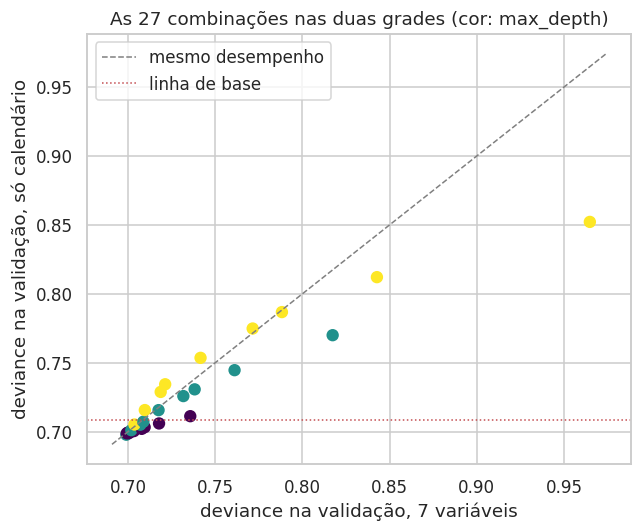

In [48]:
# Grade do modelo só com calendário: mesmas 27 combinações e mesmas 5 dobras, só no treino

FORCAR_GRADE_CALENDARIO = False
CACHE_GRADE_CALENDARIO = DIR_PROCESSADOS / "grade_resultados_calendario.csv"


def rodar_grade(variaveis: list, cache: Path, forcar: bool) -> pd.DataFrame:
    """GridSearchCV do Item 8 para um conjunto de variáveis, com cache em disco e sinais já corrigidos."""
    if cache.exists() and not forcar:
        g = pd.read_csv(cache)
        print(f"Cache encontrado: {cache.name} ({len(g)} combinações). Grade não foi rodada de novo.")
    else:
        busca = GridSearchCV(estimator=novo_modelo(), param_grid=GRADE, cv=DOBRAS_CV,
                             scoring={"deviance": "neg_mean_poisson_deviance", "MAE": "neg_mean_absolute_error",
                                      "RMSE": "neg_root_mean_squared_error"},
                             refit=False, return_train_score=True, n_jobs=1, verbose=1)
        t0 = time.time()
        busca.fit(X_treino[variaveis], y_treino)
        g = pd.DataFrame(busca.cv_results_)
        for coluna in [c for c in g.columns if c.startswith(("mean_", "split")) and "_time" not in c]:
            g[coluna] = -g[coluna]
        g.to_csv(cache, index=False)
        print(f"Grade concluída em {(time.time() - t0) / 60:.1f} min. Resultados salvos em {cache.name}")
    g = g.rename(columns={"param_max_depth": "max_depth", "param_learning_rate": "learning_rate",
                          "param_n_estimators": "n_estimators"})
    g["gap_deviance"] = g["mean_test_deviance"] - g["mean_train_deviance"]
    return g.sort_values("mean_test_deviance").reset_index(drop=True)


print("=" * 70)
print("GRADE DO MODELO SÓ COM CALENDÁRIO (hora, dia da semana, mês e feriado)")
print("=" * 70)
grade_calendario = rodar_grade(VARIAVEIS_CALENDARIO, CACHE_GRADE_CALENDARIO, FORCAR_GRADE_CALENDARIO)
MELHORES_PARAMS_CALENDARIO = {k: (int(grade_calendario.loc[0, k]) if k != "learning_rate"
                                  else float(grade_calendario.loc[0, k]))
                              for k in ["max_depth", "learning_rate", "n_estimators"]}

# As duas grades lado a lado, combinação por combinação
chaves = ["max_depth", "learning_rate", "n_estimators"]
lado_a_lado = grade[chaves + ["mean_test_deviance", "gap_deviance"]].merge(
    grade_calendario[chaves + ["mean_test_deviance", "gap_deviance"]], on=chaves, suffixes=(" (7 variáveis)", " (calendário)"))
lado_a_lado["posição (7 variáveis)"] = lado_a_lado["mean_test_deviance (7 variáveis)"].rank().astype(int)
lado_a_lado["posição (calendário)"] = lado_a_lado["mean_test_deviance (calendário)"].rank().astype(int)
lado_a_lado = lado_a_lado.sort_values("mean_test_deviance (calendário)").reset_index(drop=True)
print("\nDeviance média na validação e gap, combinação por combinação (ordem: modelo só com calendário):")
display(lado_a_lado.style.format({c: "{:.4f}" for c in lado_a_lado.columns if "deviance" in c}
                                 | {"learning_rate": "{:.2f}"}).hide(axis="index"))

mudou = MELHORES_PARAMS_CALENDARIO != MELHORES_PARAMS
print(f"Melhor combinação com 7 variáveis: {MELHORES_PARAMS} (validação {grade.loc[0, 'mean_test_deviance']:.4f})")
print(f"Melhor combinação só com calendário: {MELHORES_PARAMS_CALENDARIO} "
      f"(validação {grade_calendario.loc[0, 'mean_test_deviance']:.4f})")
print(f"A melhor combinação mudou? {'SIM: o retreino usa a nova' if mudou else 'NÃO: a mesma combinação vale para os dois'}")
print(f"Combinações em que o calendário fica melhor que as 7 variáveis: "
      f"{int((lado_a_lado['mean_test_deviance (calendário)'] < lado_a_lado['mean_test_deviance (7 variáveis)']).sum())} de 27")

# Avaliação final do modelo que será exportado (hiperparâmetros escolhidos para ele)
metricas_exportado, dobras_exportado, _ = avaliar_modelo(VARIAVEIS_CALENDARIO, MELHORES_PARAMS_CALENDARIO)
resumo_final = pd.DataFrame({
    "modelo exportado (calendário)": {c: metricas_exportado[c]["deviance_poisson"] for c in ordem},
    "XGBoost com 7 variáveis": {c: metricas_completo[c]["deviance_poisson"] for c in ordem},
    "linha de base": {c: base_ref.iloc[i]["deviance_poisson"] for i, c in enumerate(ordem)},
})
print("\nDeviance de Poisson do modelo exportado, lado a lado:")
display(resumo_final.style.format("{:.4f}"))
print(f"Ganho sobre a linha de base: validação "
      f"{1 - resumo_final.iloc[1, 0] / resumo_final.iloc[1, 2]:+.2%} | teste {1 - resumo_final.iloc[2, 0] / resumo_final.iloc[2, 2]:+.2%}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(lado_a_lado["mean_test_deviance (7 variáveis)"], lado_a_lado["mean_test_deviance (calendário)"],
           c=lado_a_lado["max_depth"], cmap="viridis", s=50)
lim = [lado_a_lado.filter(like="mean_test").min().min() * 0.99, lado_a_lado.filter(like="mean_test").max().max() * 1.01]
ax.plot(lim, lim, color="gray", ls="--", lw=1, label="mesmo desempenho")
ax.axhline(dev_linha_de_base, color="#C44E52", ls=":", lw=1, label="linha de base")
ax.set_xlabel("deviance na validação, 7 variáveis")
ax.set_ylabel("deviance na validação, só calendário")
ax.set_title("As 27 combinações nas duas grades (cor: max_depth)")
ax.legend()
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item10_grades_7_variaveis_calendario.png", dpi=150, bbox_inches="tight")
plt.show()

### **10.2 Retreino final de 2019 a 2025 e exportação do modelo**

Com os hiperparâmetros escolhidos na validação e o teste de 2025 já usado uma única vez (Item 9 e 10.1), o modelo final é treinado de novo com os 7 anos inteiros. Assim, o que vai para produção aprende também com o ano mais recente.

Uma diferença em relação ao treino da avaliação: como o modelo de calendário não usa o tempo, as poucas horas que ficaram de fora por falta de dados do INMET (`tempo_completo` falso) entram no retreino final. Os sinistros dessas horas são reais e não há motivo para descartá-los.

O modelo é salvo no formato nativo do XGBoost (`save_model` em JSON), mais estável entre versões do que um pickle. Para ter certeza de que o arquivo está certo, ele é lido de novo do disco com `xgboost.Booster`, como o Serviço de Risco fará. A célula confere que as previsões são idênticas às do modelo em memória e que a ordem das variáveis gravada no arquivo é a do metadados.

A tabela final mostra uma limitação conhecida: sem o ano entre as variáveis, o modelo prevê o nível médio de 2019 a 2025 para cada horário. Por isso fica abaixo do observado nos anos mais altos, como 2025, e acima nos mais baixos.

In [49]:
# Retreino final de 2019 a 2025 e exportação do modelo no formato nativo do XGBoost

VARIAVEIS_MODELO = VARIAVEIS_CALENDARIO            # decisão do Item 9 (opção B)
ARQ_MODELO = DIR_MODELO / "modelo_sinistros_xgb.json"

# O modelo de calendário não usa o tempo: as horas sem dados do INMET também entram no retreino final
dados_exportacao = base.sort_values("datahora_local").reset_index(drop=True)
modelo_exportado = novo_modelo(**MELHORES_PARAMS_CALENDARIO).fit(dados_exportacao[VARIAVEIS_MODELO],
                                                                  dados_exportacao[COLUNA_ALVO])
modelo_exportado.save_model(ARQ_MODELO)

# Conferência: o arquivo, lido como o Serviço de Risco fará, devolve exatamente as mesmas previsões
booster = xgb.Booster()
booster.load_model(ARQ_MODELO)
prev_arquivo = booster.predict(xgb.DMatrix(dados_exportacao[VARIAVEIS_MODELO]))
prev_memoria = modelo_exportado.predict(dados_exportacao[VARIAVEIS_MODELO])
assert np.allclose(prev_arquivo, prev_memoria), "o modelo salvo precisa prever igual ao modelo em memória"
assert booster.feature_names == VARIAVEIS_MODELO, "a ordem das variáveis precisa ser a do metadados"

print("=" * 70)
print("MODELO EXPORTADO")
print("=" * 70)
print(f"Arquivo: {ARQ_MODELO.name} ({ARQ_MODELO.stat().st_size / 1024:,.0f} KB)")
print(f"Variáveis, nesta ordem: {booster.feature_names}")
print(f"Hiperparâmetros: {MELHORES_PARAMS_CALENDARIO} | objetivo: count:poisson")
print(f"Treinado com {len(dados_exportacao):,} horas ({dados_exportacao['datahora_local'].min():%d/%m/%Y} a "
      f"{dados_exportacao['datahora_local'].max():%d/%m/%Y}) e {int(dados_exportacao[COLUNA_ALVO].sum()):,} sinistros graves")
print("Previsões do arquivo iguais às do modelo em memória: sim")

# Nível do modelo: sem o ano, ele prevê a média de 2019 a 2025 para cada horário
nivel = dados_exportacao.assign(previsto=prev_memoria).groupby("ano").agg(
    observado=(COLUNA_ALVO, "mean"), previsto=("previsto", "mean"))
nivel["previsto / observado"] = nivel["previsto"] / nivel["observado"] - 1
print("\nMédia por hora, observada e prevista, em cada ano do retreino:")
display(nivel.style.format({"observado": "{:.3f}", "previsto": "{:.3f}", "previsto / observado": "{:+.1%}"}))

MODELO EXPORTADO
Arquivo: modelo_sinistros_xgb.json (763 KB)
Variáveis, nesta ordem: ['hora', 'dia_semana', 'mes', 'feriado']
Hiperparâmetros: {'max_depth': 5, 'learning_rate': 0.03, 'n_estimators': 200} | objetivo: count:poisson
Treinado com 61,368 horas (01/01/2019 a 31/12/2025) e 13,028 sinistros graves
Previsões do arquivo iguais às do modelo em memória: sim

Média por hora, observada e prevista, em cada ano do retreino:


,observado,previsto,previsto / observado
ano,,,
2019,0.204,0.212,+4.1%
2020,0.200,0.212,+6.2%
2021,0.206,0.212,+3.1%
2022,0.214,0.213,-0.6%
2023,0.208,0.212,+2.3%
2024,0.222,0.212,-4.2%
2025,0.233,0.212,-9.1%


### **10.3 Percentil 95 para o componente sinistro**

O Contrato (seção 8) leva a previsão do modelo para a escala de 0 a 100 dividindo-a pelo percentil 95 histórico, com limite em 100 e arredondamento com 0,5 para cima. Para o modelo de calendário, o P95 sai da distribuição das previsões nas 61.368 horas de 2019 a 2025. A célula calcula as duas opções pendentes no Contrato e uma terceira só para comparação:

| Regra | Como é calculada | O que acontece com o índice |
|---|---|---|
| **P95 único** | um percentil sobre todas as horas | uma hora com o dobro de sinistros esperados ganha o dobro de pontos: a diferença entre 18h e 4h fica visível |
| **P95 por hora** | um percentil para cada hora do dia | cada hora é comparada só com ela mesma: o índice passa a medir quanto a hora está acima do normal *dela*, e não o risco em si. Uma hora calma pode ganhar tantos pontos quanto o pico da noite |
| P95 dos valores observados | percentil das contagens reais (0, 1, 2...) | contagens inteiras dão um P95 grosseiro, fora da escala das previsões (só para comparação) |

Para ver o efeito prático, a célula aplica as três regras a um dia típico (quinta-feira de novembro, sem feriado) e mostra quantos pontos separam a hora mais arriscada da menos arriscada. Também mostra a distribuição das horas pelas faixas do Contrato (`BAIXO` até 25, `MODERADO` até 50, `ALTO` até 75 e `MUITO_ALTO` acima disso).

O arquivo `p95_sinistros_graves.json` grava o P95 único como recomendado e também os 24 valores por hora, para a decisão final ser registrada na versão 1.9 do Contrato com os números na mão.

PERCENTIL 95 HISTÓRICO (previsões do modelo exportado nas horas de 2019 a 2025)
P95 único (todas as horas): 0.3229 sinistro grave esperado por hora
P95 por hora do dia: de 0.2006 (às 9h) a 0.3611 (às 19h)
P95 dos valores observados (contagens inteiras): 1

Componente sinistro numa quinta-feira de novembro, por regra:


hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
previsto,0.126,0.092,0.068,0.068,0.068,0.141,0.238,0.246,0.244,0.198,0.198,0.199,0.230,0.230,0.230,0.238,0.261,0.269,0.275,0.283,0.253,0.215,0.206,0.173
P95 único,39.000000,29.000000,21.000000,21.000000,21.000000,44.000000,74.000000,76.000000,76.000000,61.000000,61.000000,61.000000,71.000000,71.000000,71.000000,74.000000,81.000000,83.000000,85.000000,88.000000,78.000000,66.000000,64.000000,54.000000
P95 por hora,41.000000,35.000000,27.000000,28.000000,26.000000,50.000000,87.000000,91.000000,91.000000,99.000000,99.000000,99.000000,98.000000,97.000000,98.000000,91.000000,82.000000,85.000000,76.000000,78.000000,70.000000,60.000000,60.000000,54.000000
P95 dos valores observados,13.000000,9.000000,7.000000,7.000000,7.000000,14.000000,24.000000,25.000000,24.000000,20.000000,20.000000,20.000000,23.000000,23.000000,23.000000,24.000000,26.000000,27.000000,28.000000,28.000000,25.000000,21.000000,21.000000,17.000000


Diferença entre a hora mais e a menos arriscada desse dia: P95 único: 67 pontos | P95 por hora: 73 pontos | P95 dos valores observados: 21 pontos

% das horas de 2019 a 2025 em cada faixa do componente sinistro:


,P95 único,P95 por hora,P95 dos valores observados
0 a 25,6.7%,4.7%,73.2%
26 a 50,13.5%,10.9%,26.8%
51 a 75,47.0%,21.4%,0.0%
76 a 100,32.8%,63.0%,0.0%



Arquivo salvo: p95_sinistros_graves.json


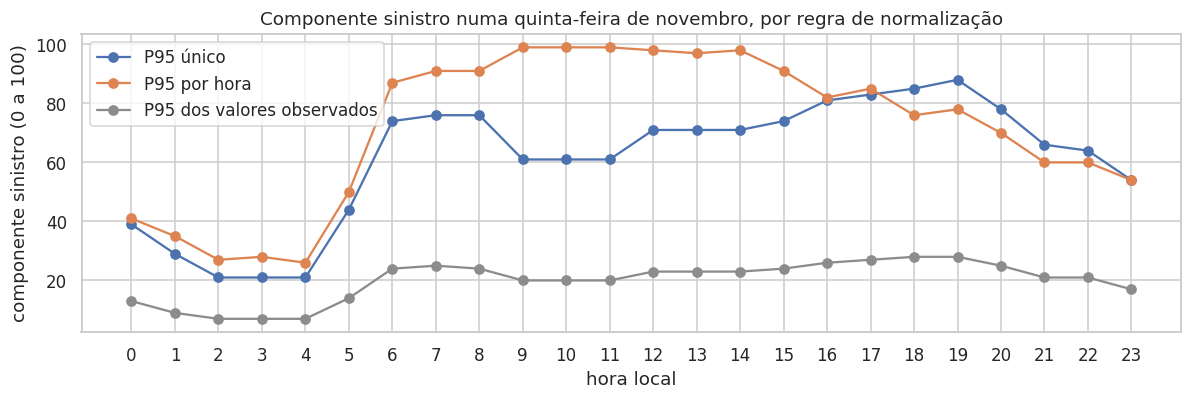

In [50]:
# Percentil 95 para normalizar o componente sinistro: único, por hora e, para comparação, dos valores observados

ARQ_P95 = DIR_MODELO / "p95_sinistros_graves.json"


def componente_sinistro(previsao, p95):
    """Contrato, seção 8: previsão / P95, limitada a 100, arredondada com 0,5 para cima."""
    return np.minimum(100, np.floor(100 * np.asarray(previsao) / p95 + 0.5)).astype(int)


hist = dados_exportacao.assign(previsto=prev_memoria)
P95_UNICO = float(np.quantile(hist["previsto"], 0.95))
P95_POR_HORA = hist.groupby("hora")["previsto"].quantile(0.95)
P95_OBSERVADO = float(np.quantile(hist[COLUNA_ALVO], 0.95))

# O que cada regra faz com um dia típico: quinta-feira de novembro, sem feriado
dia_tipico = pd.DataFrame({"hora": range(24), "dia_semana": 3, "mes": 11, "feriado": 0})
dia_tipico["previsto"] = modelo_exportado.predict(dia_tipico[VARIAVEIS_MODELO])
dia_tipico["P95 único"] = componente_sinistro(dia_tipico["previsto"], P95_UNICO)
dia_tipico["P95 por hora"] = [componente_sinistro(p, P95_POR_HORA[h]) for p, h in zip(dia_tipico["previsto"], dia_tipico["hora"])]
dia_tipico["P95 dos valores observados"] = componente_sinistro(dia_tipico["previsto"], P95_OBSERVADO)


def faixas(componente) -> pd.Series:
    """% das horas em cada faixa do Contrato (BAIXO, MODERADO, ALTO e MUITO_ALTO)."""
    rotulos = ["0 a 25", "26 a 50", "51 a 75", "76 a 100"]
    return pd.Series(pd.cut(np.asarray(componente), [-1, 25, 50, 75, 100], labels=rotulos)).value_counts(normalize=True).reindex(rotulos) * 100


distribuicao = pd.DataFrame({
    "P95 único": faixas(componente_sinistro(hist["previsto"], P95_UNICO)),
    "P95 por hora": faixas(componente_sinistro(hist["previsto"], hist["hora"].map(P95_POR_HORA))),
    "P95 dos valores observados": faixas(componente_sinistro(hist["previsto"], P95_OBSERVADO)),
})

print("=" * 70)
print("PERCENTIL 95 HISTÓRICO (previsões do modelo exportado nas horas de 2019 a 2025)")
print("=" * 70)
print(f"P95 único (todas as horas): {P95_UNICO:.4f} sinistro grave esperado por hora")
print(f"P95 por hora do dia: de {P95_POR_HORA.min():.4f} (às {P95_POR_HORA.idxmin()}h) a {P95_POR_HORA.max():.4f} (às {P95_POR_HORA.idxmax()}h)")
print(f"P95 dos valores observados (contagens inteiras): {P95_OBSERVADO:.0f}")
print("\nComponente sinistro numa quinta-feira de novembro, por regra:")
display(dia_tipico.set_index("hora")[["previsto", "P95 único", "P95 por hora", "P95 dos valores observados"]]
        .T.style.format("{:.3f}", subset=pd.IndexSlice[["previsto"], :]))
amplitude = {c: dia_tipico[c].max() - dia_tipico[c].min() for c in ["P95 único", "P95 por hora", "P95 dos valores observados"]}
print("Diferença entre a hora mais e a menos arriscada desse dia: "
      + " | ".join(f"{k}: {v} pontos" for k, v in amplitude.items()))
print("\n% das horas de 2019 a 2025 em cada faixa do componente sinistro:")
display(distribuicao.style.format("{:.1f}%"))

p95_json = {
    "metodoRecomendado": "P95_UNICO",
    "p95": round(P95_UNICO, 6),
    "unidade": "sinistros graves com moto esperados por hora na cidade de São Paulo",
    "formula": "componenteSinistro = min(100, arredondar(100 * previsao / p95)), com 0,5 arredondado para cima",
    "baseDeCalculo": f"previsões do modelo exportado nas {len(hist):,} horas locais de {ANO_INICIO} a {ANO_FIM}".replace(",", "."),
    "alternativaAvaliada": {"metodo": "P95_POR_HORA", "p95PorHora": {str(h): round(float(v), 6) for h, v in P95_POR_HORA.items()}},
    "decisao": "Pendente de registro no Contrato v1.9 (recomendação do notebook de ML: P95 único)",
}
ARQ_P95.write_text(json.dumps(p95_json, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"\nArquivo salvo: {ARQ_P95.name}")

fig, ax = plt.subplots(figsize=(11, 3.8))
for coluna, cor in [("P95 único", "#4C72B0"), ("P95 por hora", "#DD8452"), ("P95 dos valores observados", "#8C8C8C")]:
    ax.plot(dia_tipico["hora"], dia_tipico[coluna], marker="o", color=cor, label=coluna)
ax.set_xticks(range(24))
ax.set_xlabel("hora local")
ax.set_ylabel("componente sinistro (0 a 100)")
ax.set_title("Componente sinistro numa quinta-feira de novembro, por regra de normalização")
ax.legend()
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "item10_p95_componente.png", dpi=150, bbox_inches="tight")
plt.show()

### **10.4 Trechos críticos**

A rota `GET /trechos-criticos?limite=` devolve os trechos da cidade com mais sinistros graves com moto, e o Contrato pede pelo menos 50 (o limite máximo da rota). A lista sai dos mesmos sinistros usados no alvo (Item 2), de 2019 a 2025, em quatro passos:

1. **Coordenadas válidas:** ficam só as que caem dentro dos limites do município. Isso descarta coordenadas vazias, zeradas ou com sinal ou escala trocados.
2. **Logradouro padronizado:** maiúsculas, sem espaços sobrando e sem os valores que significam "não informado".
3. **Trecho = mesmo logradouro dentro de uma célula de 0,005 grau (cerca de 550 m).** Assim, uma via longa vira vários trechos, e o entregador sabe *onde* nela está o perigo. A coordenada do trecho é a mediana das coordenadas dos sinistros, que resiste melhor a um ponto mal digitado do que a média.
4. **Nome que o entregador reconhece:** o Infosiga registra as rodovias estaduais só pelo código (por exemplo, "SP 270"). Para 8 rodovias que cortam a cidade, o nome vai junto: "SP 270 (RODOVIA RAPOSO TAVARES)". O agrupamento não muda, só o texto exibido.

São exportados 100 trechos (o dobro do mínimo), em ordem decrescente de quantidade. O arquivo usa os nomes de campo em camelCase (`logradouro`, `latitude`, `longitude`, `quantidadeSinistrosGraves`), como manda a seção 2 do Contrato, e não traz nenhum dado pessoal: só contagens por local.

A figura tem três partes: o mapa da cidade com o mapa do OpenStreetMap ao fundo (dados abertos, © OpenStreetMap contributors, baixado em blocos pela biblioteca `contextily` e guardado em cache em `processados/`), uma ampliação do ponto mais crítico, onde os trechos ficam colados uns nos outros, e o ranking dos 15 primeiros, com a mesma numeração do mapa. A tabela de sinistros vem do cache do Item 2 (`eventos_alvo.parquet`), que fica fora do Git. O arquivo final versionado é o `trechos_criticos.json`.

TRECHOS CRÍTICOS
Sinistros graves com moto de 2019 a 2025: 13,028
Com coordenada dentro do município: 12,552 (96.3%)
Com logradouro informado: 12,773 (98.0%)
Com os dois (usados nos trechos): 12,436 (95.5%)
Trechos distintos: 7,168 | exportados: 100 (de 46 a 8 sinistros graves cada)
Os 100 trechos concentram 10.3% dos sinistros graves localizados

Os 15 primeiros:


,logradouro,sinistros graves,latitude,longitude
0,SP 270 (RODOVIA RAPOSO TAVARES),46,-23.58341,-46.77771
1,SP 270 (RODOVIA RAPOSO TAVARES),38,-23.58481,-46.78738
2,SP 270 (RODOVIA RAPOSO TAVARES),35,-23.58630,-46.75863
3,SP 270 (RODOVIA RAPOSO TAVARES),32,-23.58966,-46.79591
4,SP 270 (RODOVIA RAPOSO TAVARES),31,-23.58633,-46.74885
5,SP 270 (RODOVIA RAPOSO TAVARES),26,-23.58117,-46.73034
6,SP 270 (RODOVIA RAPOSO TAVARES),25,-23.58421,-46.76816
7,SP 021 (RODOANEL MÁRIO COVAS),24,-23.43922,-46.76938
8,MARGINAL RAPOSO TAVARES,22,-23.58371,-46.76945
9,SP 270 (RODOVIA RAPOSO TAVARES),22,-23.59294,-46.80499



Arquivo salvo: trechos_criticos.json (100 trechos, sem nenhum dado pessoal)


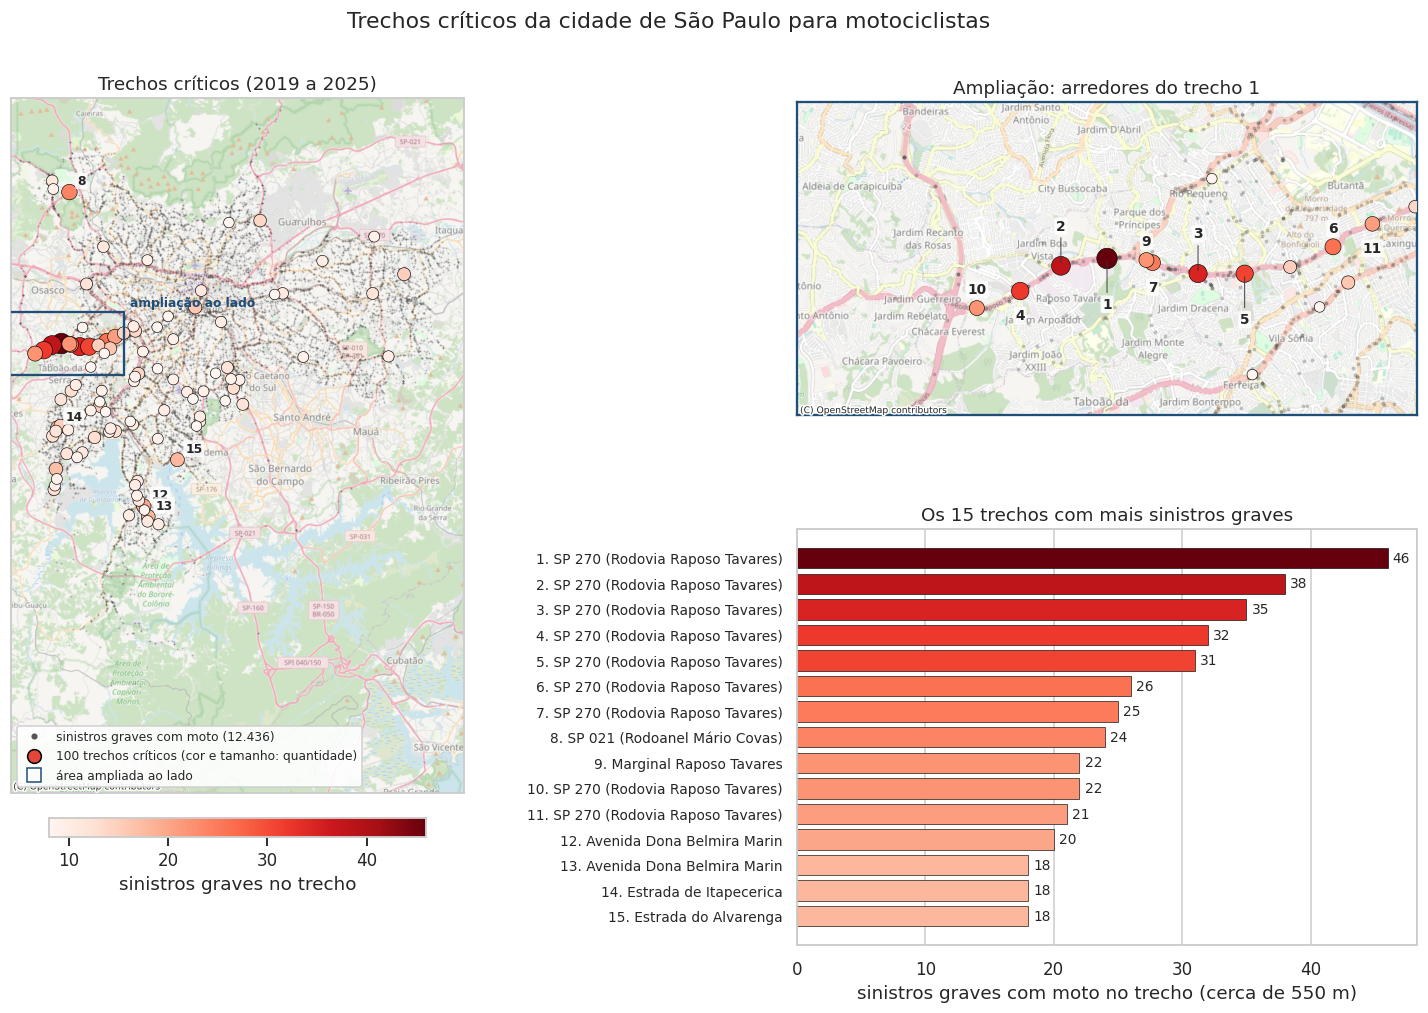

In [54]:
# Trechos críticos: logradouro + célula de cerca de 550 m, a partir dos sinistros graves com moto de 2019 a 2025

ARQ_TRECHOS = DIR_MODELO / "trechos_criticos.json"
QTD_TRECHOS = 100                 # o Contrato pede pelo menos 50 (limite máximo da rota); 100 dá folga
TAMANHO_CELULA_GRAUS = 0.005      # cerca de 550 m na latitude de São Paulo
CAIXA_SP = {"lat_min": -24.01, "lat_max": -23.35, "lon_min": -46.83, "lon_max": -46.36}   # limites do município

ARQ_EVENTOS = DIR_PROCESSADOS / "eventos_alvo.parquet"   # tabela de sinistros do Item 2 (cache local, fora do Git)
ev = pd.read_parquet(ARQ_EVENTOS)
ev = ev[ev["ano_sinistro"].between(ANO_INICIO, ANO_FIM)].copy()
total_eventos = len(ev)

# 1. Coordenadas dentro do município (descarta vazias, zeradas ou com sinal ou escala trocados)
coord_ok = (ev["latitude"].between(CAIXA_SP["lat_min"], CAIXA_SP["lat_max"])
            & ev["longitude"].between(CAIXA_SP["lon_min"], CAIXA_SP["lon_max"]))

# 2. Logradouro padronizado: maiúsculas, sem espaços sobrando, sem os valores que significam "não informado"
ev["logradouro_padrao"] = (ev["logradouro"].fillna("").astype(str).str.upper().str.strip()
                           .str.replace(r"\s+", " ", regex=True))
sem_nome = {"", "NAO DISPONIVEL", "NÃO DISPONÍVEL", "NAO INFORMADO", "NÃO INFORMADO", "NULL", "NAN", "-"}
nome_ok = ~ev["logradouro_padrao"].isin(sem_nome)

validos = ev[coord_ok & nome_ok].copy()

# Rodovias estaduais aparecem só pelo código (por exemplo, "SP 270"): o nome vai junto para o entregador reconhecer
RODOVIAS_SP = {21: "RODOANEL MÁRIO COVAS", 70: "RODOVIA AYRTON SENNA", 150: "VIA ANCHIETA", 160: "RODOVIA DOS IMIGRANTES",
               270: "RODOVIA RAPOSO TAVARES", 280: "RODOVIA CASTELLO BRANCO", 330: "RODOVIA ANHANGUERA",
               348: "RODOVIA DOS BANDEIRANTES"}


def nome_exibicao(logradouro: str) -> str:
    """Acrescenta o nome da rodovia quando o logradouro é só o código (SP 270 vira SP 270 (RODOVIA RAPOSO TAVARES))."""
    codigo = re.fullmatch(r"SP[ -]?0*(\d{1,3})", logradouro)
    if codigo and int(codigo.group(1)) in RODOVIAS_SP:
        return f"SP {int(codigo.group(1)):03d} ({RODOVIAS_SP[int(codigo.group(1))]})"
    return logradouro


# 3. Trecho = mesmo logradouro dentro da mesma célula da grade (uma via longa vira vários trechos)
validos["celula_lat"] = np.floor(validos["latitude"] / TAMANHO_CELULA_GRAUS).astype(int)
validos["celula_lon"] = np.floor(validos["longitude"] / TAMANHO_CELULA_GRAUS).astype(int)
trechos = (validos.groupby(["logradouro_padrao", "celula_lat", "celula_lon"])
           .agg(quantidade=("id_sinistro", "size"), latitude=("latitude", "median"), longitude=("longitude", "median"))
           .reset_index()
           .sort_values(["quantidade", "logradouro_padrao"], ascending=[False, True])
           .reset_index(drop=True))
top = trechos.head(QTD_TRECHOS).copy()
top["logradouro_exibicao"] = top["logradouro_padrao"].map(nome_exibicao)
assert len(top) >= 50, "o Contrato exige pelo menos 50 trechos"

print("=" * 70)
print("TRECHOS CRÍTICOS")
print("=" * 70)
print(f"Sinistros graves com moto de {ANO_INICIO} a {ANO_FIM}: {total_eventos:,}")
print(f"Com coordenada dentro do município: {coord_ok.sum():,} ({coord_ok.mean():.1%})")
print(f"Com logradouro informado: {nome_ok.sum():,} ({nome_ok.mean():.1%})")
print(f"Com os dois (usados nos trechos): {len(validos):,} ({len(validos) / total_eventos:.1%})")
print(f"Trechos distintos: {len(trechos):,} | exportados: {len(top)} "
      f"(de {top['quantidade'].max()} a {top['quantidade'].min()} sinistros graves cada)")
print(f"Os {len(top)} trechos concentram {top['quantidade'].sum() / len(validos):.1%} dos sinistros graves localizados")
print("\nOs 15 primeiros:")
display(top.head(15)[["logradouro_exibicao", "quantidade", "latitude", "longitude"]]
        .rename(columns={"logradouro_exibicao": "logradouro", "quantidade": "sinistros graves"})
        .style.format({"latitude": "{:.5f}", "longitude": "{:.5f}"}))

trechos_json = {
    "periodo": f"{ANO_INICIO} a {ANO_FIM}",
    "fonte": "Infosiga SP (sinistros com pelo menos uma motocicleta e pelo menos uma vítima grave ou fatal, cidade de São Paulo)",
    "criterio": (f"mesmo logradouro dentro de uma célula de {str(TAMANHO_CELULA_GRAUS).replace('.', ',')} grau (cerca de 550 m); "
                 "coordenada = mediana dos sinistros do trecho; ordem decrescente de quantidade"),
    "quantidadeTrechos": len(top),
    "trechos": [{"posicao": i + 1, "logradouro": r.logradouro_exibicao, "latitude": round(float(r.latitude), 5),
                 "longitude": round(float(r.longitude), 5), "quantidadeSinistrosGraves": int(r.quantidade)}
                for i, r in enumerate(top.itertuples())],
}
ARQ_TRECHOS.write_text(json.dumps(trechos_json, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"\nArquivo salvo: {ARQ_TRECHOS.name} ({len(top)} trechos, sem nenhum dado pessoal)")

# ---------------------------------------------------------------------------
# Figura: mapa de São Paulo ao fundo (OpenStreetMap), ampliação do ponto mais crítico e ranking
# ---------------------------------------------------------------------------
try:
    import contextily as ctx                                   # baixa o mapa de fundo em blocos (tiles)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "contextily"], check=True)
    import contextily as ctx

FONTE_MAPA = ctx.providers.OpenStreetMap.Mapnik               # mapa do OpenStreetMap (dados abertos, sem chave de acesso)
CABECALHO_MAPA = {"User-Agent": "HelmCare-GS-FIAP/1.0 (notebook academico de ML)"}   # a política do OSM pede identificação
ctx.set_cache_dir(str(DIR_PROCESSADOS / "cache_mapa"))         # blocos guardados no Drive: rodar de novo é rápido
RAIO_TERRA_M = 6378137.0


def para_mercator(lon, lat):
    """Converte graus (WGS 84) para metros na projeção Web Mercator, a mesma dos mapas da web."""
    x = np.radians(np.asarray(lon, dtype=float)) * RAIO_TERRA_M
    y = np.log(np.tan(np.pi / 4 + np.radians(np.asarray(lat, dtype=float)) / 2)) * RAIO_TERRA_M
    return x, y


def rotulo(nome: str) -> str:
    """Nome legível para o gráfico: só a primeira letra maiúscula, mas SP e as preposições do jeito certo."""
    nome = nome.title().replace("Sp ", "SP ")
    for preposicao in ["Da", "Das", "De", "Do", "Dos"]:
        nome = nome.replace(f" {preposicao} ", f" {preposicao.lower()} ")
    return nome


validos["x"], validos["y"] = para_mercator(validos["longitude"], validos["latitude"])
top["x"], top["y"] = para_mercator(top["longitude"], top["latitude"])
destaque = top.head(15).reset_index(drop=True)                 # os 15 primeiros recebem número no mapa e no ranking
destaque["posicao"] = destaque.index + 1

# Ampliação: cerca de 13 km por 6 km em volta do trecho 1
x0, y0 = para_mercator(destaque.loc[0, "longitude"] - 0.065, destaque.loc[0, "latitude"] - 0.03)
x1, y1 = para_mercator(destaque.loc[0, "longitude"] + 0.065, destaque.loc[0, "latitude"] + 0.03)
na_caixa = destaque["x"].between(x0, x1) & destaque["y"].between(y0, y1)
cidade_x, cidade_y = para_mercator([CAIXA_SP["lon_min"], CAIXA_SP["lon_max"]], [CAIXA_SP["lat_min"], CAIXA_SP["lat_max"]])
norm = matplotlib.colors.Normalize(top["quantidade"].min(), top["quantidade"].max())


def desenhar_mapa(eixo, limites_x, limites_y, tamanho_ponto, zoom_mapa="auto"):
    """Mapa de fundo, sinistros graves em cinza e os 100 trechos (cor e tamanho pela quantidade)."""
    eixo.set_xlim(*limites_x)
    eixo.set_ylim(*limites_y)
    eixo.set_aspect("equal", adjustable="box")
    eixo.scatter(validos["x"], validos["y"], s=tamanho_ponto, color="#555555", alpha=0.35, lw=0, zorder=2)
    pontos_trechos = eixo.scatter(top["x"], top["y"], s=20 + top["quantidade"] / top["quantidade"].max() * 160,
                                  c=top["quantidade"], cmap="Reds", norm=norm, edgecolor="black", linewidth=0.4, zorder=3)
    try:
        ctx.add_basemap(eixo, source=FONTE_MAPA, zoom=zoom_mapa, headers=CABECALHO_MAPA, attribution_size=6,
                        alpha=0.6, zorder=0)            # mapa um pouco apagado para os pontos se destacarem
    except Exception as erro:
        print(f"Mapa de fundo indisponível ({type(erro).__name__}); a figura sai só com os pontos.")
    eixo.set_xticks([])
    eixo.set_yticks([])
    eixo.grid(False)
    return pontos_trechos


fig = plt.figure(figsize=(17, 10))
grade_fig = fig.add_gridspec(2, 2, width_ratios=[1, 1.15], height_ratios=[1, 1.3], wspace=0.5, hspace=0.3)
ax = fig.add_subplot(grade_fig[:, 0])          # mapa da cidade inteira
zoom = fig.add_subplot(grade_fig[0, 1])        # ampliação do ponto mais crítico
ax_rank = fig.add_subplot(grade_fig[1, 1])     # ranking dos 15 primeiros

pontos = desenhar_mapa(ax, cidade_x, cidade_y, 1.5)
for r in destaque[~na_caixa].itertuples():               # números dos 15 primeiros que ficam fora da ampliação
    ax.annotate(str(r.posicao), (r.x, r.y), xytext=(5, 5), textcoords="offset points", fontsize=8, fontweight="bold",
                bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.85}, zorder=5)
ax.add_patch(matplotlib.patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="#1F4E79", lw=1.5, zorder=6))
ax.annotate("ampliação ao lado", (x1, y1), xytext=(4, 4), textcoords="offset points", fontsize=8, color="#1F4E79",
            fontweight="bold", zorder=6)
legenda = [matplotlib.lines.Line2D([], [], marker="o", ls="", color="#555555", markersize=3,
                                   label=f"sinistros graves com moto ({len(validos):,})".replace(",", ".")),
           matplotlib.lines.Line2D([], [], marker="o", ls="", markerfacecolor="#E3473A", markeredgecolor="black",
                                   markersize=9, label=f"{len(top)} trechos críticos (cor e tamanho: quantidade)"),
           matplotlib.lines.Line2D([], [], marker="s", ls="", markerfacecolor="none", markeredgecolor="#1F4E79",
                                   markersize=9, label="área ampliada ao lado")]
ax.legend(handles=legenda, loc="lower left", fontsize=8, framealpha=0.9)
ax.set_title(f"Trechos críticos ({ANO_INICIO} a {ANO_FIM})")
fig.colorbar(pontos, ax=ax, orientation="horizontal", shrink=0.7, pad=0.03, label="sinistros graves no trecho")

# Ampliação: os números se alternam acima e abaixo da via para não se sobreporem
desenhar_mapa(zoom, (x0, x1), (y0, y1), 6)
deslocamentos = [12, -16, 26, -30]
for i, r in enumerate(destaque[na_caixa].sort_values("x").itertuples()):
    dy = deslocamentos[i % len(deslocamentos)]
    zoom.annotate(str(r.posicao), (r.x, r.y), xytext=(0, dy), textcoords="offset points", ha="center", va="center",
                  fontsize=9, fontweight="bold", zorder=5,
                  bbox={"boxstyle": "round,pad=0.12", "fc": "white", "ec": "none", "alpha": 0.85},
                  arrowprops={"arrowstyle": "-", "color": "#333333", "lw": 0.6} if abs(dy) > 20 else None)
for borda in zoom.spines.values():
    borda.set_edgecolor("#1F4E79")
    borda.set_linewidth(1.5)
zoom.set_title("Ampliação: arredores do trecho 1")

# Ranking dos 15 primeiros, com o mesmo número do mapa
cores = plt.cm.Reds(norm(destaque["quantidade"]))
ax_rank.barh(destaque["posicao"], destaque["quantidade"], color=cores, edgecolor="black", linewidth=0.4)
ax_rank.set_yticks(destaque["posicao"])
ax_rank.set_yticklabels([f"{r.posicao}. {rotulo(r.logradouro_exibicao)}" for r in destaque.itertuples()], fontsize=9)
ax_rank.invert_yaxis()
for r in destaque.itertuples():
    ax_rank.text(r.quantidade + 0.4, r.posicao, str(r.quantidade), va="center", fontsize=9)
ax_rank.set_xlabel("sinistros graves com moto no trecho (cerca de 550 m)")
ax_rank.set_title("Os 15 trechos com mais sinistros graves")
ax_rank.grid(axis="y", visible=False)
fig.suptitle("Trechos críticos da cidade de São Paulo para motociclistas", y=0.96)
plt.savefig(DIR_FIGURAS / "item10_trechos_criticos.png", dpi=150, bbox_inches="tight")
plt.show()

### **10.5 Metadados do modelo**

O `metadados_modelo.json` é o "manual de uso" do modelo para o Serviço de Risco. Ele traz tudo o que a seção 8.1 do Contrato pede, para que o serviço monte as variáveis exatamente como o notebook montou:

- **Ordem e codificação das 4 variáveis:** `hora` (hora local, 0 a 23), `dia_semana` (0 = segunda até 6 = domingo, como o `weekday()` do Python), `mes` (1 a 12) e `feriado` (0 ou 1).
- **Conversão da requisição do `POST /indice-turno`:** o `inicio` e o `fim` chegam em UTC (seção 2 do Contrato) e são convertidos para `America/Sao_Paulo` hora a hora, o que já trata o horário de verão. Inclui o exemplo do Contrato: 20h UTC de 12/11/2026 até 0h UTC de 13/11 são as horas locais 17h, 18h, 19h e 20h de uma quinta-feira.
- **A previsão do tempo da requisição não entra no modelo.** Ela entra só nos componentes `chuva` e `calor`.
- **Feriados:** a regra (nacionais e estaduais pela biblioteca `holidays`, mais os municipais da capital e o Carnaval) e a lista explícita de datas de 2019 a 2030, com o nome de cada uma. O Serviço de Risco consulta a lista e não precisa recalcular nada.
- **Período de treino, hiperparâmetros, métricas** (validação, teste e linha de base), **limites do modelo e versões das bibliotecas.**

In [55]:
# metadados_modelo.json: tudo o que o Serviço de Risco precisa para montar as variáveis e usar o modelo

from datetime import datetime, timezone

ARQ_METADADOS = DIR_MODELO / "metadados_modelo.json"
METRICAS = ["MAE", "RMSE", "deviance_poisson", "D2", "vies_nivel"]
arred = lambda d: {k: round(float(d[k]), 4) for k in METRICAS}

metadados = {
    "nomeModelo": "modelo_sinistros_xgb",
    "versaoModelo": "1.0.0",
    "geradoEm": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "arquivoModelo": ARQ_MODELO.name,
    "comoCarregar": "xgboost.Booster(); booster.load_model('modelo_sinistros_xgb.json'); "
                    "booster.predict(xgboost.DMatrix(tabela_com_as_variaveis_na_ordem_abaixo))",
    "alvo": {
        "descricao": "quantidade esperada de sinistros graves com motocicletas na cidade de São Paulo em uma hora local",
        "definicaoSinistroGrave": "sinistro do Infosiga SP com pelo menos uma motocicleta e pelo menos uma vítima com lesão grave ou fatal",
        "unidade": "sinistros graves por hora (valor contínuo, maior ou igual a zero)",
        "tipoModelo": "XGBoost, regressão de contagem com objetivo count:poisson",
    },
    "ordemVariaveis": VARIAVEIS_MODELO,
    "variaveis": {
        "hora": {"tipo": "inteiro", "faixa": [0, 23], "descricao": "hora local de America/Sao_Paulo"},
        "dia_semana": {"tipo": "inteiro", "faixa": [0, 6], "codificacao": {str(i): d for i, d in enumerate(DIAS_SEMANA)},
                       "descricao": "dia da semana da data local (0 = segunda, como o weekday() do Python)"},
        "mes": {"tipo": "inteiro", "faixa": [1, 12], "descricao": "mês da data local"},
        "feriado": {"tipo": "inteiro", "faixa": [0, 1], "descricao": "1 se a data local está em feriados.datas, 0 caso contrário"},
    },
    "conversaoRequisicao": {
        "rota": "POST /risco/v1/indice-turno",
        "passos": [
            "1. Ler inicio e fim da requisição (ISO 8601 em UTC, seção 2 do Contrato).",
            "2. Percorrer as horas cheias em UTC a partir do inicio arredondado para baixo, enquanto a hora começar antes do fim: "
            "cada hora que se sobrepõe ao turno entra.",
            "3. Converter o início de cada hora de UTC para America/Sao_Paulo (zoneinfo), que já trata o horário de verão.",
            "4. Montar hora, dia_semana, mes e feriado a partir da data e da hora locais.",
            "5. Prever cada hora com o modelo, com as colunas na ordem de ordemVariaveis.",
            "6. Calcular o componente de cada hora: min(100, arredondar(100 * previsao / p95)), com 0,5 para cima, "
            "usando o p95 de p95_sinistros_graves.json.",
            "7. Agregar as horas do turno num único componente sinistro (média, maior valor etc.): decisão da disciplina de SOA.",
        ],
        "exemplo": {
            "requisicao": {"inicio": "2026-11-12T20:00:00Z", "fim": "2026-11-13T00:00:00Z"},
            "horasLocais": [{"horaLocal": f"2026-11-12T{h}:00:00-03:00", "hora": h, "dia_semana": 3, "mes": 11, "feriado": 0}
                            for h in (17, 18, 19, 20)],
        },
        "previsaoDoTempo": "chuvaMmHora, temperaturaC e umidadePct não entram no modelo; entram só nos componentes chuva e calor do índice",
    },
    "feriados": {
        "regra": "nacionais e estaduais de SP pela biblioteca holidays (Brazil, subdiv='SP'), mais os municipais da capital "
                 "(25/01 aniversário da cidade, Corpus Christi = Páscoa + 60 dias, 20/11 Consciência Negra) "
                 "e o Carnaval (segunda = Páscoa menos 48 dias, terça = Páscoa menos 47 dias)",
        "comoUsar": "o Serviço de Risco consulta esta lista; fora do período dela, aplicar a mesma regra",
        "periodo": f"{min(FERIADOS).year} a {max(FERIADOS).year}",
        "datas": [{"data": d.isoformat(), "nome": n} for d, n in FERIADOS.items()],
    },
    "treino": {
        "fonte": "Infosiga SP e INMET A701 (São Paulo, Mirante), dados públicos reais",
        "periodoFinal": f"{dados_exportacao['datahora_local'].min():%Y-%m-%d} a {dados_exportacao['datahora_local'].max():%Y-%m-%d}",
        "horasFinal": int(len(dados_exportacao)),
        "sinistrosGravesFinal": int(dados_exportacao[COLUNA_ALVO].sum()),
        "selecaoHiperparametros": f"GridSearchCV, 27 combinações, 5 dobras anuais expansivas dentro de {ANOS_TREINO[0]} a {ANOS_TREINO[-1]}, "
                                  "critério deviance de Poisson média na validação",
        "hiperparametros": {**MELHORES_PARAMS_CALENDARIO, "objective": "count:poisson", "tree_method": "hist", "random_state": SEED},
        "teste": f"ano de {ANO_TESTE} inteiro, avaliado uma única vez antes do retreino final",
    },
    "metricas": {
        "validacao": arred(metricas_exportado["validação (média das 5 dobras)"]),
        "teste": arred(metricas_exportado["teste (2025)"]),
        "linhaDeBaseTeste": arred(base_ref.iloc[2]),
        "linhaDeBase": "média histórica por hora e dia da semana",
    },
    "limites": [
        "O modelo não usa o ano: prevê o nível médio de 2019 a 2025 para cada horário (2025 ficou acima dessa média).",
        "É uma média da cidade inteira por hora, não a probabilidade de um entregador específico sofrer um sinistro.",
        "Não há dado de exposição (quantas motos circulavam em cada hora), então horário com mais sinistros mistura risco e movimento.",
    ],
    "versoesBibliotecas": VERSOES,
}
ARQ_METADADOS.write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")

print("=" * 70)
print("METADADOS DO MODELO")
print("=" * 70)
print(f"Arquivo salvo: {ARQ_METADADOS.name} ({ARQ_METADADOS.stat().st_size / 1024:.1f} KB)")
print(f"Ordem das variáveis: {metadados['ordemVariaveis']}")
print(f"Feriados listados: {len(metadados['feriados']['datas'])} datas ({metadados['feriados']['periodo']})")
print(f"Período do retreino final: {metadados['treino']['periodoFinal']} ({metadados['treino']['horasFinal']:,} horas)")
print(f"Hiperparâmetros: {metadados['treino']['hiperparametros']}")
print(f"Deviance de Poisson: validação {metadados['metricas']['validacao']['deviance_poisson']:.4f} | "
      f"teste {metadados['metricas']['teste']['deviance_poisson']:.4f} | "
      f"linha de base no teste {metadados['metricas']['linhaDeBaseTeste']['deviance_poisson']:.4f}")
print("\nPassos da conversão da requisição:")
for passo in metadados["conversaoRequisicao"]["passos"]:
    print(" ", passo)

METADADOS DO MODELO
Arquivo salvo: metadados_modelo.json (21.2 KB)
Ordem das variáveis: ['hora', 'dia_semana', 'mes', 'feriado']
Feriados listados: 180 datas (2019 a 2030)
Período do retreino final: 2019-01-01 a 2025-12-31 (61,368 horas)
Hiperparâmetros: {'max_depth': 5, 'learning_rate': 0.03, 'n_estimators': 200, 'objective': 'count:poisson', 'tree_method': 'hist', 'random_state': 42}
Deviance de Poisson: validação 0.6977 | teste 0.7429 | linha de base no teste 0.7485

Passos da conversão da requisição:
  1. Ler inicio e fim da requisição (ISO 8601 em UTC, seção 2 do Contrato).
  2. Percorrer as horas cheias em UTC a partir do inicio arredondado para baixo, enquanto a hora começar antes do fim: cada hora que se sobrepõe ao turno entra.
  3. Converter o início de cada hora de UTC para America/Sao_Paulo (zoneinfo), que já trata o horário de verão.
  4. Montar hora, dia_semana, mes e feriado a partir da data e da hora locais.
  5. Prever cada hora com o modelo, com as colunas na ordem de

### **10.6 Previsão hora a hora de um turno (teste de ponta a ponta)**

Esta célula faz o papel do Serviço de Risco. Ela **não usa nada da memória do notebook**: lê os 4 arquivos de `ml/modelo/` do disco e, para um turno (`inicio` e `fim` em UTC), devolve a previsão e o componente sinistro de **cada hora local** do turno. A agregação das horas num único componente (média, maior valor ou outra) é decisão da disciplina de SOA, então a célula só mostra as duas opções mais óbvias.

Casos testados, com conferências automáticas (`assert`):

| Caso | Turno em UTC | Horas locais esperadas |
|---|---|---|
| Exemplo do Contrato | 12/11/2026, 20h a 0h | 17h, 18h, 19h e 20h de quinta-feira, novembro, sem feriado |
| Virada da noite | sábado 21/11, 22h, a domingo 22/11, 5h | 19h a 23h de sábado e 0h e 1h de domingo |
| Feriado | 20/11/2026, 12h a 15h | 9h, 10h e 11h com `feriado` = 1 (Consciência Negra) |
| Fora da hora cheia | 20h30 a 21h10 | 17h e 18h (toda hora que se sobrepõe ao turno entra) |
| Horário de verão | 10/02/2019, 2h a 4h | 0h e 1h (São Paulo estava em UTC-2) |
| Fim antes do início | | recusado com erro |

In [56]:
# Previsão hora a hora de um turno, lendo só os arquivos exportados (como o Serviço de Risco fará)

from zoneinfo import ZoneInfo


def carregar_artefatos(pasta: Path) -> dict:
    """Lê os 4 arquivos de ml/modelo/ do disco, sem usar nada que está na memória do notebook."""
    booster = xgb.Booster()
    booster.load_model(pasta / "modelo_sinistros_xgb.json")
    meta = json.loads((pasta / "metadados_modelo.json").read_text(encoding="utf-8"))
    p95 = json.loads((pasta / "p95_sinistros_graves.json").read_text(encoding="utf-8"))
    trechos = json.loads((pasta / "trechos_criticos.json").read_text(encoding="utf-8"))
    return {"booster": booster, "ordem": meta["ordemVariaveis"], "p95": p95["p95"], "trechos": trechos["trechos"],
            "feriados": {pd.Timestamp(f["data"]).date() for f in meta["feriados"]["datas"]}}


def horas_do_turno(inicio_utc: str, fim_utc: str) -> list:
    """Horas locais que se sobrepõem ao turno: percorre as horas cheias em UTC e converte cada uma para São Paulo."""
    inicio, fim = pd.Timestamp(inicio_utc), pd.Timestamp(fim_utc)
    if inicio.tzinfo is None or fim.tzinfo is None:
        raise ValueError("inicio e fim precisam vir em UTC, com o Z no final (seção 2 do Contrato)")
    if fim <= inicio:
        raise ValueError("fim precisa ser depois do inicio")
    horas, h = [], inicio.floor("h")
    while h < fim:
        horas.append(h.tz_convert(ZoneInfo(FUSO_LOCAL)))
        h += pd.Timedelta(hours=1)
    return horas


def prever_horas_turno(inicio_utc: str, fim_utc: str, artefatos: dict) -> pd.DataFrame:
    """Previsão e componente sinistro de cada hora do turno; a agregação fica com a SOA."""
    horas = horas_do_turno(inicio_utc, fim_utc)
    tabela = pd.DataFrame({
        "hora_local": [h.strftime("%Y-%m-%d %H:%M %z") for h in horas],
        "hora": [h.hour for h in horas],
        "dia_semana": [h.weekday() for h in horas],
        "mes": [h.month for h in horas],
        "feriado": [int(h.date() in artefatos["feriados"]) for h in horas],
    })
    tabela["previsao"] = artefatos["booster"].predict(xgb.DMatrix(tabela[artefatos["ordem"]]))
    tabela["componente_sinistro"] = componente_sinistro(tabela["previsao"], artefatos["p95"])
    return tabela


artefatos = carregar_artefatos(DIR_MODELO)
print("=" * 70)
print("PREVISÃO HORA A HORA DO TURNO (arquivos lidos do disco)")
print("=" * 70)

casos = [
    ("Exemplo do Contrato (quinta-feira, 17h a 20h locais)", "2026-11-12T20:00:00Z", "2026-11-13T00:00:00Z"),
    ("Turno que vira a noite de sábado para domingo", "2026-11-21T22:00:00Z", "2026-11-22T05:00:00Z"),
    ("Feriado da Consciência Negra (sexta-feira, 20/11)", "2026-11-20T12:00:00Z", "2026-11-20T15:00:00Z"),
    ("Início e fim fora da hora cheia (17h30 a 18h10 locais)", "2026-11-12T20:30:00Z", "2026-11-12T21:10:00Z"),
    ("Horário de verão (domingo, 10/02/2019, quando São Paulo estava em UTC-2)", "2019-02-10T02:00:00Z", "2019-02-10T04:00:00Z"),
]
resultados_turno = {}
for nome, inicio, fim in casos:
    t = prever_horas_turno(inicio, fim, artefatos)
    resultados_turno[nome] = t
    print(f"\n{nome}: {inicio} a {fim}")
    display(t.style.format({"previsao": "{:.4f}"}).hide(axis="index"))
    print(f"Agregações possíveis do componente sinistro: média {t['componente_sinistro'].mean():.1f} | "
          f"maior valor {t['componente_sinistro'].max()}")

# Conferências automáticas dos casos
ex = resultados_turno[casos[0][0]]
assert ex["hora"].tolist() == [17, 18, 19, 20] and set(ex["dia_semana"]) == {3} and set(ex["mes"]) == {11} and ex["feriado"].sum() == 0
noite = resultados_turno[casos[1][0]]
assert noite["hora"].tolist() == [19, 20, 21, 22, 23, 0, 1] and noite["dia_semana"].tolist() == [5] * 5 + [6] * 2
assert resultados_turno[casos[2][0]]["feriado"].tolist() == [1, 1, 1]
assert resultados_turno[casos[3][0]]["hora"].tolist() == [17, 18]
assert resultados_turno[casos[4][0]]["hora"].tolist() == [0, 1], "no horário de verão, 02:00Z é meia-noite em São Paulo"
try:
    horas_do_turno("2026-11-13T00:00:00Z", "2026-11-12T20:00:00Z")
    raise AssertionError("fim antes do inicio deveria ser recusado")
except ValueError:
    pass
assert np.allclose(ex["previsao"], modelo_exportado.predict(ex[VARIAVEIS_MODELO])), "arquivo e memória precisam prever igual"
print("\nConferências: exemplo do Contrato = 17h, 18h, 19h e 20h de quinta-feira de novembro, sem feriado: OK")
print("Virada de sábado para domingo, feriado de 20/11, horários fora da hora cheia, horário de verão e fim antes do inicio: OK")

print("\nArquivos em ml/modelo/:")
for arq in sorted(DIR_MODELO.glob("*")):
    if arq.is_file() and arq.name != ".gitkeep":
        print(f"  {arq.name:<30s} {arq.stat().st_size / 1024:8.1f} KB")
print(f"Trechos críticos disponíveis para ?limite=: {len(artefatos['trechos'])} (máximo da rota: 50)")

PREVISÃO HORA A HORA DO TURNO (arquivos lidos do disco)

Exemplo do Contrato (quinta-feira, 17h a 20h locais): 2026-11-12T20:00:00Z a 2026-11-13T00:00:00Z


hora_local,hora,dia_semana,mes,feriado,previsao,componente_sinistro
2026-11-12 17:00 -0300,17,3,11,0,0.2693,83
2026-11-12 18:00 -0300,18,3,11,0,0.2751,85
2026-11-12 19:00 -0300,19,3,11,0,0.2826,88
2026-11-12 20:00 -0300,20,3,11,0,0.2532,78


Agregações possíveis do componente sinistro: média 83.5 | maior valor 88

Turno que vira a noite de sábado para domingo: 2026-11-21T22:00:00Z a 2026-11-22T05:00:00Z


hora_local,hora,dia_semana,mes,feriado,previsao,componente_sinistro
2026-11-21 19:00 -0300,19,5,11,0,0.3071,95
2026-11-21 20:00 -0300,20,5,11,0,0.3089,96
2026-11-21 21:00 -0300,21,5,11,0,0.3092,96
2026-11-21 22:00 -0300,22,5,11,0,0.2969,92
2026-11-21 23:00 -0300,23,5,11,0,0.2814,87
2026-11-22 00:00 -0300,0,6,11,0,0.2608,81
2026-11-22 01:00 -0300,1,6,11,0,0.2391,74


Agregações possíveis do componente sinistro: média 88.7 | maior valor 96

Feriado da Consciência Negra (sexta-feira, 20/11): 2026-11-20T12:00:00Z a 2026-11-20T15:00:00Z


hora_local,hora,dia_semana,mes,feriado,previsao,componente_sinistro
2026-11-20 09:00 -0300,9,4,11,1,0.1754,54
2026-11-20 10:00 -0300,10,4,11,1,0.1754,54
2026-11-20 11:00 -0300,11,4,11,1,0.1768,55


Agregações possíveis do componente sinistro: média 54.3 | maior valor 55

Início e fim fora da hora cheia (17h30 a 18h10 locais): 2026-11-12T20:30:00Z a 2026-11-12T21:10:00Z


hora_local,hora,dia_semana,mes,feriado,previsao,componente_sinistro
2026-11-12 17:00 -0300,17,3,11,0,0.2693,83
2026-11-12 18:00 -0300,18,3,11,0,0.2751,85


Agregações possíveis do componente sinistro: média 84.0 | maior valor 85

Horário de verão (domingo, 10/02/2019, quando São Paulo estava em UTC-2): 2019-02-10T02:00:00Z a 2019-02-10T04:00:00Z


hora_local,hora,dia_semana,mes,feriado,previsao,componente_sinistro
2019-02-10 00:00 -0200,0,6,2,0,0.2040,63
2019-02-10 01:00 -0200,1,6,2,0,0.2171,67


Agregações possíveis do componente sinistro: média 65.0 | maior valor 67

Conferências: exemplo do Contrato = 17h, 18h, 19h e 20h de quinta-feira de novembro, sem feriado: OK
Virada de sábado para domingo, feriado de 20/11, horários fora da hora cheia, horário de verão e fim antes do inicio: OK

Arquivos em ml/modelo/:
  metadados_modelo.json              21.2 KB
  modelo_sinistros_xgb.json         763.0 KB
  p95_sinistros_graves.json           1.0 KB
  trechos_criticos.json              17.9 KB
Trechos críticos disponíveis para ?limite=: 100 (máximo da rota: 50)


### **Discussão do Item 10**

#### **A melhor combinação não mudou, e o modelo de calendário é mais estável (10.1)**

A grade só com o calendário escolheu a mesma combinação do Item 8: profundidade 5, taxa 0,03 e 200 árvores, com deviance de validação de **0,6977**, contra 0,6990 do modelo com o tempo. Fica registrado: o retreino de 2019 a 2025 usa os mesmos hiperparâmetros. A comparação combinação por combinação reforça a escolha do modelo só com calendário por robustez:

- **o calendário fica melhor em 21 das 27 combinações.** As 6 em que fica pior são todas de profundidade 7, as árvores mais fundas, que com só 4 variáveis passam a decorar combinações raras de hora, dia e mês;
- **o gap entre treino e validação é menor nas 27 combinações.** Na mais complexa da grade (profundidade 7, taxa 0,3 e 800 árvores), a validação fica em 0,8522 contra 0,9648, e o gap cai de 0,7770 para 0,3032. Sem as variáveis do tempo, o modelo tem menos onde decorar o acaso, e uma escolha ruim de hiperparâmetros custa menos.

O modelo exportado teve deviance de 0,6852 no treino, 0,6977 na validação e **0,7429 no teste**, contra 0,6880, 0,7081 e 0,7485 da linha de base: ganho de 1,46% na validação e 0,75% no teste, com gap entre treino e validação de 0,0125 (0,0183 no modelo com o tempo).

#### **O modelo exportado e o nível de cada ano (10.2)**

Retreinado com as 61.368 horas e os 13.028 sinistros graves de 2019 a 2025, o modelo ocupa 763 KB e, lido de novo do disco, prevê exatamente como o modelo em memória, com as variáveis na ordem do metadados. Sem o ano entre as variáveis, ele prevê o mesmo nível médio para todos os anos (0,212 sinistro grave por hora). Por isso fica acima do observado nos anos mais baixos (+6,2% em 2020) e abaixo nos mais altos (-4,2% em 2024 e -9,1% em 2025). Incluir 2025 no treino reduziu só um pouco o viés desse ano (era de -9,8% no teste do Item 9). Para o Índice, isso pesa pouco: o componente sinistro compara cada hora com o P95 calculado com o próprio modelo, então o que importa é a ordem entre as horas, e o Item 9 mostrou que o modelo ordena bem (calibração com correlação de 0,972).

#### **Recomendação: P95 único (10.3)**

O P95 único das previsões é **0,3229** sinistro grave esperado por hora. Por hora, o P95 vai de 0,2006 (9h) a 0,3611 (19h). O das contagens observadas é 1. A comparação num dia típico (quinta-feira de novembro) decide a escolha:

1. **Só o P95 único mantém a ordem do risco.** O componente vai de 21 pontos (2h a 4h) a 88 (19h). Às 18h, ficam 85 pontos, contra 21 às 3h, a mesma proporção das previsões (0,275 contra 0,068, cerca de 4 vezes). É exatamente a diferença entre horários que o Contrato quer preservar.
2. **O P95 por hora inverte a ordem.** As 9h, 10h e 11h dessa quinta ganham 99 pontos, mais que as 18h (76) e as 19h (78), embora o modelo espere bem menos sinistros às 9h (0,198) do que às 18h (0,275). Isso acontece porque o P95 das 9h é o menor do dia: nos fins de semana as manhãs são calmas (Item 5), então uma manhã de dia útil já fica perto do topo da própria hora. O índice passaria a medir quanto a hora está acima do normal *dela*, e não o risco. Além disso, 63,0% de todas as horas cairiam na faixa de 76 a 100, e o componente perderia o poder de diferenciar um turno do outro.
3. **O P95 das contagens observadas não serve.** Como 95% das horas têm no máximo 1 sinistro grave, o P95 é 1, nenhuma hora passa de 28 pontos e 73,2% ficam abaixo de 25.

Com o P95 único, as horas de 2019 a 2025 se dividem em 6,7% de 0 a 25, 13,5% de 26 a 50, 47,0% de 51 a 75 e 32,8% de 76 a 100. A recomendação para a versão 1.9 do Contrato é o **P95 único de 0,3229**, já gravado no `p95_sinistros_graves.json`. Ela confirma a preferência inicial registrada no Contrato.

#### **Trechos críticos (10.4)**

Dos 13.028 sinistros graves, 12.436 (95,5%) têm coordenada dentro do município e logradouro informado. Eles formam 7.168 trechos distintos. Os 100 exportados têm de 46 a 8 sinistros graves cada.

**O corredor da Rodovia Raposo Tavares (SP 270) domina a lista.** São 9 dos 11 primeiros trechos, mais a Marginal Raposo Tavares em 9º, com até 46 sinistros graves em cerca de 550 m em 7 anos. Em seguida vêm o Rodoanel (SP 021), em 8º, e grandes vias da zona sul: a Avenida Dona Belmira Marin (12º e 13º), a Estrada de Itapecerica (14º) e a Estrada do Alvarenga (15º). O padrão é de rodovias que atravessam a cidade, com velocidade alta e tráfego pesado, e de vias longas da periferia.

Três cuidados na leitura:

- **é contagem, sem exposição:** uma via com muito movimento de motos acumula mais sinistros mesmo que o risco por viagem não seja maior;
- **o risco está espalhado:** os 100 trechos concentram só 10,3% dos sinistros graves localizados. A lista é um alerta para redobrar a atenção, não o mapa de todo o perigo. A proteção principal continua sendo o Índice do turno e o SOS;
- **os nomes seguem o registro do Infosiga:** a SP 270 e a Marginal Raposo Tavares aparecem separadas, como foram registradas.

#### **Metadados e teste de ponta a ponta (10.5 e 10.6)**

O `metadados_modelo.json` traz as 4 variáveis na ordem do modelo, a conversão de UTC para `America/Sao_Paulo`, a regra dos feriados com as 180 datas de 2019 a 2030, o período de treino, as métricas e as versões das bibliotecas. O teste leu só os arquivos do disco, como o Serviço de Risco fará, e todas as conferências passaram:

| Turno | Horas locais | Componente sinistro por hora | Média | Maior valor |
|---|---|---|---|---|
| Exemplo do Contrato (quinta, 12/11) | 17h a 20h | 83, 85, 88 e 78 | 83,5 | 88 |
| Sábado à noite (21/11) | 19h a 1h | de 74 a 96 | 88,7 | 96 |
| Feriado de 20/11 (sexta) | 9h a 11h | de 54 a 55 | 54,3 | 55 |
| Fora da hora cheia | 17h e 18h | 83 e 85 | 84,0 | 85 |
| Horário de verão (10/02/2019, UTC-2) | 0h e 1h | 63 e 67 | 65,0 | 67 |

O exemplo do Contrato cai nas horas certas (17h a 20h de quinta-feira, novembro, sem feriado), e o resultado fica na mesma faixa do valor ilustrativo de 80 usado no Contrato. O feriado aparece com um componente menor que o de uma manhã de dia útil comum (61 às 9h da quinta do 10.3), e o horário de verão de 2019 foi tratado sem nenhum ajuste manual. A diferença entre a média e o maior valor (até 8 pontos no sábado à noite) mostra o que está em jogo na agregação: o maior valor protege mais, porque destaca a pior hora do turno, e a média descreve o turno como um todo. A escolha é da disciplina de SOA.

#### **Conclusão do Item 10**

Os 4 arquivos que o Serviço de Risco precisa estão em `ml/modelo/` e foram conferidos de ponta a ponta: o modelo de calendário (o mesmo desempenho do modelo com o tempo, com menos overfitting em todas as combinações da grade), os metadados com a conversão da requisição e os feriados, o P95 único recomendado de 0,3229 e os 100 trechos críticos. A função que devolve a previsão de cada hora do turno deixa a agregação para a SOA, como prevê o Contrato.